# BT4012 Illicit-Transaction Detection: how the two final submissions were built

This notebook keeps only the steps that produced the team's two final leaderboard picks, in the order they were found. Failed and parallel experiments are left out. The one exception is the revised feature cleaning in Part 2: it was tested and **not adopted**, and it is kept because the revised validation protocol is calibrated on it.

| Final pick | File | Public LB | Built in |
|---|---|---|---|
| **1** | `sub_r0_old_tau5_8b_cross_view_q0.3.csv` | **0.95162** | Part 2, Step 8 |
| **2** | `sub_r0_base_tau5.csv` | **0.94992** | Part 1, Step 3g |
| (starting point) | `sub_r0_base.csv` | 0.93643 | Part 1, Step 3 |

The two picks use different methods, so together they hedge the private 70% of the test set.

**The story**
1. **Initial setup (Part 1, from `4012_original_full`):** data orientation and exploration, then cleaning. Removing 10 time-counter features, near-constant `feat_15` and 33 near-duplicates leaves 121 features (`r0_base`). Next come the LightGBM recipe and the baseline submission (LB 0.9364), even though short-window validation scored 0.997.
2. **Recency weighting discovered (Part 1):** a 14-step-ahead validation window exposes the gap, and time-decay weights `exp((t − t_max)/τ)` peak at τ = 5. The τ = 5 file scores **LB 0.9499 (+0.014)**.
3. **New data exploration and revised protocols (Part 2, from `4012_alternate`):** three new findings drive the second pass:
   - T1: forward-chaining is blind to the train/test boundary.
   - T2: true-label neighbour features are never available on the test set.
   - T3: unknown training rows are a different population from the test rows.

   They led to a revised cleaning, which was not adopted, and a revised validation protocol: two boundary-crossing windows plus Evaluation v2. Evaluation v2 is calibrated against two leaderboard outcomes that were already known.
4. **Cross-view pseudo-labels discovered (Part 2):** a local-feature teacher and an aggregate-feature teacher label a test row only where they agree. A student retrained on labelled plus pseudo-labelled test rows scores **LB 0.9516**.

**How to run**
- Written for Google Colab with the competition data on Drive (`train.csv`, `test.csv`, `txs_edgelist.csv`, `sample_submission.csv`). Set the environment variable `BT4012_DATA_DIR` to use a different folder.
- Every fit is cached in `DATA_DIR/cache`, using the same names and keys as the source notebooks, so an existing cache loads instantly. Set `FORCE_RETRAIN = True` (Part 1 Step 3 and Part 2 Step 3) to retrain everything.
- Submission files are written to `/content/submissions`. Run the notebook top to bottom: Part 2 reads Part 1's τ = 5 file and the feature-stability table.
- The submitted files were produced with LightGBM 4.6.0 (`deterministic=True`). Another version may change the trees slightly.

# Part 1: Initial setup and recency weighting
*Source: `4012_original_full`. Step numbers follow the source notebook, so gaps (3a, 3b, 3d, 3e and Steps 4 onward) mark experiments left out.*

In [51]:
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import roc_auc_score

DATA_DIR = os.environ.get("BT4012_DATA_DIR", "/content/drive/MyDrive/bt-4012-competition-2026")
N_PERM = 200
rng = np.random.default_rng(0)
pd.set_option("display.width", 200)


def read(name):
    df = pd.read_csv(os.path.join(DATA_DIR, name), skipinitialspace=True)
    df.columns = df.columns.str.strip()
    return df

train, test, e = read("train.csv"), read("test.csv"), read("txs_edgelist.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# DATA ORIENTATION - (PRELIMINARY EXPLORATION)

=== Shapes ===
train    141,772 rows x 168 columns
test      15,329 rows x 168 columns
edges    234,355 rows x 2 columns
non-feature columns, train: ['txId', 'time_step', 'label']
non-feature columns, test:  ['index', 'txId', 'time_step']
feature columns: train 165, test 165, identical sets: True
feature dtypes: {'float64': 165}

=== Transaction IDs ===
duplicate txIds in train: 0 | in test: 0
txIds in both train and test: 0

=== Time steps ===
train: 1-35 (35 steps) | test: 36-49 (14 steps)
overlapping steps: none

=== Labels (train) ===
raw label values: {'nan': 110537, '0.0': 27591, '1.0': 3644}
illicit 3,644 | licit 27,591 | unknown 110,537 (78.0% of train)
illicit share of labelled: 11.67% | licit-to-illicit ratio: 7.6 : 1

=== Per time step: train ===
           rows  illicit  licit  unknown  illicit_rate
time_step                                             
1          7880       17   2130     5733         0.008
2          4544       18   1099     3427         0.016
3          6

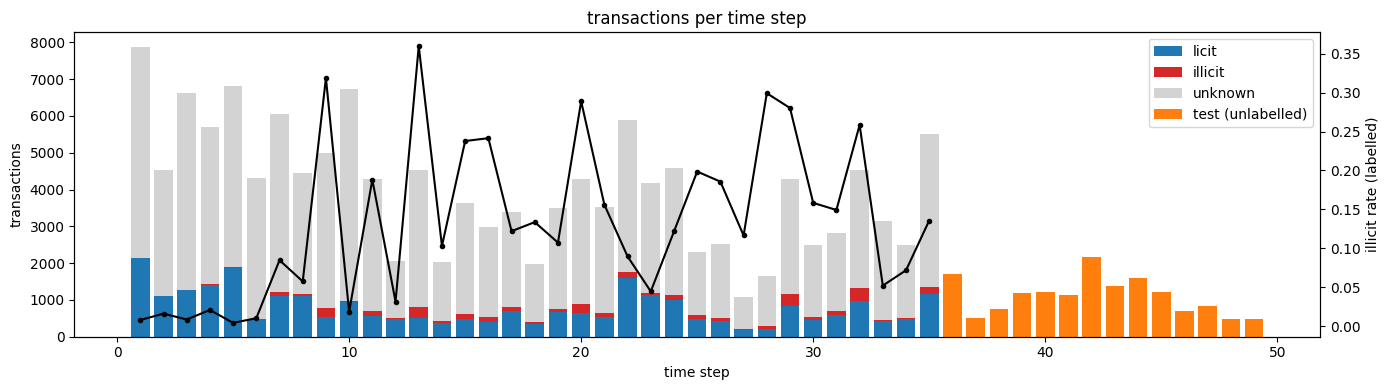

In [52]:
# ============================================================
# basic dataset statistics, train vs test
# ============================================================

train["y"] = pd.to_numeric(train["label"], errors="coerce")        # 1 illicit, 0 licit, NaN unknown
feat_tr = [c for c in train.columns if c.startswith("feat_")]
feat_te = [c for c in test.columns if c.startswith("feat_")]

# ------------------------------------------------------------ shapes and columns
print("=== Shapes ===")
for name, df in [("train", train.drop(columns="y")), ("test", test), ("edges", e)]:
    print(f"{name:6} {df.shape[0]:>9,} rows x {df.shape[1]} columns")
print("non-feature columns, train:", [c for c in train.columns if not c.startswith("feat_") and c != "y"])
print("non-feature columns, test: ", [c for c in test.columns if not c.startswith("feat_")])
print(f"feature columns: train {len(feat_tr)}, test {len(feat_te)}, identical sets: {set(feat_tr) == set(feat_te)}")
print("feature dtypes:", train[feat_tr].dtypes.astype(str).value_counts().to_dict())

# ------------------------------------------------------------ IDs
print("\n=== Transaction IDs ===")
print("duplicate txIds in train:", train.txId.duplicated().sum(), "| in test:", test.txId.duplicated().sum())
print("txIds in both train and test:", len(set(train.txId) & set(test.txId)))

# ------------------------------------------------------------ time steps
print("\n=== Time steps ===")
print(f"train: {train.time_step.min()}-{train.time_step.max()} ({train.time_step.nunique()} steps) | "
      f"test: {test.time_step.min()}-{test.time_step.max()} ({test.time_step.nunique()} steps)")
print("overlapping steps:", sorted(set(train.time_step) & set(test.time_step)) or "none")

# ------------------------------------------------------------ labels and class balance
n_ill, n_lic = int((train.y == 1).sum()), int((train.y == 0).sum())
n_unk = int(train.y.isna().sum())
print("\n=== Labels (train) ===")
print("raw label values:", train["label"].astype(str).value_counts().to_dict())
print(f"illicit {n_ill:,} | licit {n_lic:,} | unknown {n_unk:,} ({n_unk / len(train):.1%} of train)")
print(f"illicit share of labelled: {n_ill / (n_ill + n_lic):.2%} | licit-to-illicit ratio: {n_lic / max(n_ill, 1):.1f} : 1")

# ------------------------------------------------------------ per time step table
per_tr = train.groupby("time_step").agg(
    rows=("txId", "size"),
    illicit=("y", lambda s: int((s == 1).sum())),
    licit=("y", lambda s: int((s == 0).sum())),
    unknown=("y", lambda s: int(s.isna().sum())),
)
per_tr["illicit_rate"] = per_tr.illicit / (per_tr.illicit + per_tr.licit)
per_te = test.groupby("time_step").size().rename("rows")
print("\n=== Per time step: train ===")
print(per_tr.round(3).to_string())
print("\n=== Per time step: test ===")
print(per_te.to_string())
print(f"\nillicit per training step: min {per_tr.illicit.min()}, median {per_tr.illicit.median():.0f}, "
      f"max {per_tr.illicit.max()} | steps with < 20 illicit: {(per_tr.illicit < 20).sum()}")

# ------------------------------------------------------------ missing values and duplicates
print("\n=== Missing values in features ===")
for name, df, cols in [("train", train, feat_tr), ("test", test, feat_te)]:
    m = df[cols].isna().sum()
    print(f"{name}: {int(m.sum()):,} missing cells in {int((m > 0).sum())} columns"
          + (f" -> {m[m > 0].to_dict()}" if (m > 0).any() else ""))
print("duplicate feature rows: train", int(train[feat_tr].duplicated().sum()),
      "| test", int(test[feat_te].duplicated().sum()))

# ------------------------------------------------------------ feature scale overview
print("\n=== Feature value overview (summary across all feature columns) ===")
stats = pd.DataFrame({
    "train_mean": train[feat_tr].mean(), "test_mean": test[feat_tr].mean(),
    "train_std": train[feat_tr].std(), "test_std": test[feat_tr].std(),
    "train_min": train[feat_tr].min(), "train_max": train[feat_tr].max(),
})
print(stats.describe().loc[["mean", "min", "50%", "max"]].round(3).to_string())
print("constant columns (train):", [c for c in feat_tr if train[c].nunique() <= 1] or "none")

# ------------------------------------------------------------ edges
print("\n=== Edge list ===")
e = e.iloc[:, :2]; e.columns = ["src", "dst"]
ids_tr, ids_te = set(train.txId), set(test.txId)
print(f"{len(e):,} edges | duplicates: {int(e.duplicated().sum())} | self-loops: {int((e.src == e.dst).sum())}")
print(f"edges touching train: {int((e.src.isin(ids_tr) | e.dst.isin(ids_tr)).sum()):,} | "
      f"touching test: {int((e.src.isin(ids_te) | e.dst.isin(ids_te)).sum()):,}")

ids, te = set(train.txId) | set(test.txId), set(test.txId)
print("hidden predecessors of test tx:", (e.dst.isin(te) & ~e.src.isin(ids)).sum())
print("hidden successors of test tx:  ", (e.src.isin(te) & ~e.dst.isin(ids)).sum())

# ------------------------------------------------------------ hypothesis check: test.csv = labelled test tx only?
# If test.csv holds only the LABELLED test-period transactions, then test transactions can only
# "see" labelled neighbours. A labelled TRAINING transaction restricted to its labelled neighbours
# should then look similar: similar visible shares per direction, and similar counts per transaction.
print("\n=== Hypothesis check: hidden test neighbours = unknowns? ===")
e = e.iloc[:, :2].copy()
e.columns = ["src", "dst"]
y_all = pd.to_numeric(train.set_index("txId")["label"], errors="coerce")
labelled_train = set(y_all.index[y_all.notna()])
test_ids = set(test.txId)
in_files = set(train.txId) | test_ids
ts = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]]).set_index("txId").time_step


def neighbour_visibility(nodes, visible):
    pred = e[e.dst.isin(nodes)]            # edges INTO these tx: src is a predecessor
    succ = e[e.src.isin(nodes)]            # edges OUT of these tx: dst is a successor
    pv, sv = pred.src.isin(visible), succ.dst.isin(visible)
    summary = {
        "share of predecessors visible": pv.mean(),
        "share of successors visible": sv.mean(),
        "visible predecessors per tx": pv.sum() / len(nodes),
        "visible successors per tx": sv.sum() / len(nodes),
    }
    per_step = pd.DataFrame({
        "pred_visible": pv.groupby(ts.loc[pred.dst].values).mean(),
        "succ_visible": sv.groupby(ts.loc[succ.src].values).mean(),
    })
    return summary, per_step


tr_sum, tr_step = neighbour_visibility(labelled_train, labelled_train)   # train, simulated
te_sum, te_step = neighbour_visibility(test_ids, in_files)              # test, actual
print(pd.DataFrame({"train: labelled tx, labelled nbrs only": tr_sum,
                    "test: actual visible nbrs": te_sum}).round(3).to_string())

# ------------------------------------------------------------ plot
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(per_tr.index, per_tr.licit, color="tab:blue", label="licit")
ax.bar(per_tr.index, per_tr.illicit, bottom=per_tr.licit, color="tab:red", label="illicit")
ax.bar(per_tr.index, per_tr.unknown, bottom=per_tr.licit + per_tr.illicit, color="lightgrey", label="unknown")
ax.bar(per_te.index, per_te.values, color="tab:orange", label="test (unlabelled)")
ax.set_xlabel("time step"); ax.set_ylabel("transactions"); ax.legend()
ax2 = ax.twinx(); ax2.plot(per_tr.index, per_tr.illicit_rate, "k.-"); ax2.set_ylabel("illicit rate (labelled)")
ax.set_title("transactions per time step")
plt.tight_layout(); plt.show()

## Observations and Implications

### Shapes and columns
- 141,772 train rows, 15,329 test rows, 165 float features in both → no type conversion needed.
- index` column exists in `test.csv` only → it's the submission ID: keep it for the submission file (`index,target`), never use it as a feature.

### IDs and time steps
- No duplicate or shared txIds → no leakage between files.
- Train is steps 1–35, test is 36–49 → forecasting future periods; validate by time only.

### Labels and class balance
- 78% of train is unknown → only 31,235 labelled rows to train on.
- 11.7% illicit among labelled (7.6 : 1) → moderate imbalance; baseline without correction, then test `scale_pos_weight` between 1 and 7.6.

### Illicit rate varies enormously between steps
- Illicit rate ranges from 0.4% (step 5) to 36% (step 13) → the test rate is unpredictable; the model must rank well regardless.
- Steps 1–6, 10 and 12 have under 20 illicit each → keep them for training, but ignore their per-step metrics.
- Steps 9, 13, 20, 29 and 32 have 248–342 illicit each → a few periods dominate; apply soft per-step caps.
- Steps 33–34 are low (5–7%) and step 35 is 13.6% → the period just before test isn't typical either.
- Validation windows 26–28 / 29–31 / 32–35 have 205 / 518 / 584 illicit → enough for stable AUCs.
- Pooled AUC mixes steps with very different rates → report per-step and pooled AUC.

### Test size matches the *labelled* part of train
- Test steps average ~1,100 rows; training steps average ~4,050 rows but ~890 labelled → `test.csv` likely contains only the labelled test-period transactions.
- Hypothesis: Test neighbours hidden are likely the unknowns → in training, compute neighbour features from labelled neighbours only, instead of random hiding.

### Hidden edges are mostly predecessors
- 18,206 hidden predecessors vs 6,039 hidden successors → only ~41% of predecessors are visible in test, vs ~68% of successors, Backward-looking features are the most affected, not the least
- Predecessors were the most informative direction → expect predecessor features to weaken most in test unless training mimics the thinning.
- Keep predecessor and successor features separate → the model can lean on successors where predecessors are sparse.
- Total degree from the full edge list counts hidden edges → it stays comparable between train and test.
- Labelled train tx restricted to labelled neighbours: 43% / 69% visible (pred / succ) vs 41% / 68% in test → hypothesis confirmed; build training neighbour features from labelled neighbours only.

### Edges touching neither file
- 34,192 edges connect two transactions in neither file → likely links among removed test-period unknowns; unusable, but consistent with the labelled-only explanation.

### Feature distributions shift in test
- Typical column mean moves from ~0.00 to 0.08, the largest to 1.19 → apparent drift.
- Largest test std is 2.9 vs at most 1.2 in train → some columns spread far wider in test.
- At least one column has test std 0.01 → almost constant in test; identify and drop it.
- Training maxima reach 289 → heavy tails; fine for trees.
- Test is labelled-only → re-check the shift using labelled training rows before treating it as drift.

### Data quality
- No missing values → nothing to impute.
- 31 duplicate feature rows in train → negligible; check whether any have conflicting labels.

# DATA EXPLORATION (LABELED ROWS ONLY)

labelled training rows: 31,235 (illicit 3,644, licit 27,591) | test rows: 15,329

=== 1. Class separation: effect size (illicit mean - licit mean) / pooled std ===
large (|d| >= 0.8): 5 | medium (0.5-0.8): 25 | small or none (< 0.5): 135
higher in illicit: 37 | higher in licit: 128
top 15 by |effect size|:
feat_53    -1.276
feat_89    -1.074
feat_90    -1.063
feat_55    -1.062
feat_91    -0.849
feat_54    -0.749
feat_52    -0.744
feat_114   -0.660
feat_150   -0.635
feat_148    0.590
feat_100    0.586
feat_103    0.582
feat_59    -0.581
feat_65    -0.581
feat_61    -0.571

=== 2. Labelled train vs test ===
KS >= 0.3 (large shift): 21 | 0.1-0.3 (moderate): 76 | < 0.1 (small): 68
top 15 most shifted:
             ks  mean_shift  std_ratio  test_outside_train  test_std
feature                                                             
feat_101  0.995       2.374      0.354               0.995     0.252
feat_136  0.994       2.053      0.747               0.000     0.566
feat_103  0.994  

/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


removed features with |step-median rho| >= 0.7: 10 / 10
          rho_rows_train  rho_rows_train_test  rho_step_medians  rank_by_step_rho
feat_100           0.983                0.993             1.000               1.0
feat_101           0.998                0.998             1.000               1.0
feat_103           0.990                0.995             1.000               1.0
feat_136           0.993                0.993             1.000               1.0
feat_139           0.959                0.966             1.000               1.0
feat_137           0.910                0.906             1.000               1.0
feat_106           0.516                0.607             0.909               9.0
feat_109           0.462                0.611             0.869              15.0
feat_2             0.516                0.661             0.845              18.0
feat_107           0.388                0.545             0.830              20.0

NOT removed but |step-median rho| >= 0.7 

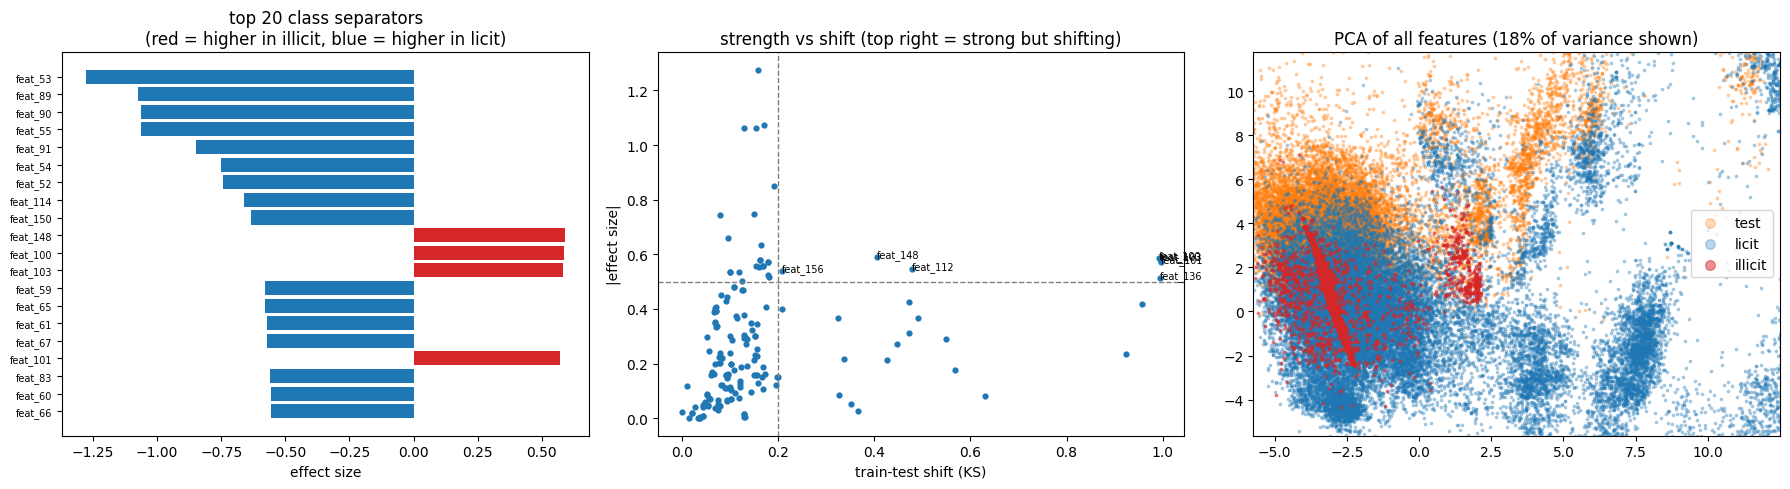

In [53]:
# ============================================================
# Simple analysis: labelled training rows only, vs test
# (assumes the setup cell: imports, read(), train, test, edges)
# ============================================================
from scipy.stats import ks_2samp
from sklearn.decomposition import PCA

# ------------------------------------------------------------ keep labelled rows only (shared tables untouched)
lab = train[train["label"].notna()].copy()
y = lab["label"].astype(int)
feat_cols = [c for c in lab.columns if c.startswith("feat_")]
print(f"labelled training rows: {len(lab):,} (illicit {y.sum():,}, licit {(y == 0).sum():,}) | test rows: {len(test):,}")

# ------------------------------------------------------------ 1. which features separate illicit from licit?
# Effect size = difference in class means divided by the pooled spread. |d| of 0.2 is small,
# 0.5 medium, 0.8+ large. Positive = higher in illicit.
ill, lic = lab.loc[y == 1, feat_cols], lab.loc[y == 0, feat_cols]
pooled = np.sqrt((ill.var() + lic.var()) / 2).replace(0, np.nan)
effect = ((ill.mean() - lic.mean()) / pooled).rename("effect_size")
print("\n=== 1. Class separation: effect size (illicit mean - licit mean) / pooled std ===")
print(f"large (|d| >= 0.8): {(effect.abs() >= 0.8).sum()} | medium (0.5-0.8): "
      f"{((effect.abs() >= 0.5) & (effect.abs() < 0.8)).sum()} | small or none (< 0.5): {(effect.abs() < 0.5).sum()}")
print(f"higher in illicit: {(effect > 0).sum()} | higher in licit: {(effect < 0).sum()}")
print("top 15 by |effect size|:")
print(effect.reindex(effect.abs().sort_values(ascending=False).index).head(15).round(3).to_string())

# ------------------------------------------------------------ 2. how different is test from labelled train?
# KS statistic = largest gap between the two distributions (0 = identical, 1 = no overlap).
rows = []
for c in feat_cols:
    a, b = lab[c].values, test[c].values
    rows.append({
        "feature": c,
        "ks": ks_2samp(a, b).statistic,
        "mean_shift": (b.mean() - a.mean()) / (a.std() or np.nan),   # in training std units
        "std_ratio": b.std() / (a.std() or np.nan),                  # >1 = wider in test
        "test_outside_train": ((b < a.min()) | (b > a.max())).mean(),
        "test_std": b.std(),
    })
shift = pd.DataFrame(rows).set_index("feature")
print("\n=== 2. Labelled train vs test ===")
print(f"KS >= 0.3 (large shift): {(shift.ks >= 0.3).sum()} | 0.1-0.3 (moderate): "
      f"{((shift.ks >= 0.1) & (shift.ks < 0.3)).sum()} | < 0.1 (small): {(shift.ks < 0.1).sum()}")
print("top 15 most shifted:")
print(shift.sort_values("ks", ascending=False).head(15).round(3).to_string())
print("\nnear-constant in test (test std < 0.05):",
      shift.index[shift.test_std < 0.05].tolist() or "none")
print("features with > 1% of test values outside the labelled-train range:",
      shift.index[shift.test_outside_train > 0.01].tolist() or "none")

# ------------------------------------------------------------ check: time-tracking features
FEATURES_ALL = [c for c in lab.columns if c.startswith("feat_")]
FEATURES_TIME = ["feat_2", "feat_100", "feat_101", "feat_103", "feat_106",
                 "feat_107", "feat_109", "feat_136", "feat_137", "feat_139"]

both = pd.concat([lab[["time_step"] + FEATURES_ALL],
                  test[["time_step"] + FEATURES_ALL]], ignore_index=True)

rho_train = lab[FEATURES_ALL].corrwith(lab.time_step, method="spearman")   # rows, steps 1-35
rho_all = both[FEATURES_ALL].corrwith(both.time_step, method="spearman")                        # rows, steps 1-49
step_median = both.groupby("time_step")[FEATURES_ALL].median()                                   # one value per step
rho_steps = step_median.corrwith(pd.Series(step_median.index, index=step_median.index), method="spearman")

time_tbl = pd.DataFrame({"rho_rows_train": rho_train, "rho_rows_train_test": rho_all,
                         "rho_step_medians": rho_steps})
time_tbl["rank_by_step_rho"] = time_tbl.rho_step_medians.abs().rank(ascending=False, method="min")

# ------------------------------------------------------------ diagnostic
FEATURES_TIME = ["feat_2", "feat_100", "feat_101", "feat_103", "feat_106",
                 "feat_107", "feat_109", "feat_136", "feat_137", "feat_139"]
STRONG = 0.7
removed_tbl = time_tbl.loc[FEATURES_TIME].sort_values("rank_by_step_rho")
others = time_tbl.drop(index=FEATURES_TIME)
missed = others[others.rho_step_medians.abs() >= STRONG].sort_values("rank_by_step_rho")

print(f"removed features with |step-median rho| >= {STRONG}: "
      f"{(removed_tbl.rho_step_medians.abs() >= STRONG).sum()} / {len(FEATURES_TIME)}")
print(removed_tbl.round(3).to_string())
print(f"\nNOT removed but |step-median rho| >= {STRONG} ({len(missed)}):")
print(missed.round(3).to_string() if len(missed) else "none")

# ------------------------------------------------------------ 3. strong AND shifted = risky
both = pd.concat([effect.abs().rename("abs_effect"), shift.ks], axis=1)
risky = both[(both.abs_effect >= 0.5) & (both.ks >= 0.2)].sort_values("abs_effect", ascending=False)
print("\n=== 3. Strong separators that also shift a lot in test (|d| >= 0.5 and KS >= 0.2) ===")
print(risky.round(3).to_string() if len(risky) else "none")

# ------------------------------------------------------------ 3b. value-count recheck: feat_112 and feat_148
# Both take only a few distinct values, so compare how often each value appears in labelled train vs test,
# with the illicit rate per value in train. Values common in test but rare in train were learned from few examples.
vc_summary = {}
for c in ["feat_112", "feat_148"]:
    tr_vals, te_vals = lab[c].round(6), test[c].round(6)
    vc = pd.DataFrame({
        "train_n": tr_vals.value_counts(),
        "train_share": tr_vals.value_counts(normalize=True),
        "test_share": te_vals.value_counts(normalize=True),
        "train_illicit_rate": y.groupby(tr_vals).mean(),
    }).fillna(0).sort_index()
    vc["test_minus_train"] = vc.test_share - vc.train_share
    vc_summary[c] = {
        "distinct_train": int((vc.train_n > 0).sum()),
        "distinct_test": int((vc.test_share > 0).sum()),
        "total_variation": 0.5 * vc.test_minus_train.abs().sum(),          # share of rows that would have to move
        "test_share_on_rare_train_values": vc.loc[vc.train_share < 0.01, "test_share"].sum(),
        "test_values_unseen_in_train": int(((vc.test_share > 0) & (vc.train_n == 0)).sum()),
    }
    print(f"\n=== 3b. {c}: value mix, labelled train vs test ===")
    print(vc.round(3).to_string())
print("\nSummary (total_variation: 0 = same mix, 1 = no overlap):")
print(pd.DataFrame(vc_summary).T.round(3).to_string())

checks = {
    "shares sum to 1 in train and test":   all(np.isclose(lab[c].round(6).value_counts(normalize=True).sum(), 1)
                                               and np.isclose(test[c].round(6).value_counts(normalize=True).sum(), 1)
                                               for c in vc_summary),
    "both columns are low-cardinality":    all(v["distinct_train"] <= 20 for v in vc_summary.values()),
    "every test value also seen in train": all(v["test_values_unseen_in_train"] == 0 for v in vc_summary.values()),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")


# ------------------------------------------------------------ 4. redundancy
corr = lab[feat_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack()
print("\n=== 4. Redundant feature pairs (labelled rows) ===")
print(f"|corr| >= 0.99: {(pairs >= 0.99).sum()} pairs | >= 0.95: {(pairs >= 0.95).sum()} pairs")
print(pairs[pairs >= 0.99].sort_values(ascending=False).head(20).round(4).to_string())

# ------------------------------------------------------------ 5. duplicate rows with conflicting labels
dup = lab[lab.duplicated(feat_cols, keep=False)]
conflicts = dup.groupby(feat_cols)["label"].nunique().gt(1).sum() if len(dup) else 0
print(f"\n=== 5. Duplicate feature rows (labelled): {len(dup)} rows | groups with conflicting labels: {conflicts}")

# ------------------------------------------------------------ plots
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

top = effect.reindex(effect.abs().sort_values(ascending=False).index).head(20)[::-1]
ax[0].barh(top.index, top.values, color=np.where(top.values > 0, "tab:red", "tab:blue"))
ax[0].set_title("top 20 class separators\n(red = higher in illicit, blue = higher in licit)")
ax[0].set_xlabel("effect size"); ax[0].tick_params(axis="y", labelsize=7)

ax[1].scatter(both.ks, both.abs_effect, s=12)
for f in risky.index[:8]:
    ax[1].annotate(f, (both.loc[f, "ks"], both.loc[f, "abs_effect"]), fontsize=7)
ax[1].axvline(0.2, ls="--", c="grey", lw=1); ax[1].axhline(0.5, ls="--", c="grey", lw=1)
ax[1].set_xlabel("train-test shift (KS)"); ax[1].set_ylabel("|effect size|")
ax[1].set_title("strength vs shift (top right = strong but shifting)")

# 2D projection of all features: do the classes separate, and where does test sit?
Z = lab[feat_cols].values
mu, sd = Z.mean(0), Z.std(0); sd[sd == 0] = 1
pca = PCA(n_components=2, random_state=0).fit((Z - mu) / sd)
P_lab = pca.transform((Z - mu) / sd)
P_te = pca.transform((test[feat_cols].values - mu) / sd)
ax[2].scatter(P_te[:, 0], P_te[:, 1], s=3, c="tab:orange", alpha=0.3, label="test")
ax[2].scatter(P_lab[y == 0, 0], P_lab[y == 0, 1], s=3, c="tab:blue", alpha=0.3, label="licit")
ax[2].scatter(P_lab[y == 1, 0], P_lab[y == 1, 1], s=3, c="tab:red", alpha=0.5, label="illicit")
ax[2].set_title(f"PCA of all features ({pca.explained_variance_ratio_.sum():.0%} of variance shown)")
lo, hi = np.percentile(np.r_[P_lab, P_te], [1, 99], axis=0)
ax[2].set_xlim(lo[0], hi[0]); ax[2].set_ylim(lo[1], hi[1])   # zoom past extreme outliers
ax[2].legend(markerscale=4)
plt.tight_layout(); plt.show()

## Observations and implications

### 1. Class separation (effect size)
- 5 large, 25 medium, 135 small/none → only ~30 features separate the classes strongly on their own; the model must combine many weak signals.
- 128 features higher in licit vs 37 in illicit, and the top 15 are mostly negative → illicit transactions tend to have lower values (less amount/activity).
- Top separators feat_53, 89, 90, 55, 91 → match the per-step stability ranking; two methods agree on the core features.
- feat_148, 100, 103 are the strongest "higher in illicit" features → 100 and 103 are suspect (see shift below).

### 2. Train vs test shift
- feat_100, 101, 103: KS ≈ 0.99, 99% of test values above the training max → trees can't extrapolate; effectively constant in test → **drop**.
- feat_136, 137, 139: KS 0.92–0.99, shifted ~1.6–2 std but within range → almost no overlap between train and test → **drop**.
- These six likely track time (values rise with time step) → confirm with Spearman correlation vs `time_step`.
- feat_137, 139 (and feat_2, 109) earlier contradicted their within-step direction → consistent with a time-tracking signal, not transaction behaviour.
- feat_100, 103 look like illicit separators → likely an artefact of illicit rates varying by period; won't transfer to test.
- feat_2, 106, 107, 109: test spread 4–6× wider, up to 6% outside the training range → second-tier drop candidates.
- 21 features with large shift, 76 moderate → much of the feature space drifts; AUC depends on within-test ranking, so moderate shifts aren't automatically harmful.
- feat_142: core feature, moderate shift (KS 0.47, 1.55× wider) → don't drop on sight; compare with and without under time-based validation.
- feat_15 nearly constant in test (and train) → **drop**.
#### Check: do these features track time? (Spearman correlation with `time_step`)
- feat_100, 101, 103, 136, 137, 139: step-median ρ = 1.000, row-level ρ 0.91–0.998 → essentially time counters; the feature *is* the time step → **drop confirmed**.
- feat_106, 109, 2, 107: step-median ρ 0.83–0.91, row-level ρ 0.39–0.52 → level drifts steadily with time while still varying per transaction; together with the wider test spread and out-of-range values → upgraded from second-tier to **drop**.
- All 10 rank among the 20 features most correlated with time → the removal set is time-driven, not just shifted by chance.

### 3. Strong separators that also shift (|d| ≥ 0.5, KS ≥ 0.2)
- feat_100, 101, 103, 136 → already on the drop list.
- feat_148, 112 (nine-value discrete columns, KS 0.41–0.48) → value mix changes in test; compare value counts train vs test, then test with/without.
- feat_156 (core feature, KS 0.21) → mild shift; keep unless validation says otherwise.
- feat_148, 112 (nine-value discrete, KS 0.41–0.48) → test moves off the dominant training value (53% → 9–15%) onto values with extreme training illicit rates: feat_112's 2.08 (16% of test, 0% illicit in train) and feat_148's 1.75/2.29 (15% of test, 54–61% illicit). → Likely to mis-rank test rows; drop on a validation tie, and test dropping both together.

### 4. Redundancy
- 36 pairs with |corr| ≥ 0.99, 91 with ≥ 0.95 → substantial redundancy; many features add no new information.
- Exact duplicates six columns apart (22–27 ↔ 28–33, 58–63 ↔ 64–69) → two repeated blocks of statistics; drop one side of each block.
- Some groups of 3+ (e.g. feat_34, 35, 37) → cluster features at |corr| ≥ 0.99 and keep one per cluster, not just one per pair.
- Duplicates split importance scores and dilute random feature sampling → pruning them makes importance readable and training slightly more efficient, with no loss of information.

### 5. Duplicate rows
- 39 duplicate labelled rows, no conflicting labels → no label noise; keep them.

raw label values in train: {'nan': 110537, '0.0': 27591, '1.0': 3644}
txIds in both train and test: 0
train time steps: 1 - 35 | test time steps: 36 - 49

edges: 234,355 total, 175,918 with both ends in the files (75.1%); share crossing time steps: 0.0000

=== Per time step ===
    split  nodes  illicit   licit  edges  mean_deg  max_deg  isolated  hidden_edge_share  components  largest_comp  unknown  illicit_rate
1   train   7880     17.0  2130.0   9164     2.326      289     0.000              0.000           1         1.000   5733.0         0.008
2   train   4544     18.0  1099.0   5241     2.307       67     0.000              0.000           1         1.000   3427.0         0.016
3   train   6621     11.0  1268.0   8316     2.512       47     0.000              0.000           1         1.000   5342.0         0.009
4   train   5693     30.0  1410.0   8180     2.874      211     0.000              0.000           1         1.000   4253.0         0.021
5   train   6803      8.0  1874

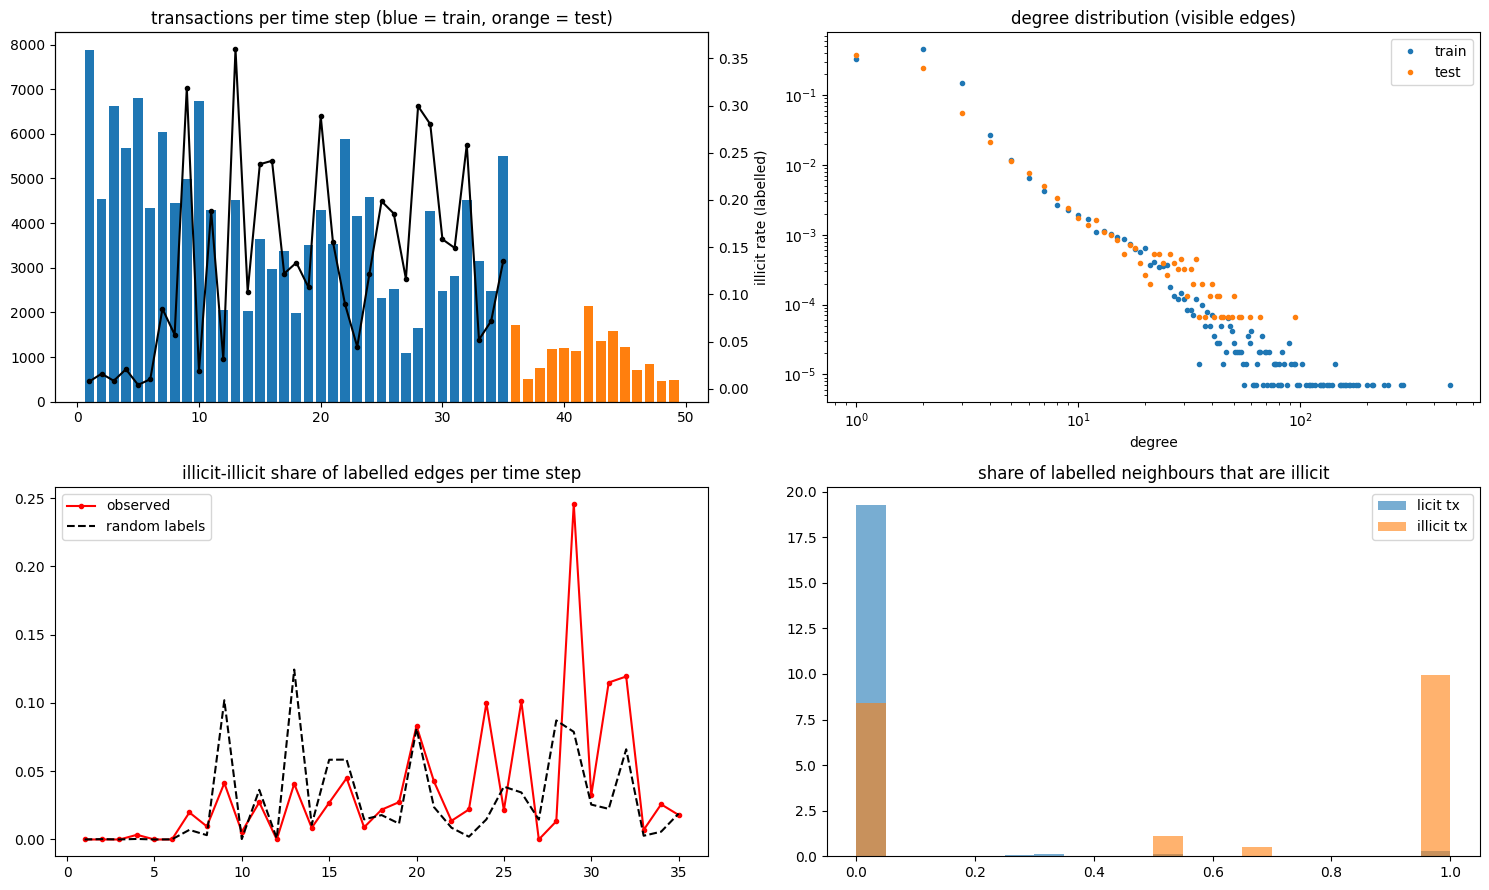

           n_illicit  isolated_share  n_illicit_total
time_step                                            
1                 14            1.00               17
2                 12            1.00               18
3                  8            1.00               11
4                 15            0.47               30
5                  3            1.00                8
6                  1            1.00                5
7                 34            0.32              102
8                 31            0.48               67
9                134            0.71              248
10                12            0.58               18
11                74            0.65              131
12                 4            1.00               16
13               164            0.74              291
14                23            0.74               43
15                43            0.47              147
16                43            0.35              128
17                39        

In [54]:
# ============================================================
# Graph structure & label homophily check
# ============================================================


e = e.iloc[:, :2].copy()
e.columns = ["src", "dst"]
e = e[e.src != e.dst].drop_duplicates()

print("raw label values in train:", train["label"].astype(str).value_counts().to_dict())
train["y"] = pd.to_numeric(train["label"], errors="coerce")          # 1 illicit, 0 licit, NaN unknown
print("txIds in both train and test:", len(set(train.txId) & set(test.txId)))
print("train time steps:", train.time_step.min(), "-", train.time_step.max(),
      "| test time steps:", test.time_step.min(), "-", test.time_step.max())

nodes = pd.concat([
    train[["txId", "time_step", "y"]].assign(split="train"),
    test[["txId", "time_step"]].assign(y=np.nan, split="test"),
]).drop_duplicates("txId").set_index("txId")
n = len(nodes)

# ------------------------------------------------------------ edges and degrees
vis = e[e.src.isin(nodes.index) & e.dst.isin(nodes.index)].copy()
vis["ts"] = nodes.time_step.loc[vis.src].values
cross = (vis.ts.values != nodes.time_step.loc[vis.dst].values).mean()
print(f"\nedges: {len(e):,} total, {len(vis):,} with both ends in the files "
      f"({len(vis) / len(e):.1%}); share crossing time steps: {cross:.4f}")

nodes["in_deg"] = vis.groupby("dst").size().reindex(nodes.index, fill_value=0)
nodes["out_deg"] = vis.groupby("src").size().reindex(nodes.index, fill_value=0)
nodes["deg"] = nodes.in_deg + nodes.out_deg
raw_deg = pd.concat([e.src, e.dst]).value_counts().reindex(nodes.index, fill_value=0)
nodes["hidden_deg"] = raw_deg - nodes.deg          # edges to transactions not in the files

pos = pd.Series(np.arange(n), index=nodes.index)
A = coo_matrix((np.ones(len(vis)), (pos.loc[vis.src].values, pos.loc[vis.dst].values)), shape=(n, n))
_, nodes["comp"] = connected_components(A, directed=False)
nodes["comp_size"] = nodes.comp.map(nodes.comp.value_counts())

# ------------------------------------------------------------ per time step table
g = nodes.groupby("time_step")
per = pd.DataFrame({
    "split": g.split.first(),
    "nodes": g.size(),
    "illicit": g.y.apply(lambda s: (s == 1).sum()),
    "licit": g.y.apply(lambda s: (s == 0).sum()),
    "edges": vis.groupby("ts").size(),
    "mean_deg": g.deg.mean(),
    "max_deg": g.deg.max(),
    "isolated": g.deg.apply(lambda s: (s == 0).mean()),
    "hidden_edge_share": g.hidden_deg.sum() / (g.hidden_deg.sum() + g.deg.sum()),
    "components": g.comp.nunique(),
    "largest_comp": g.comp.apply(lambda s: s.value_counts().iloc[0] / len(s)),
}).fillna({"edges": 0})
per["unknown"] = per.nodes - per.illicit - per.licit
per["illicit_rate"] = per.illicit / (per.illicit + per.licit)
per.loc[per.split == "test", ["illicit", "licit", "unknown", "illicit_rate"]] = np.nan
print("\n=== Per time step ===")
print(per.round(3).to_string())

print("\n=== Degree distribution (visible edges), train vs test ===")
print(nodes.groupby("split")[["in_deg", "out_deg", "deg", "hidden_deg", "comp_size"]]
      .describe(percentiles=[.5, .9, .99]).T.unstack(level=1).round(2).to_string())

# ------------------------------------------------------------ edge-level homophily
lab = nodes.y
L = vis[vis.src.map(lab).notna() & vis.dst.map(lab).notna()].copy()
L["ys"], L["yd"] = lab.loc[L.src].values, lab.loc[L.dst].values
print(f"\n=== Edges between two labelled transactions: {len(L):,} ===")
print(pd.crosstab(L.ys.map({0: "licit", 1: "illicit"}).rename("from"),
                  L.yd.map({0: "licit", 1: "illicit"}).rename("to")).to_string())

labelled = nodes[lab.notna()]
lpos = pd.Series(np.arange(len(labelled)), index=labelled.index)
si, di = lpos.loc[L.src].values, lpos.loc[L.dst].values
y0 = labelled.y.values.astype(int)
ts_codes, ts_vals = pd.factorize(L.ts, sort=True)
groups = [np.where(labelled.time_step.values == t)[0] for t in np.unique(labelled.time_step)]


def edge_stats(y):
    a, b = y[si], y[di]
    ii = (a == 1) & (b == 1)
    return ii.mean(), (a != b).mean(), np.bincount(ts_codes, ii, len(ts_vals)) / np.bincount(ts_codes, minlength=len(ts_vals))


obs_ii, obs_mix, obs_ii_ts = edge_stats(y0)
null = []
for _ in range(N_PERM):                         # shuffle labels within each time step, keep the graph
    y = y0.copy()
    for ix in groups:
        y[ix] = rng.permutation(y[ix])
    null.append(edge_stats(y))
null_ii = np.array([x[0] for x in null]); null_mix = np.array([x[1] for x in null])
null_ii_ts = np.vstack([x[2] for x in null]).mean(0)
print(f"illicit-illicit edge share: observed {obs_ii:.4f} vs random {null_ii.mean():.4f} "
      f"(x{obs_ii / max(null_ii.mean(), 1e-12):.1f}, p={np.mean(null_ii >= obs_ii):.3f})")
print(f"mixed (illicit-licit) edge share: observed {obs_mix:.4f} vs random {null_mix.mean():.4f} "
      f"(p={np.mean(null_mix <= obs_mix):.3f})")

# ------------------------------------------------------------ node-level: what do neighbours look like?
def neighbour_labels(tab, name):
    t = tab.assign(nb_lab=tab.nb.map(lab).notna(), nb_ill=(tab.nb.map(lab) == 1))
    s = t.groupby("node")[["nb_lab", "nb_ill"]].sum().reindex(nodes.index, fill_value=0)
    return s.rename(columns={"nb_lab": f"{name}_lab_nb", "nb_ill": f"{name}_ill_nb"})


nb_in = neighbour_labels(vis.rename(columns={"dst": "node", "src": "nb"}), "in")    # predecessors
nb_out = neighbour_labels(vis.rename(columns={"src": "node", "dst": "nb"}), "out")  # successors
nodes = nodes.join(nb_in).join(nb_out)
nodes["all_lab_nb"] = nodes.in_lab_nb + nodes.out_lab_nb
nodes["all_ill_nb"] = nodes.in_ill_nb + nodes.out_ill_nb

tl = nodes[nodes.y.notna()].copy()
print("\n=== Labelled transactions: neighbour coverage ===")
print(f"no visible neighbours at all:          {(tl.deg == 0).mean():.3f}")
print(f"neighbours, but none of them labelled:  {((tl.deg > 0) & (tl.all_lab_nb == 0)).mean():.3f}")
print(f">=1 labelled neighbour:                {(tl.all_lab_nb > 0).mean():.3f}")

print("\n=== Share of labelled neighbours that are illicit, by the transaction's own label ===")
for d in ["in", "out", "all"]:
    m = tl[f"{d}_lab_nb"] > 0
    share = tl.loc[m, f"{d}_ill_nb"] / tl.loc[m, f"{d}_lab_nb"]
    by = share.groupby(tl.loc[m, "y"]).mean()
    auc = roc_auc_score(tl.loc[m, "y"], share) if tl.loc[m, "y"].nunique() == 2 else np.nan
    print(f"{d:>3} neighbours: licit tx {by.get(0, np.nan):.3f} | illicit tx {by.get(1, np.nan):.3f} "
          f"| AUC {auc:.3f} (n={m.sum():,})")
print("(uses true neighbour labels: exploratory only, test transactions never have labelled neighbours)")

# ------------------------------------------------------------ do structural features separate the classes?
def auc_by_step(col):
    out = []
    for _, d in tl.groupby("time_step"):
        if d.y.nunique() == 2 and (d.y == 1).sum() >= 5:
            out.append(roc_auc_score(d.y, d[col]))
    return np.array(out)


print("\n=== Structural features: AUC for illicit (0.5 = useless; <0.5 means higher = more licit) ===")
rows = []
for col in ["in_deg", "out_deg", "deg", "hidden_deg", "comp_size"]:
    s = auc_by_step(col)
    rows.append({"feature": col, "auc_overall": roc_auc_score(tl.y, tl[col]),
                 "auc_step_mean": s.mean(), "auc_step_min": s.min(), "auc_step_max": s.max()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ------------------------------------------------------------ plots
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
c = per.split.map({"train": "tab:blue", "test": "tab:orange"})
ax[0, 0].bar(per.index, per.nodes, color=c)
ax[0, 0].set_title("transactions per time step (blue = train, orange = test)")
ax2 = ax[0, 0].twinx(); ax2.plot(per.index, per.illicit_rate, "k.-"); ax2.set_ylabel("illicit rate (labelled)")

for sp, col in [("train", "tab:blue"), ("test", "tab:orange")]:
    d = nodes.loc[nodes.split == sp, "deg"]
    vc = d[d > 0].value_counts().sort_index()
    ax[0, 1].loglog(vc.index, vc.values / len(d), ".", color=col, label=sp)
ax[0, 1].set_title("degree distribution (visible edges)"); ax[0, 1].set_xlabel("degree"); ax[0, 1].legend()

ax[1, 0].plot(ts_vals, obs_ii_ts, "r.-", label="observed")
ax[1, 0].plot(ts_vals, null_ii_ts, "k--", label="random labels")
ax[1, 0].set_title("illicit-illicit share of labelled edges per time step"); ax[1, 0].legend()

m = tl.all_lab_nb > 0
sh = tl.loc[m, "all_ill_nb"] / tl.loc[m, "all_lab_nb"]
bins = np.linspace(0, 1, 21)
ax[1, 1].hist(sh[tl.loc[m, "y"] == 0], bins, alpha=.6, density=True, label="licit tx")
ax[1, 1].hist(sh[tl.loc[m, "y"] == 1], bins, alpha=.6, density=True, label="illicit tx")
ax[1, 1].set_title("share of labelled neighbours that are illicit"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

# the share of illicit transactions with no illicit neighbours, per step:
m = tl.all_lab_nb > 0
ill = tl[m & (tl.y == 1)].assign(share=lambda d: d.all_ill_nb / d.all_lab_nb)
summary = ill.groupby("time_step").agg(
    n_illicit=("share", "size"),                              # illicit tx with >=1 labelled neighbour
    isolated_share=("share", lambda s: (s == 0).mean()),       # of those, share with no illicit neighbours
)
summary["n_illicit_total"] = tl[tl.y == 1].groupby("time_step").size()   # all illicit tx in the step
print(summary.round(2).to_string())

## Graph structure & homophily

### 1. Strong homophily, strongest through predecessors
- Illicit transactions' labelled predecessors are 69% illicit, vs 0.9% for licit transactions (AUC 0.84); successors are weaker (AUC 0.79).
  → Neighbour-score features are the most promising addition: two-stage, out-of-fold, predecessors and successors kept separate.
- Neighbourhoods are almost always pure: 96% of licit transactions have no illicit neighbours.
  → Use max / count-above-threshold of neighbour scores, not just the mean. Touching anything suspicious is the key signal.

### 2. The test graph is heavily thinned, and now we know why
- Train: every step is one connected graph with no isolated transactions. Test: mean degree 1.66 vs 2.30, 11–48% isolated per step, hundreds of components, and 32–69% of edges hidden.
  → Explained by `test.csv` containing only labelled transactions (confirmed: labelled-only train neighbourhoods match test visibility, 43% / 69% vs 41% / 68%).
  → Build training neighbour features from labelled neighbours only. Never use visible degree, `comp_size` or `hidden_deg`; total degree from the full edge list is the only graph count comparable across train and test.
- Some test steps are especially sparse (step 46: 48% isolated; step 42: 42%).
  → Neighbour features will be missing for a large share of test transactions, so own features must carry the model.

### 3. The neighbour signal's value varies by period; structure alone is weak
- The share of illicit transactions with no illicit neighbours swings from 0.10 to 0.74 between well-populated steps (heavily clustered in 23–32, scattered in 9–13).
  → Neighbour features will help a lot in some periods and little in others; validate on several windows and report per-step AUC.
- Degree AUC ranges 0.16–0.63 across steps, flipping direction; `comp_size` is constant within steps (pure time-step proxy).
  → Treat degree as optional (keep only if a with/without comparison favours it); drop `comp_size` and `hidden_deg`.

## Feature predictive power per time step

165 features | 31,235 labelled rows | 28 of 35 time steps have >= 20 of each class
skipped steps (too few of one class): [1, 2, 3, 5, 6, 10, 12]

=== Categories ===
category
moderate        71
weak            35
core            25
erratic         20
between_step    10
fading           4

=== Top 25 by mean per-step AUC ===
         higher_means  pooled_auc  mean_auc  std_auc  second_min_auc  consistency  n_reversed  early_mean  late_mean  trend_per_10_steps  category
feat_53         licit       0.857     0.861    0.124           0.607        0.964           0       0.866      0.851               0.003      core
feat_55         licit       0.840     0.854    0.139           0.559        0.964           0       0.861      0.840               0.000      core
feat_41         licit       0.807     0.853    0.138           0.545        1.000           0       0.869      0.823              -0.014  moderate
feat_47         licit       0.807     0.852    0.139           0.542        1.000      

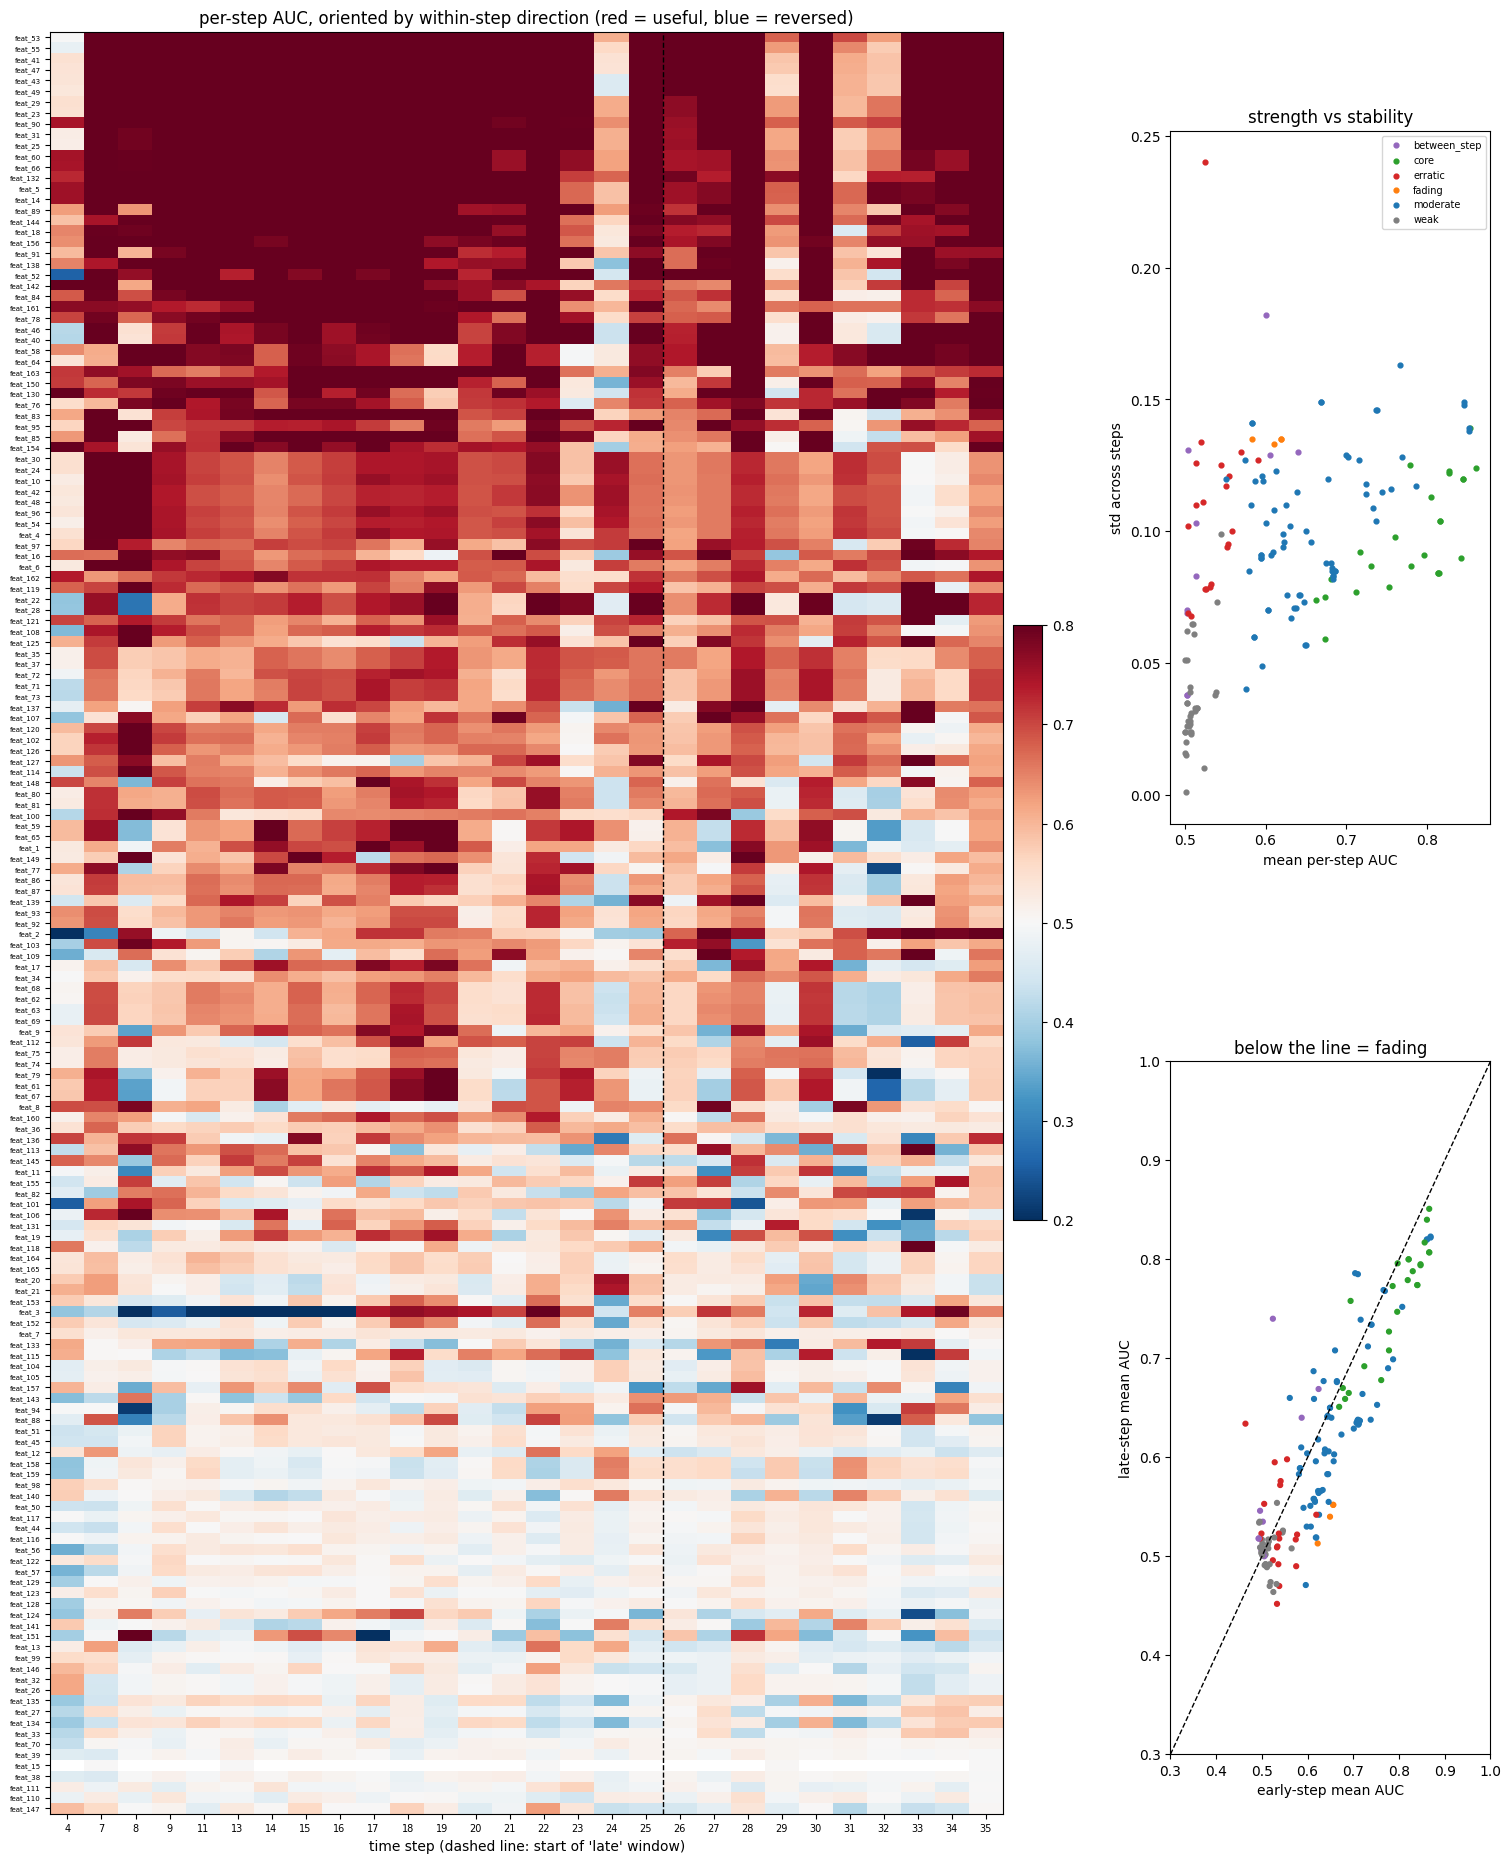

In [55]:
# ============================================================
# Feature predictive power per time step (v2)
# (assumes the setup cell: imports, DATA_DIR, read(), train, test, edges)
# Uses only local names prefixed fs_ or clearly scoped, so shared variables
# (train, lab, y, X, feat_cols) are never overwritten.
# ============================================================

MIN_CLASS = 20     # a time step is scored only if it has at least this many illicit AND licit tx
LATE_STEPS = 10    # "late" = the last N scored training steps (closest to the test period)
OUT_CSV = "/content/feature_stability.csv"

# ------------------------------------------------------------ labelled training rows (shared `train` untouched)
fs_lab = train[train["label"].notna()].copy()
fs_y = fs_lab["label"].astype(int)
fs_feats = [c for c in fs_lab.columns if c.startswith("feat_")]

counts = fs_lab.groupby("time_step")["label"].agg(illicit="sum", n="size")
counts["licit"] = counts.n - counts.illicit
steps = counts.index[(counts.illicit >= MIN_CLASS) & (counts.licit >= MIN_CLASS)].values
print(f"{len(fs_feats)} features | {len(fs_lab):,} labelled rows | "
      f"{len(steps)} of {len(counts)} time steps have >= {MIN_CLASS} of each class")
print("skipped steps (too few of one class):", sorted(set(counts.index) - set(steps)))


def safe_auc(yv, xv):
    m = ~np.isnan(xv)
    if m.sum() < 2 or len(np.unique(yv[m])) < 2 or np.all(xv[m] == xv[m][0]):
        return np.nan                     # undefined: missing values, one class, or constant feature
    return roc_auc_score(yv[m], xv[m])


# ------------------------------------------------------------ AUC of every feature in every step
A = np.full((len(fs_feats), len(steps)), np.nan)
for j, t in enumerate(steps):
    d = fs_lab[fs_lab.time_step == t]
    yv = d["label"].values.astype(int)
    Xv = d[fs_feats].values.astype(float)
    for i in range(len(fs_feats)):
        A[i, j] = safe_auc(yv, Xv[:, i])
auc_raw = pd.DataFrame(A, index=fs_feats, columns=steps)

# ------------------------------------------------------------ orient by WITHIN-step direction
# Each feature is flipped so that its typical within-step relationship points "up" (> 0.5).
# The pooled (all steps together) direction is kept separately: when the two disagree, the
# pooled signal comes from differences BETWEEN time steps, which won't transfer to new steps.
within_flip = auc_raw.mean(axis=1) < 0.5
auc = auc_raw.copy()
auc.loc[within_flip] = 1 - auc.loc[within_flip]

pooled = pd.Series({c: safe_auc(fs_y.values, fs_lab[c].values.astype(float)) for c in fs_feats})
pooled_oriented = pooled.where(~within_flip, 1 - pooled)          # same orientation as `auc`
direction_conflict = (pooled_oriented < 0.5) & (pooled - 0.5).abs().gt(0.02)

# How much a useless feature's AUC wobbles by chance in each step (null standard error)
n1 = counts.loc[steps, "illicit"].values; n0 = counts.loc[steps, "licit"].values
noise_se = pd.Series(np.sqrt((n1 + n0 + 1) / (12 * n1 * n0)), index=steps)

late, early = steps[-LATE_STEPS:], steps[:-LATE_STEPS]


def second_min(r):
    v = r.dropna()
    return np.nan if v.empty else v.nsmallest(2).iloc[-1]


def trend(r):
    ok = r.notna().values
    return np.polyfit(steps[ok], r.values[ok], 1)[0] * 10 if ok.sum() >= 3 else np.nan


stab = pd.DataFrame({
    "higher_means": np.where(within_flip, "licit", "illicit"),  # WITHIN-step direction (use for monotone constraints)
    "pooled_auc": pooled_oriented,                        # all steps pooled, same orientation
    "direction_conflict": direction_conflict,             # pooled direction contradicts within-step
    "pooled_minus_within": pooled_oriented - auc.mean(axis=1),  # far from 0 = between-step effects
    "mean_auc": auc.mean(axis=1),                         # typical strength within a step
    "std_auc": auc.std(axis=1),                           # step-to-step variability
    "chance_std": auc.notna().mul(noise_se, axis=1).sum(axis=1) / auc.notna().sum(axis=1),
    "min_auc": auc.min(axis=1),
    "second_min_auc": auc.apply(second_min, axis=1),      # worst step ignoring one outlier
    "consistency": (auc > 0.5).mean(axis=1),              # share of steps pointing the usual way
    "n_reversed": auc.lt(0.5 - 2 * noise_se, axis=1).sum(axis=1),  # reversals beyond chance
    "early_mean": auc[early].mean(axis=1),
    "late_mean": auc[late].mean(axis=1),                  # strength closest to the test period
    "trend_per_10_steps": auc.apply(trend, axis=1),
})

N_REV_ERRATIC = max(3, round(0.15 * len(steps)))


def category(r):
    # Rules of thumb: adjust thresholds after looking at the table.
    if pd.isna(r.mean_auc):
        return "undefined"      # constant or missing in every step
    if r.direction_conflict:
        return "between_step"   # pooled signal contradicts within-step signal
    if r.mean_auc >= 0.65 and r.late_mean >= 0.62 and r.second_min_auc >= 0.55 and r.n_reversed == 0:
        return "core"           # strong throughout, at most one weak step, never reversed
    if r.early_mean >= 0.6 and r.late_mean < r.early_mean - 0.1:
        return "fading"         # was useful, clearly weaker in recent steps
    if r.mean_auc < 0.55 and r.n_reversed < N_REV_ERRATIC:
        return "weak"           # noise level: low consistency is chance, not real flipping
    if r.n_reversed >= N_REV_ERRATIC:
        return "erratic"        # genuinely changes direction
    return "moderate"


stab["category"] = stab.apply(category, axis=1)
stab = stab.sort_values("mean_auc", ascending=False).round(3)
stab.to_csv(OUT_CSV)

# drop order: 1 = drop first; within a group, weakest first
PRIORITY = {"undefined": 0, "between_step": 1, "weak": 2, "erratic": 3, "fading": 4}
drop_order = (stab[stab.category.isin(PRIORITY)]
              .assign(priority=lambda d: d.category.map(PRIORITY))
              .sort_values(["priority", "mean_auc"]))

# ------------------------------------------------------------ summaries
show = ["higher_means", "pooled_auc", "mean_auc", "std_auc", "second_min_auc", "consistency",
        "n_reversed", "early_mean", "late_mean", "trend_per_10_steps", "category"]
print("\n=== Categories ===")
print(stab.category.value_counts().to_string())
print("\n=== Top 25 by mean per-step AUC ===")
print(stab[show].head(25).to_string())
for cat in ["between_step", "erratic", "fading", "weak", "undefined"]:
    sub = stab[stab.category == cat]
    print(f"\n=== {cat} ({len(sub)}) ===")
    print(sub[show].to_string() if len(sub) else "none")

gap = stab.pooled_minus_within
gap = gap[gap.abs() > 0.05].sort_values()
print("\n=== Pooled vs within-step AUC differ by > 0.05 (between-step differences inflate or mask the signal) ===")
print(gap.round(3).to_string() if len(gap) else "none")
print(f"\ndrop candidates in priority order: `drop_order` ({len(drop_order)} features)")
print(f"full table saved to {OUT_CSV} (in memory: `stab`, per-step AUCs `auc`, raw `auc_raw`)")

# ------------------------------------------------------------ plots
order = stab.index
fig = plt.figure(figsize=(16, max(10, len(order) * 0.12)))
ax = fig.add_axes([0.08, 0.05, 0.62, 0.9])
im = ax.imshow(auc.loc[order].values, aspect="auto", cmap="RdBu_r", vmin=0.2, vmax=0.8,
               interpolation="nearest")
ax.set_xticks(range(len(steps))); ax.set_xticklabels(steps, fontsize=7)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=5)
ax.axvline(len(early) - 0.5, color="black", lw=1, ls="--")
ax.set_xlabel("time step (dashed line: start of 'late' window)")
ax.set_title("per-step AUC, oriented by within-step direction (red = useful, blue = reversed)")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)

colors = {"core": "tab:green", "moderate": "tab:blue", "fading": "tab:orange",
          "erratic": "tab:red", "weak": "tab:gray", "between_step": "tab:purple", "undefined": "black"}
ax2 = fig.add_axes([0.78, 0.55, 0.2, 0.35])
for cat, g in stab.groupby("category"):
    ax2.scatter(g.mean_auc, g.std_auc, s=12, color=colors.get(cat, "k"), label=cat)
ax2.set_xlabel("mean per-step AUC"); ax2.set_ylabel("std across steps")
ax2.set_title("strength vs stability"); ax2.legend(fontsize=7)

ax3 = fig.add_axes([0.78, 0.08, 0.2, 0.35])
ax3.scatter(stab.early_mean, stab.late_mean, s=12, c=[colors.get(c, "k") for c in stab.category])
lims = [0.3, 1.0]; ax3.plot(lims, lims, "k--", lw=1)
ax3.set_xlim(lims); ax3.set_ylim(lims)
ax3.set_xlabel("early-step mean AUC"); ax3.set_ylabel("late-step mean AUC")
ax3.set_title("below the line = fading")
plt.show()

## 1. Feature categories: meaning and drop priority

| Category | Count | Meaning | Drop priority |
|---|---|---|---|
| core | 25 | strong within every step (mean ≥ 0.65, second-worst step ≥ 0.55, late ≥ 0.62, never reversed) | keep |
| moderate | 71 | useful but misses a core threshold | keep |
| between_step | 10 | pooled direction contradicts within-step direction | 1st |
| weak | 35 | little or no within-step signal (mean < 0.55) | 2nd |
| erratic | 20 | changes direction beyond chance (≥ 4 significant reversals) | 3rd |
| fading | 4 | useful early, clearly weaker in the last 10 steps | 4th |

- 96 features kept (core + moderate), 69 drop candidates → trim in rounds: drop between_step → + weak → + erratic → + fading, comparing validation AUC after each round.
- Core: mean 0.76–0.86, all but feat_142 "higher = licit" → the model's backbone; includes duplicate pairs (23/29, 25/31, 60/66, 5/14), so ~21 unique features.
- Moderate includes some of the strongest features (feat_41/47, 43/49, mean ~0.85) that miss core only on second-worst step (0.53–0.545) → moderate ≠ lower quality; keep.
- between_step splits into two kinds:
  - feat_137, 139, 2: real within-step signal (0.60–0.64) but pooled reversed (0.36–0.46) → also heavily shifted in test (KS 0.63–0.96) → drop.
  - feat_143, 94, 151, 135, 134, 27/33: no within-step signal (~0.50–0.51), pooled signal only from period differences → drop.
- Weak: mean 0.50–0.545, many exactly 0.50 (feat_15, 38, 39, 110, 111) → pure noise, lowest-risk removal; top of the group (feat_131, 118, 164/165 ~0.54) is borderline.
- Erratic: mean 0.50–0.59 with 4–11 reversals → unreliable. Exception to watch: feat_3 (11 reversals, but early 0.46 → late 0.63) is strengthening near the test period.
- Fading: feat_59/65 (duplicates), 77, 79 fall from ~0.62–0.66 early to ~0.51–0.55 late → little signal left near test; drop last.
- feat_84 (moderate) drops 0.79 → 0.70, just under the fading threshold → watch.
- Time-tracking features from the shift analysis (feat_100, 101, 103, 106, 107, 109, 136) are dropped regardless of category → treat as a separate, first drop group.

## 2. Pooled vs within-step AUC

- Pooled AUC = all training steps together; within-step AUC = average of per-step AUCs → they differ when a feature's overall level shifts between steps *and* those steps differ in illicit rate.
- **Pooled higher (+0.056 to +0.105)**: feat_101, 106, 136, 103, 115, 112… → the feature partly tracks *which period* a transaction is in, and some periods have more illicit → inflated signal that won't transfer to new steps.
  → These largely match the time-tracking features from the train/test shift check (101, 103, 106, 136) → confirms they should be dropped.
- **Pooled lower (−0.052 to −0.258)**: feat_137, 139, 2, 109, 107, 149… → period differences run *against* the within-step relationship and mask it (feat_137: 0.64 within, 0.38 pooled).
  → A model trained on pooled data sees a blurred, partly reversed relationship; the within-step signal could only be recovered by per-step ranking (skipped for now) → drop.
- Two independent analyses (train/test shift and pooled-vs-within) flag the same features (2, 101, 103, 106, 107, 109, 136, 137, 139) → strong evidence these are time-driven, not transaction behaviour.
- Small gaps (±0.05–0.07: feat_4, 6, 10, 24/30, 54, 22/28, 40, 46) → mild period effects; keep, but they're the first to check if validation shows instability.
- The same effect applies to evaluation: pooled AUC over a multi-step validation window mixes periods → always report per-step AUC alongside pooled.
*Used later as descriptive context only:* the cumulative trimming rounds planned here were not adopted. Part 2's revised cleaning reads this table (`feature_stability.csv`) for its diagnostics.

# DATA CLEANING

### Step 1: Rows and columns
Keeps labelled training rows only, converts labels to 0/1, defines the 165 feature columns, and checks the test `index` against the submission template.

In [56]:
# ------------------------------------------------------------ Step 1: rows and columns
train_labelled = train[train["label"].notna()].copy()           # labelled training rows only
train_labelled["label"] = train_labelled["label"].astype(int)   # 1 = illicit, 0 = licit
test_predict = test.copy()                                      # `index` kept for the submission only

FEATURES_ALL = [c for c in train_labelled.columns if c.startswith("feat_")]   # excludes txId, time_step, label, index

submission_template = read("sample_submission.csv")
raw_header = open(os.path.join(DATA_DIR, "sample_submission.csv")).readline().rstrip("\n")

# ------------------------------------------------------------ diagnostic
checks = {
    "labelled rows = 31,235":                len(train_labelled) == 31_235,
    "illicit = 3,644, licit = 27,591":       (train_labelled.label.sum() == 3_644)
                                             and ((train_labelled.label == 0).sum() == 27_591),
    "labels are only 0/1":                   set(train_labelled.label.unique()) == {0, 1},
    "duplicate labelled rows kept (39)":     train_labelled.duplicated(FEATURES_ALL, keep=False).sum() == 39,
    "165 feature columns":                   len(FEATURES_ALL) == 165,
    "no id/label/time columns in features":  not {"txId", "time_step", "label", "index"} & set(FEATURES_ALL),
    "all features present in test":          set(FEATURES_ALL) <= set(test_predict.columns),
    "test rows = 15,329":                    len(test_predict) == 15_329,
    "test index unique":                     test_predict["index"].is_unique,
    "submission IDs = test index":           set(submission_template.iloc[:, 0]) == set(test_predict["index"]),
    "submission rows = test rows":           len(submission_template) == len(test_predict),
    "shared train untouched (141,772 rows)": len(train) == 141_772,
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\nsubmission header (raw): {raw_header!r}")
print("submission order matches test order:",
      (submission_template.iloc[:, 0].values == test_predict["index"].values).all())
print(f"train steps {train_labelled.time_step.min()}-{train_labelled.time_step.max()} | "
      f"test steps {test_predict.time_step.min()}-{test_predict.time_step.max()}")

PASS  labelled rows = 31,235
PASS  illicit = 3,644, licit = 27,591
PASS  labels are only 0/1
PASS  duplicate labelled rows kept (39)
PASS  165 feature columns
PASS  no id/label/time columns in features
PASS  all features present in test
PASS  test rows = 15,329
PASS  test index unique
PASS  submission IDs = test index
PASS  submission rows = test rows
PASS  shared train untouched (141,772 rows)

submission header (raw): 'index,target'
submission order matches test order: True
train steps 1-35 | test steps 36-49


### Step 2: Fixed feature removals
Removes the 10 time-tracking features and near-constant feat_15, then groups near-duplicates (|corr| ≥ 0.99) and keeps one per group. Result: `FEATURES_BASE` (121 features), registered as `FEATURE_SETS["r0_base"]`. This is the feature set behind **both** final submissions; Part 2 calls the same set `r0_old`.

In [57]:
# ------------------------------------------------------------ Step 2: fixed feature removals
FEATURES_TIME = ["feat_2", "feat_100", "feat_101", "feat_103", "feat_106",
                 "feat_107", "feat_109", "feat_136", "feat_137", "feat_139"]   # time-tracking / out of range
FEATURES_CONSTANT = ["feat_15"]                                              # nearly constant
CORR_THRESHOLD = 0.99

# 2a-2b: remove time-tracking and near-constant features first
removed = set(FEATURES_TIME) | set(FEATURES_CONSTANT)
features_remaining = [c for c in FEATURES_ALL if c not in removed]

# 2c: group near-duplicates (|corr| >= 0.99, chains included) and keep one per group
corr = train_labelled[features_remaining].corr().abs().fillna(0).to_numpy(copy=True)
np.fill_diagonal(corr, 0)
_, group_id = connected_components(coo_matrix(corr >= CORR_THRESHOLD), directed=False)
feature_number = lambda c: int(c.split("_")[1])

DUPLICATE_GROUPS = []
for g in np.unique(group_id):
    members = sorted([features_remaining[i] for i in np.where(group_id == g)[0]], key=feature_number)
    if len(members) > 1:
        DUPLICATE_GROUPS.append(members)            # members[0] (lowest number) is kept
FEATURES_DUPLICATE = [c for grp in DUPLICATE_GROUPS for c in grp[1:]]
FEATURES_BASE = [c for c in features_remaining if c not in set(FEATURES_DUPLICATE)]

# ------------------------------------------------------------ diagnostic
base_corr = train_labelled[FEATURES_BASE].corr().abs().fillna(0).to_numpy(copy=True)
np.fill_diagonal(base_corr, 0)
checks = {
    "all 10 time-tracking features existed":    set(FEATURES_TIME) <= set(FEATURES_ALL) and len(FEATURES_TIME) == 10,
    "feat_15 existed":                          set(FEATURES_CONSTANT) <= set(FEATURES_ALL),
    "no removed feature left in base set":      not (removed | set(FEATURES_DUPLICATE)) & set(FEATURES_BASE),
    "exactly one kept per duplicate group":     all(sum(c in FEATURES_BASE for c in grp) == 1 for grp in DUPLICATE_GROUPS),
    "no pair left with |corr| >= 0.99":         (base_corr >= CORR_THRESHOLD).sum() == 0,
    "counts add up":                            len(FEATURES_ALL) - len(removed) - len(FEATURES_DUPLICATE) == len(FEATURES_BASE),
    "all base features present in test":        set(FEATURES_BASE) <= set(test_predict.columns),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\n165 features -> removed {len(FEATURES_TIME)} time-tracking, {len(FEATURES_CONSTANT)} constant, "
      f"{len(FEATURES_DUPLICATE)} duplicates -> {len(FEATURES_BASE)} in FEATURES_BASE")
print(f"\nduplicate groups ({len(DUPLICATE_GROUPS)}), first feature kept:")
for grp in DUPLICATE_GROUPS:
    print(f"  keep {grp[0]:<9} drop {', '.join(grp[1:])}")

# r0_base = the full cleaned set, the only feature set used in Part 1
FEATURE_SETS = {"r0_base": list(FEATURES_BASE)}

PASS  all 10 time-tracking features existed
PASS  feat_15 existed
PASS  no removed feature left in base set
PASS  exactly one kept per duplicate group
PASS  no pair left with |corr| >= 0.99
PASS  counts add up
PASS  all base features present in test

165 features -> removed 10 time-tracking, 1 constant, 33 duplicates -> 121 in FEATURES_BASE

duplicate groups (30), first feature kept:
  keep feat_5    drop feat_14
  keep feat_20   drop feat_21
  keep feat_22   drop feat_28
  keep feat_23   drop feat_29
  keep feat_24   drop feat_30
  keep feat_25   drop feat_31
  keep feat_26   drop feat_32
  keep feat_27   drop feat_33
  keep feat_34   drop feat_35, feat_37
  keep feat_38   drop feat_39
  keep feat_58   drop feat_64
  keep feat_59   drop feat_65
  keep feat_60   drop feat_66
  keep feat_61   drop feat_67
  keep feat_62   drop feat_63, feat_68, feat_69
  keep feat_72   drop feat_73
  keep feat_74   drop feat_75
  keep feat_76   drop feat_82
  keep feat_77   drop feat_78
  keep feat_80  

# MODEL BUILDING

## Step 1: Validation setup
Imports LightGBM and fixes the model settings, the three expanding validation windows (26–28, 29–31, 32–35), and each window's early-stopping holdout (last three training steps).


**Design choices**
- **Expanding windows, validated on 26–28 / 29–31 / 32–35:** each window trains on all earlier steps, mimicking the forecast into steps 36–49. There is no gap between training and validation steps, since edges never cross time steps.
- **Early stopping on an inner holdout:** the last 3 training steps pick the number of rounds, then the model is refit on all training steps. The validation window never influences training, so scores aren't inflated.
- **Same recipe for the final model:** stop on steps 33–35, refit on steps 1–35. Validation measures exactly what gets submitted.
- **Headline metric = mean of the three window-pooled AUCs:** it mirrors the test's single pooled AUC over steps 36–49. Per-step AUCs are always reported alongside it.
- **Fixed, mildly regularized parameters:** learning rate 0.03, 31 leaves, at least 50 rows per leaf, 70% of features and 80% of rows sampled per tree, L2 = 1. These are a stable baseline, not tuned yet.
- **No class weighting:** AUC depends only on ranking, so reweighting classes isn't needed. It is tested later as an ablation.
- **Deterministic with a fixed seed:** reruns give identical results, so differences between configurations reflect real changes, not random noise.
- **At least 50 illicit per stop set:** fewer positives make the stopping curve too noisy to pick a reliable round count.

In [58]:
# ------------------------------------------------------------ Step 1: validation setup
import lightgbm as lgb

SEED = 0
INNER_STEPS = 3                        # last N training steps decide the number of boosting rounds
MAX_ROUNDS, PATIENCE = 3000, 200       # upper limit; stop after 200 rounds without improvement
LGB_PARAMS = dict(
    objective="binary", metric="auc", learning_rate=0.03, num_leaves=31,
    min_child_samples=50, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
    lambda_l2=1.0, seed=SEED, deterministic=True, force_row_wise=True, verbosity=-1,
)

VALID_WINDOWS = {"w1_26-28": [26, 27, 28], "w2_29-31": [29, 30, 31], "w3_32-35": [32, 33, 34, 35]}


def make_split(train_steps, valid_steps=()):
    """fit = training steps minus the last INNER_STEPS; stop = those last steps (early stopping);
    the model is then refit on all training steps with the round count found."""
    return {"fit": train_steps[:-INNER_STEPS], "stop": train_steps[-INNER_STEPS:],
            "train": train_steps, "valid": list(valid_steps)}


SPLITS = {w: make_split(list(range(1, min(s))), s) for w, s in VALID_WINDOWS.items()}
FINAL_SPLIT = make_split(sorted(train_labelled.time_step.unique().tolist()))   # final model: stop on 33-35, refit on 1-35

# ------------------------------------------------------------ diagnostic
illicit_by_step = train_labelled.groupby("time_step")["label"].sum()
n_illicit = lambda steps: int(illicit_by_step.reindex(steps).sum())
all_splits = [*SPLITS.values(), FINAL_SPLIT]
all_valid = [t for s in VALID_WINDOWS.values() for t in s]
forbidden = {"txId", "time_step", "label", "index"}

checks = {
    "LightGBM imported with early stopping":        hasattr(lgb, "early_stopping"),
    "train_labelled covers steps 1-35":             FINAL_SPLIT["train"] == list(range(1, 36)),
    "validation steps are 26-35, no overlap":       all_valid == list(range(26, 36)),
    "each window trains on all earlier steps":      all(sp["train"] == list(range(1, min(sp["valid"]))) for sp in SPLITS.values()),
    "fit + stop = train, no overlap":               all(sp["fit"] + sp["stop"] == sp["train"]
                                                        and not set(sp["fit"]) & set(sp["stop"]) for sp in all_splits),
    "valid illicit = 205 / 518 / 584":              [n_illicit(sp["valid"]) for sp in SPLITS.values()] == [205, 518, 584],
    "every stop set has >= 50 illicit":             all(n_illicit(sp["stop"]) >= 50 for sp in all_splits),
    "final split stops on 33-35":                   FINAL_SPLIT["stop"] == [33, 34, 35],
    "no id/label/time column in any feature set":   not any(forbidden & set(s) for s in FEATURE_SETS.values()),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nLightGBM {lgb.__version__} | max {MAX_ROUNDS} rounds, patience {PATIENCE}, inner holdout {INNER_STEPS} steps")
rows = []
for w, sp in [*SPLITS.items(), ("final", FINAL_SPLIT)]:
    rows.append({
        "split": w,
        "fit steps": f"{sp['fit'][0]}-{sp['fit'][-1]}",
        "stop steps": f"{sp['stop'][0]}-{sp['stop'][-1]}",
        "illicit (stop)": n_illicit(sp["stop"]),
        "refit steps": f"{sp['train'][0]}-{sp['train'][-1]}",
        "valid steps": f"{sp['valid'][0]}-{sp['valid'][-1]}" if sp["valid"] else "test 36-49",
        "illicit (valid)": n_illicit(sp["valid"]) if sp["valid"] else "-",
    })
print(pd.DataFrame(rows).set_index("split").to_string())

PASS  LightGBM imported with early stopping
PASS  train_labelled covers steps 1-35
PASS  validation steps are 26-35, no overlap
PASS  each window trains on all earlier steps
PASS  fit + stop = train, no overlap
PASS  valid illicit = 205 / 518 / 584
PASS  every stop set has >= 50 illicit
PASS  final split stops on 33-35
PASS  no id/label/time column in any feature set

LightGBM 4.6.0 | max 3000 rounds, patience 200, inner holdout 3 steps
         fit steps stop steps  illicit (stop) refit steps valid steps illicit (valid)
split                                                                                
w1_26-28      1-22      23-25             308        1-25       26-28             205
w2_29-31      1-25      26-28             205        1-28       29-31             518
w3_32-35      1-28      29-31             518        1-31       32-35             584
final         1-32      33-35             242        1-35  test 36-49               -


## Step 2: Training & evaluation functions
Builds the reusable training and scoring functions every later step runs through, then smoke-tests them with 20-round models (AUCs meaningless, mechanics only).

**Design choices**
- **Probe, then refit:** `fit_model` trains on the fit steps and early-stops on the stop steps to get N rounds, then refits on all training steps for N rounds. Validation steps never influence training.
- **Refit rounds not scaled up:** the refit set is only about 10–15% larger than the probe set, so the gain from scaling is marginal.
- **Weights as a function:** recency weights depend on the latest training step, which differs between probe and refit, so they are recomputed for each set. The stop set stays unweighted, so stopping targets plain AUC.
- **One evaluation path:** `evaluate` runs all three windows and returns per-step, per-window and headline AUC plus every validation prediction (for error analysis and later ensembles).
- **Stored results:** each run is saved in `RESULTS` by name. `compare` lines runs up side by side with headline delta and worst-window delta against a reference, so nothing needs retraining.
- **Overridable parameters:** `params` defaults to `LGB_PARAMS` and can be swapped for ablations (regularization, `scale_pos_weight`, seeds).

In [59]:
# ------------------------------------------------------------ Step 2: training & evaluation functions
RESULTS = {}


def fit_model(data, features, split, weight_fn=None, max_rounds=MAX_ROUNDS, params=LGB_PARAMS, round_scale=1.0):

    """Probe: train on fit steps, early-stop on stop steps -> N rounds. Refit: train on all train steps for N rounds."""
    part = {k: data[data.time_step.isin(split[k])] for k in ("fit", "stop", "train")}
    weights = lambda d: None if weight_fn is None else weight_fn(d)

    probe = lgb.train(
        params,
        lgb.Dataset(part["fit"][features], part["fit"]["label"], weight=weights(part["fit"])),
        num_boost_round=max_rounds,
        valid_sets=[lgb.Dataset(part["stop"][features], part["stop"]["label"])],   # unweighted on purpose
        callbacks=[lgb.early_stopping(PATIENCE, verbose=False)],
    )

    n_rounds = max(1, int(round(probe.best_iteration * round_scale)))   # round_scale < 1: refit with fewer trees (Step 3e)
    model = lgb.train(
        params,
        lgb.Dataset(part["train"][features], part["train"]["label"], weight=weights(part["train"])),
        num_boost_round=n_rounds,
    )
    return model, n_rounds


def evaluate(features, name, data=None, weight_fn=None, max_rounds=MAX_ROUNDS, params=LGB_PARAMS, store=True, splits=None, round_scale=1.0):
    """Run fit_model in every window, score the validation steps, return (and store) the result."""
    data = train_labelled if data is None else data
    splits = SPLITS if splits is None else splits                # default = the three short windows
    features = list(features)
    preds, windows = [], []
    for w, split in splits.items():
        model, n_rounds = fit_model(data, features, split, weight_fn, max_rounds, params, round_scale)
        v = data.loc[data.time_step.isin(split["valid"]), ["txId", "time_step", "label"]].copy()
        v["window"] = w
        v["pred"] = model.predict(data.loc[v.index, features])
        preds.append(v)
        windows.append({"window": w, "rounds": n_rounds, "n": len(v), "illicit": int(v["label"].sum()),
                        "pooled_auc": roc_auc_score(v["label"], v["pred"])})

    preds = pd.concat(preds)
    per_step = pd.DataFrame([
        {"time_step": t, "window": d["window"].iat[0], "n": len(d), "illicit": int(d["label"].sum()),
         "illicit_rate": d["label"].mean(), "auc": roc_auc_score(d["label"], d["pred"])}
        for t, d in preds.groupby("time_step")
    ]).set_index("time_step")
    per_window = pd.DataFrame(windows).set_index("window")
    per_window["mean_step_auc"] = per_step.groupby("window")["auc"].mean()

    result = {"name": name, "features": features, "per_step": per_step, "per_window": per_window,
              "score": per_window["pooled_auc"].mean(), "preds": preds}
    if store:
        RESULTS[name] = result
    return result


def report(result):
    """Print one result: headline, per-window table, per-step table."""
    print(f"=== {result['name']} | {len(result['features'])} features | "
          f"headline (mean window-pooled AUC) = {result['score']:.4f}")
    print(result["per_window"].round(4).to_string(), "\n")
    print(result["per_step"].round(4).to_string())


def compare(names, reference=None):
    """One row per stored result. delta = headline vs reference; worst_window_delta = largest drop in any window."""
    reference = reference or names[0]
    ref_win = RESULTS[reference]["per_window"]["pooled_auc"]
    rows = {}
    for n in names:
        r = RESULTS[n]
        win = r["per_window"]["pooled_auc"]
        row = {"n_feat": len(r["features"]), "headline": r["score"],
               "delta": r["score"] - RESULTS[reference]["score"],
               "worst_window_delta": (win - ref_win).min()}
        row.update(win.to_dict())
        row.update({f"s{t}": a for t, a in r["per_step"]["auc"].items()})
        row.update({f"rounds_{w[:2]}": k for w, k in r["per_window"]["rounds"].items()})
        rows[n] = row
    return pd.DataFrame.from_dict(rows, orient="index").round(4)


# ------------------------------------------------------------ diagnostic: smoke test (20 rounds, AUCs meaningless)
cols_before = list(train_labelled.columns)
smoke = evaluate(FEATURE_SETS["r0_base"], "smoke", max_rounds=20, store=False)
smoke_w = evaluate(FEATURE_SETS["r0_base"], "smoke_w", max_rounds=20, store=False,
                   weight_fn=lambda d: np.ones(len(d)))

p = smoke["preds"]
leak_free = all(
    not set(p.loc[p.window == w, "txId"]) & set(train_labelled.loc[train_labelled.time_step.isin(sp["train"]), "txId"])
    and p.loc[p.window == w, "time_step"].isin(sp["valid"]).all()
    for w, sp in SPLITS.items()
)
RESULTS["_smoke"] = smoke
table = compare(["_smoke"])
del RESULTS["_smoke"]

checks = {
    "all 10 validation steps scored":               smoke["per_step"].index.tolist() == all_valid,
    "one prediction per validation row":            len(p) == train_labelled.time_step.isin(all_valid).sum() and p.index.is_unique,
    "predictions only from earlier-step models":    leak_free,
    "predictions are probabilities in (0, 1)":      p["pred"].between(0, 1, inclusive="neither").all(),
    "round counts set by early stopping (1-20)":    smoke["per_window"]["rounds"].between(1, 20).all(),
    "headline = mean of window-pooled AUCs":        np.isclose(smoke["score"], smoke["per_window"]["pooled_auc"].mean()),
    "weight path works (all-ones = unweighted)":    np.allclose(smoke_w["preds"]["pred"], p["pred"]),
    "compare() table has all 10 step columns":      all(f"s{t}" in table.columns for t in all_valid),
    "smoke runs not stored in RESULTS":             len(RESULTS) == 0,
    "train_labelled columns unchanged":             list(train_labelled.columns) == cols_before,
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print()
report(smoke)

PASS  all 10 validation steps scored
PASS  one prediction per validation row
PASS  predictions only from earlier-step models
PASS  predictions are probabilities in (0, 1)
PASS  round counts set by early stopping (1-20)
PASS  headline = mean of window-pooled AUCs
PASS  weight path works (all-ones = unweighted)
PASS  compare() table has all 10 step columns
PASS  smoke runs not stored in RESULTS
PASS  train_labelled columns unchanged

=== smoke | 121 features | headline (mean window-pooled AUC) = 0.9872
          rounds     n  illicit  pooled_auc  mean_step_auc
window                                                    
w1_26-28       2  1007      205      0.9795         0.9823
w2_29-31      20  2408      518      0.9887         0.9888
w3_32-35      10  3620      584      0.9935         0.9888 

             window     n  illicit  illicit_rate     auc
time_step                                               
26         w1_26-28   517       96        0.1857  0.9512
27         w1_26-28   206 

## Step 3: Baseline, validation and training recipe

Trains the baseline on `r0_base` with three seeds to set the noise band, then retrains it on all training steps and writes the baseline submission to calibrate validation against the leaderboard.

**Design choices: validation baseline and noise band**
- **Reference = `r0_base`, seed 0:** the broadest cleaned feature set with fixed, mildly regularized parameters, no class weighting, and `time_step` never a feature.
- **Noise band = spread (max − min) across seeds:** measured both for the headline and for the most variable window.
- **Decision rule for later steps:** a change wins only if its headline beats the reference by more than `NOISE_HEADLINE` and no window drops by more than `NOISE_WINDOW`. Anything inside the band is a tie, and ties go to the simpler option.
- **Single-feature sanity reference:** the baseline must beat feat_53 alone (one of the strongest single features) in every window.
- **Two seeds:** feature and row sampling make AUC move slightly with the seed alone; the second seed measures how much. Determinism (same seed, identical predictions) was confirmed on the first run.
- **Caching:** results are stored on Drive, keyed by features, parameters, windows, weighting and data values. Unchanged configurations load instantly; any change retrains. `FORCE_RETRAIN = True` ignores the cache.

**Design choices: baseline submission**
- **Same recipe as validation:** early-stop on steps 33–35, then refit on steps 1–35 with that round count (`FINAL_SPLIT`). The submitted model is exactly what validation measured.
- **Matched by `index`, not row position:** predictions are mapped onto the template's `index` column, so row order in `test_predict` can't misalign them.
- **Exact raw header:** column names come from the template's first line (`index,target`), not from the stripped table.
- **Reusable function:** `make_submission` takes a feature list, parameters and weights, so the final model reuses it.
- **Score profile per test step (context only):** with no test labels, the mean score and the share above 0.5 per step show whether the model's view of illicit activity shifts across steps 36–49.

In [60]:
# ------------------------------------------------------------ Step 3: baseline LightGBM, noise band and submission
import time, json, pickle, hashlib

CACHE_DIR = os.path.join(DATA_DIR, "cache")            # on Drive, so it survives runtime restarts
os.makedirs(CACHE_DIR, exist_ok=True)
FORCE_RETRAIN = True                               # True = ignore the cache and retrain everything


def data_hash(df, cols):
    """Fingerprint of the exact rows and values a model sees."""
    return hashlib.md5(pd.util.hash_pandas_object(df[cols], index=True).values.tobytes()).hexdigest()


def cached(name, key_parts, compute):
    """Load the stored output for this exact configuration, or compute and store it."""
    key = hashlib.md5(json.dumps(key_parts, sort_keys=True, default=str).encode()).hexdigest()[:12]
    path = os.path.join(CACHE_DIR, f"{name}_{key}.pkl")
    if os.path.exists(path) and not FORCE_RETRAIN:
        with open(path, "rb") as f:
            out = pickle.load(f)
        print(f"  {name}: loaded from cache")
        return out
    out = compute()
    with open(path, "wb") as f:
        pickle.dump(out, f)
    print(f"  {name}: trained and cached")
    return out


def cached_evaluate(features, name, data=None, params=LGB_PARAMS, splits=None,
                    weight_fn=None, weight_name=None, max_rounds=MAX_ROUNDS, round_scale=1.0):
    """evaluate() with caching. Any change to features, params, windows, weighting or data retrains."""
    if weight_fn is not None and weight_name is None:
        raise ValueError("pass weight_name so the cache can tell weightings apart")
    data = train_labelled if data is None else data
    splits = SPLITS if splits is None else splits
    features = list(features)
    key_parts = [features, params, splits, weight_name, max_rounds, PATIENCE,
                 data_hash(data, features + ["label", "time_step"])]
    if round_scale != 1.0:                             # added only when used, so existing cache keys stay valid
        key_parts.append(round_scale)
    result = cached(name, key_parts, lambda: evaluate(features, name, data, weight_fn, max_rounds,
                                                       params, store=False, splits=splits, round_scale=round_scale))

    RESULTS[name] = result
    return result


SEEDS = [0, 1]
BASELINE = "r0_base"                                   # reference name for all later comparisons
seed_names = [BASELINE] + [f"{BASELINE}_s{s}" for s in SEEDS[1:]]

t0 = time.time()
for s, name in zip(SEEDS, seed_names):
    cached_evaluate(FEATURE_SETS["r0_base"], name, params=dict(LGB_PARAMS, seed=s))
elapsed = time.time() - t0

seed_table = compare(seed_names, reference=BASELINE)
win_cols = list(VALID_WINDOWS)
NOISE_HEADLINE = seed_table["headline"].max() - seed_table["headline"].min()   # spread of headline across seeds
NOISE_WINDOW = (seed_table[win_cols].max() - seed_table[win_cols].min()).max() # largest spread in any window

print(f"\n{len(seed_names)} seeds in {elapsed / 60:.1f} min\n")
print(seed_table.to_string(), "\n")
print(f"NOISE_HEADLINE = {NOISE_HEADLINE:.4f}   NOISE_WINDOW = {NOISE_WINDOW:.4f}\n")
report(RESULTS[BASELINE])

# ------------------------------------------------------------ diagnostic
base = RESULTS[BASELINE]
ref_auc = {}                                           # best single feature, either direction, per window
for w, d in base["preds"].groupby("window"):
    a = roc_auc_score(d["label"], train_labelled.loc[d.index, "feat_53"])
    ref_auc[w] = max(a, 1 - a)
ref_auc = pd.Series(ref_auc)

all_rounds = pd.concat([RESULTS[n]["per_window"]["rounds"] for n in seed_names])
checks = {
    f"{len(SEEDS)} seed runs stored in RESULTS":    all(n in RESULTS for n in seed_names),
    "early stopping triggered in every run":        (all_rounds < MAX_ROUNDS).all(),
    "every run uses >= 50 rounds":                  (all_rounds >= 50).all(),
    "baseline beats feat_53 alone in every window": (base["per_window"]["pooled_auc"] > ref_auc).all(),
    "different seeds give different predictions":   not np.allclose(RESULTS[seed_names[1]]["preds"]["pred"], base["preds"]["pred"]),
    "noise band is plausible (0 < band < 0.05)":    0 < NOISE_HEADLINE < 0.05 and 0 < NOISE_WINDOW < 0.05,
    "cache folder holds a file per seed run":       all(any(f.startswith(f"{n}_") for f in os.listdir(CACHE_DIR)) for n in seed_names),
}
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print("\nfeat_53 alone (pooled AUC):", ref_auc.round(4).to_dict())

# ------------------------------------------------------------ baseline submission
SUB_DIR = "/content/submissions"
os.makedirs(SUB_DIR, exist_ok=True)
ID_COL, TARGET_COL = raw_header.split(",")             # exact raw header from sample_submission.csv


def make_submission(features, name, params=LGB_PARAMS, weight_fn=None, weight_name=None, round_scale=1.0):
    """Early-stop on 33-35, refit on 1-35, predict test (cached), write the file in template order."""
    if weight_fn is not None and weight_name is None:
        raise ValueError("pass weight_name so the cache can tell weightings apart")
    features = list(features)

    def compute():
        model, n_rounds = fit_model(train_labelled, features, FINAL_SPLIT, weight_fn=weight_fn, params=params,
                                    round_scale=round_scale)
        return pd.Series(model.predict(test_predict[features]), index=test_predict["index"].values), n_rounds

    key_parts = [features, params, FINAL_SPLIT, weight_name, PATIENCE, "submission",
                 data_hash(train_labelled, features + ["label", "time_step"]), data_hash(test_predict, features + ["index"])]
    if round_scale != 1.0:
        key_parts.append(round_scale)
    pred, n_rounds = cached(f"sub_{name}", key_parts, compute)
    sub = pd.DataFrame({ID_COL: submission_template.iloc[:, 0].values})
    sub[TARGET_COL] = sub[ID_COL].map(pred)             # matched by index, not by row position
    path = os.path.join(SUB_DIR, f"sub_{name}.csv")
    sub.to_csv(path, index=False)
    return sub, n_rounds, path


t0 = time.time()
sub, n_rounds, sub_path = make_submission(FEATURE_SETS["r0_base"], BASELINE)
print(f"{BASELINE}: {n_rounds} rounds, {(time.time() - t0) / 60:.1f} min -> {sub_path}\n")

# ------------------------------------------------------------ diagnostic
written = pd.read_csv(sub_path)
first_line = open(sub_path).readline().rstrip("\n")
checks = {
    "header matches template exactly":           first_line == raw_header,
    "15,329 rows":                               len(written) == 15_329,
    "same index values and order as template":   (written[ID_COL].values == submission_template.iloc[:, 0].values).all(),
    "no missing predictions":                    written[TARGET_COL].notna().all(),
    "predictions are probabilities in (0, 1)":   written[TARGET_COL].between(0, 1, inclusive="neither").all(),
    "predictions not constant":                  written[TARGET_COL].nunique() > 100,
    "round count from early stopping (50+)":     50 <= n_rounds < MAX_ROUNDS,
    "no id/time column used as a feature":       not forbidden & set(FEATURE_SETS["r0_base"]),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

# context only (no labels): how the predicted illicit share moves across test steps
scored = test_predict[["index", "time_step"]].assign(pred=test_predict["index"].map(sub.set_index(ID_COL)[TARGET_COL]))
print("\nTest score profile per step (training illicit rate was 11.7%):")
print(scored.groupby("time_step")["pred"].agg(n="size", mean_score="mean",
                                               share_above_05=lambda s: (s > 0.5).mean()).round(3).T.to_string())

  r0_base: trained and cached
  r0_base_s1: trained and cached

2 seeds in 3.5 min

            n_feat  headline   delta  worst_window_delta  w1_26-28  w2_29-31  w3_32-35     s26     s27  s28     s29     s30     s31     s32     s33     s34     s35  rounds_w1  rounds_w2  rounds_w3
r0_base        121    0.9968  0.0000                 0.0    0.9961    0.9958    0.9986  0.9880  0.9998  1.0  0.9972  0.9946  0.9948  0.9997  0.9965  0.9997  0.9971        176       2321        270
r0_base_s1     121    0.9970  0.0002                 0.0    0.9966    0.9958    0.9987  0.9899  1.0000  1.0  0.9971  0.9955  0.9945  0.9998  0.9953  0.9994  0.9975        211       1137        557 

NOISE_HEADLINE = 0.0002   NOISE_WINDOW = 0.0005

=== r0_base | 121 features | headline (mean window-pooled AUC) = 0.9968
          rounds     n  illicit  pooled_auc  mean_step_auc
window                                                    
w1_26-28     176  1007      205      0.9961         0.9959
w2_29-31    2321  2408   

**Step 3 results**
- **Validation and leaderboard disagree:** the short-window headline is 0.9968, with a seed noise of 0.0002. The baseline file `sub_r0_base.csv` scores **0.9364** on the public leaderboard, where top teams reach about 0.965. → Validation is measuring an easier problem than the test.
- **The model goes silent from step 43:** the share of test transactions scoring above 0.5 falls from 2–13% (steps 36–42) to 0–1% (steps 43–49). This matches the known Elliptic dark-market shutdown at step 43, and steps 43–49 are 44% of the test.
- **The short windows forecast only 1–4 steps ahead,** while the test runs 1–14 steps past the last training step.

**Implication:** decisions need a validation window with the test's 14-step horizon.

### Step 3c: Long-horizon validation window
Validates on steps 22–35 after training on 1–21: a 14-step-ahead forecast like the test. Checks whether validation moves closer to the leaderboard than the short windows do.

**Design choices**
- **Train 1–21, validate 22–35:** the only split within the training data with a full 14-step horizon, matching the test (train ends at 35, test runs 36–49). Same recipe: probe on 1–18, stop on 19–21, refit on 1–21.
- **Kept separate from `VALID_WINDOWS`:** existing results and the short-window headline stay unchanged. `evaluate(..., splits=SPLITS_LONG)` runs it.
- **Two seeds (`SEEDS`):** set `NOISE_LONG`, the noise band for this window.
- **AUC by horizon separates two causes of a lower score:** if 1–3 steps ahead score near the short windows and AUC falls further out, the horizon is responsible (test-like). If all horizons are lower, it's mainly less training data.
- **Same-step comparison:** steps 26–35 appear in both setups (1–4 vs 5–14 steps ahead), showing the horizon effect directly.

In [61]:
# ------------------------------------------------------------ Step 3c: long-horizon validation window
LONG_WIN = "long_22-35"
SPLITS_LONG = {LONG_WIN: make_split(list(range(1, 22)), list(range(22, 36)))}   # fit 1-18, stop 19-21, refit 1-21
long_names = [f"{BASELINE}_long"] + [f"{BASELINE}_long_s{s}" for s in SEEDS[1:]]

t0 = time.time()
for s, name in zip(SEEDS, long_names):
    evaluate(FEATURE_SETS["r0_base"], name, params=dict(LGB_PARAMS, seed=s), splits=SPLITS_LONG)
elapsed = time.time() - t0

long_table = compare(long_names)
NOISE_LONG = long_table["headline"].max() - long_table["headline"].min()
long_base = RESULTS[long_names[0]]

# AUC by horizon (steps ahead of the last training step), next to the same step's short-window AUC
horizon = long_base["per_step"][["n", "illicit", "auc"]].copy()
horizon.insert(0, "steps_ahead", horizon.index - max(SPLITS_LONG[LONG_WIN]["train"]))
horizon["auc_short_window"] = RESULTS[BASELINE]["per_step"]["auc"]              # NaN for steps 22-25
bands = pd.cut(horizon["steps_ahead"], [0, 3, 7, 14], labels=["1-3 ahead", "4-7 ahead", "8-14 ahead"])

print(f"{len(long_names)} seeds x 2 fits in {elapsed / 60:.1f} min\n")
print(long_table.to_string(), "\n")
print(f"NOISE_LONG = {NOISE_LONG:.4f}\n")
print(horizon.round(4).to_string(), "\n")
print("Mean step AUC by horizon band:", horizon.groupby(bands, observed=True)["auc"].mean().round(4).to_dict())
print(f"\nSummary: short-window headline {RESULTS[BASELINE]['score']:.4f} | "
      f"long pooled {long_base['score']:.4f} (mean within-step {long_base['per_window']['mean_step_auc'].iat[0]:.4f}) | "
      f"leaderboard 0.9364")

# ------------------------------------------------------------ diagnostic
sp = SPLITS_LONG[LONG_WIN]
p = long_base["preds"]
long_rounds = pd.concat([RESULTS[n]["per_window"]["rounds"] for n in long_names])
checks = {
    "split: fit 1-18, stop 19-21, refit 1-21, valid 22-35":  (sp["fit"] == list(range(1, 19)) and sp["stop"] == [19, 20, 21]
                                                             and sp["train"] == list(range(1, 22)) and sp["valid"] == list(range(22, 36))),
    "stop and valid sets each have >= 50 illicit":           n_illicit(sp["stop"]) >= 50 and n_illicit(sp["valid"]) >= 50,
    "all 14 validation steps scored":                        long_base["per_step"].index.tolist() == list(range(22, 36)),
    "predictions only from earlier-step models":             not set(p["txId"]) & set(train_labelled.loc[train_labelled.time_step.isin(sp["train"]), "txId"]),
    "3 seed runs stored in RESULTS":                         all(n in RESULTS for n in long_names),
    "early stopping triggered, >= 50 rounds":                ((long_rounds < MAX_ROUNDS) & (long_rounds >= 50)).all(),
    "short-window results untouched (3 windows)":            RESULTS[BASELINE]["per_window"].index.tolist() == list(VALID_WINDOWS),
    "noise band is plausible (0 < band < 0.05)":             0 < NOISE_LONG < 0.05,
}
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\nillicit: stop {n_illicit(sp['stop'])}, valid {n_illicit(sp['valid'])}")

2 seeds x 2 fits in 0.5 min

                 n_feat  headline   delta  worst_window_delta  long_22-35     s22     s23     s24     s25     s26     s27  s28     s29     s30     s31     s32     s33     s34     s35  rounds_lo
r0_base_long        121    0.9101  0.0000              0.0000      0.9101  0.9989  0.9591  0.7890  0.9996  0.9440  0.9995  1.0  0.7733  0.9930  0.7752  0.8143  0.9936  0.9994  0.9967        389
r0_base_long_s1     121    0.8976 -0.0125             -0.0125      0.8976  0.9987  0.9587  0.7713  0.9995  0.9405  0.9995  1.0  0.7385  0.9934  0.7659  0.7925  0.9944  0.9995  0.9968        410 

NOISE_LONG = 0.0125

           steps_ahead     n  illicit     auc  auc_short_window
time_step                                                      
22                   1  1763      158  0.9989               NaN
23                   2  1187       53  0.9591               NaN
24                   3  1126      137  0.7890               NaN
25                   4   594      118  0.9996 

**Step 3c results**
- **The long window lands near the leaderboard:** pooled AUC 0.910 / 0.898 on the two seeds (mean within-step 0.931), against 0.936 on the leaderboard and 0.997 on the short windows. The seed noise is large (`NOISE_LONG` = 0.0125).
- **The loss isn't a smooth decay with horizon:** steps 1–3 ahead average 0.916, 4–7 ahead 0.986 and 8–14 ahead 0.907. Almost all of it sits in steps 24, 29, 31 and 32 (0.77–0.81), where new illicit operations appear. The same steps score 0.995–1.000 on the short windows, whose models have already seen those operations.

**Implication:** the long window becomes the decision metric. Steps 24, 29, 31 and 32 are tracked separately as `NOVEL_STEPS`.

### Step 3f: Recency weighting (τ grid)
Tests whether emphasising recent training steps helps the model catch unseen operations on the long window, and how strong that emphasis should be.

**Design choices**
- **Recency weight = exp((t − t_max)/τ),** with t_max the latest step in each training set. Weights are recomputed for the probe and refit sets and rescaled to mean 1, so down-weighting doesn't silently change regularisation strength. The stop set stays unweighted.
- **τ ∈ {3, 5, 10, 20, 40}:** from very strong recency (a step 10 back counts 0.04) to mild (0.78). `make_weight_fn` also accepts a per-step illicit cap, which isn't used here.
- **Verdict:** a τ wins only if both its seeds beat both baseline seeds (non-overlapping 2-seed ranges), plus a short-window guard for winners.
- **Seed spread and effective data used:** the share of training rows the weighting effectively keeps shows how much data strong recency throws away.
- **Unscaled tree counts:** the round count comes from early stopping, as in the baseline.

  long_w_tau3_s0: trained and cached
  long_w_tau3_s1: trained and cached
  long_w_tau5_s0: trained and cached
  long_w_tau5_s1: trained and cached
  long_w_tau10_s0: trained and cached
  long_w_tau10_s1: trained and cached
  long_w_tau20_s0: trained and cached
  long_w_tau20_s1: trained and cached
  long_w_tau40_s0: trained and cached
  long_w_tau40_s1: trained and cached

long window: 5 taus x 2 seeds in 2.7 min

          pooled_mean   delta    verdict  pooled_min  pooled_max  seed_spread  within_step_mean     s24     s29     s31     s32  rounds  effective_rows_pct  weight_10_back short_guard_ok
baseline       0.9039  0.0000  reference      0.8976      0.9101       0.0125            0.9280  0.7802  0.7559  0.7706  0.8034   399.5            100.0000          1.0000            NaN
tau3           0.8804 -0.0235       loss      0.8747      0.8861       0.0114            0.9143  0.7079  0.7077  0.7298  0.7871   752.5             21.1382          0.0357            NaN
tau5           0.913

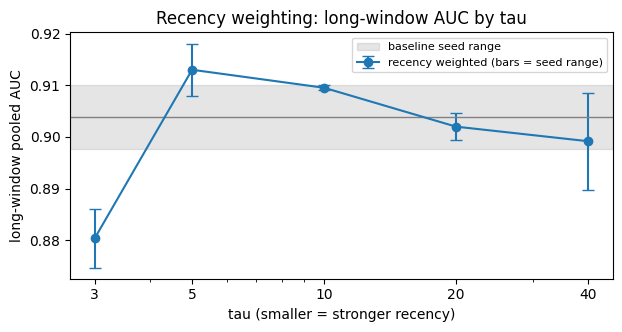


PASS  all taus x seeds stored, 14 steps each
PASS  baseline matches Step 3c
PASS  smaller tau uses less of the data
PASS  weights positive and averaging 1
PASS  short-window guard run for every winner


In [62]:
# ------------------------------------------------------------ Step 3f: recency weighting, tau grid (long window)
NOVEL_STEPS = [24, 29, 31, 32]                         # steps where the baseline missed new illicit operations (Step 3c)
sp_long = SPLITS_LONG[LONG_WIN]


def make_weight_fn(tau=None, cap_mult=None):
    """Recency weight exp((t - t_max)/tau), then cap each step's total illicit weight, then rescale to mean 1."""
    def weight_fn(d):
        t = d["time_step"].to_numpy()
        w = np.ones(len(d)) if tau is None else np.exp((t - t.max()) / tau)
        if cap_mult is not None:
            ill = d["label"].to_numpy() == 1
            step_ill = pd.Series(w[ill]).groupby(t[ill]).sum()
            scale = (cap_mult * step_ill.median() / step_ill).clip(upper=1.0)
            w[ill] = w[ill] * pd.Series(t[ill]).map(scale).to_numpy()
        return w / w.mean()
    return weight_fn


def summarize_names(names):
    rs = [RESULTS[n] for n in names]
    pooled = [r["score"] for r in rs]
    row = {"pooled_mean": np.mean(pooled), "pooled_min": min(pooled), "pooled_max": max(pooled),
           "within_step_mean": np.mean([r["per_window"]["mean_step_auc"].iat[0] for r in rs])}
    row.update({f"s{t}": np.mean([r["per_step"].loc[t, "auc"] for r in rs]) for t in NOVEL_STEPS})
    row["rounds"] = np.mean([r["per_window"]["rounds"].iat[0] for r in rs])
    return row


refit_rows = train_labelled[train_labelled.time_step.isin(sp_long["train"])]   # refit steps 1-21

TAUS = [3, 5, 10, 20, 40]


def tau_run_names(tau):
    return [f"long_w_tau{tau}_s{s}" for s in SEEDS]


t0 = time.time()
for tau in TAUS:
    wfn = make_weight_fn(tau, None)
    for s, name in zip(SEEDS, tau_run_names(tau)):
        cached_evaluate(FEATURE_SETS["r0_base"], name, params=dict(LGB_PARAMS, seed=s), splits=SPLITS_LONG,
                        weight_fn=wfn, weight_name=f"tau{tau}")
print(f"\nlong window: {len(TAUS)} taus x {len(SEEDS)} seeds in {(time.time() - t0) / 60:.1f} min\n")

rows = {"baseline": summarize_names(long_names)}
rows.update({f"tau{t}": summarize_names(tau_run_names(t)) for t in TAUS})
tau_table = pd.DataFrame(rows).T
tb = tau_table.loc["baseline"]
tau_table.insert(1, "delta", tau_table["pooled_mean"] - tb["pooled_mean"])
tau_table.insert(2, "verdict", np.where(tau_table["pooled_min"] > tb["pooled_max"], "win",
                               np.where(tau_table["pooled_max"] < tb["pooled_min"], "loss", "tie")))
tau_table.loc["baseline", "verdict"] = "reference"
tau_table.insert(5, "seed_spread", tau_table["pooled_max"] - tau_table["pooled_min"])

# how much of the training data each tau effectively uses (refit steps 1-21)
for t in TAUS:
    w = make_weight_fn(t, None)(refit_rows)
    tau_table.loc[f"tau{t}", "effective_rows_pct"] = 100 * w.sum() ** 2 / (w ** 2).sum() / len(w)
    tau_table.loc[f"tau{t}", "weight_10_back"] = np.exp(-10 / t)
tau_table.loc["baseline", ["effective_rows_pct", "weight_10_back"]] = [100.0, 1.0]

guard_t = {}
for cfg in tau_table.index[tau_table["verdict"] == "win"]:
    tau = int(cfg[3:])
    r = cached_evaluate(FEATURE_SETS["r0_base"], f"short_w_{cfg}", weight_fn=make_weight_fn(tau, None), weight_name=cfg)
    guard_t[cfg] = r["per_window"]["pooled_auc"] - RESULTS[BASELINE]["per_window"]["pooled_auc"]
tau_table["short_guard_ok"] = pd.Series({c: (d > -NOISE_WINDOW).all() for c, d in guard_t.items()})

print(tau_table.round(4).to_string())
if guard_t:
    print("\nShort-window AUC change vs baseline (winners only):")
    print(pd.DataFrame(guard_t).T.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.array(TAUS, dtype=float)
t_rows = tau_table.loc[[f"tau{t}" for t in TAUS]]
ax.errorbar(x, t_rows["pooled_mean"], yerr=[t_rows["pooled_mean"] - t_rows["pooled_min"], t_rows["pooled_max"] - t_rows["pooled_mean"]],
            fmt="o-", capsize=4, label="recency weighted (bars = seed range)")
ax.axhspan(tb["pooled_min"], tb["pooled_max"], alpha=0.2, color="grey", label="baseline seed range")
ax.axhline(tb["pooled_mean"], color="grey", lw=1)
ax.set(xscale="log", xticks=x, xticklabels=TAUS, xlabel="tau (smaller = stronger recency)",
       ylabel="long-window pooled AUC", title="Recency weighting: long-window AUC by tau")
ax.legend(fontsize=8)
plt.show()

# ------------------------------------------------------------ diagnostic
eff = t_rows["effective_rows_pct"]
checks = {
    "all taus x seeds stored, 14 steps each":        all(n in RESULTS and len(RESULTS[n]["per_step"]) == 14
                                                         for t in TAUS for n in tau_run_names(t)),
    "baseline matches Step 3c":                      np.isclose(tb["pooled_mean"], np.mean([RESULTS[n]["score"] for n in long_names])),
    "smaller tau uses less of the data":             eff.is_monotonic_increasing,
    "weights positive and averaging 1":              all(np.isclose(make_weight_fn(t, None)(refit_rows).mean(), 1) for t in TAUS),
    "short-window guard run for every winner":       set(guard_t) == set(tau_table.index[tau_table["verdict"] == "win"]),
}
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

**Step 3f results**
- **Long-window AUC rises steadily with stronger recency up to τ = 5** (τ = 40 → 5: 0.899 → 0.913), then collapses at τ = 3 (0.880, with only 21% of the data effectively used). → A coherent peak: recency helps until data loss dominates.
- **τ = 5 is best: +0.009 pooled, with gains on all four novel steps** (+0.007 to +0.020). → Recency helps exactly where the baseline failed.
- **Seed spread stays large at most τ** (0.005–0.019).
- **Every τ ties by the non-overlap rule** (baseline seed range 0.898–0.910). → The rule is too strict for this noise level; the consistent shape across τ is the better evidence.

**Implication:** τ = 5 (plateau 5–10) is the candidate. Judge it with a same-seed paired verdict and confirm it on the leaderboard.

### Step 3g: τ = 5 verdict and leaderboard file
Judges τ = 5 against the unweighted baseline seed by seed, then writes the τ = 5 leaderboard file.

**Design choices**
- **Paired verdict (fixed before seeing these results):** each seed is compared with the same-seed baseline. Win = every seed improves *and* the mean gain exceeds 0.005; loss is the mirror image; anything else is a tie. Same-seed comparisons cancel part of the seed luck that made the non-overlap rule too strict.
- **Leaderboard file:** the Step 3 recipe (early-stop on steps 33–35, refit on steps 1–35) with τ = 5 weights and unscaled trees. Together with the baseline's 0.936, it shows whether the long-window gain carries over to the test.
- **Test score profile (context only):** the share scoring above 0.5 per test step shows whether recency alters the post-43 collapse.

In [63]:
# ------------------------------------------------------------ Step 3g: tau = 5 paired verdict (long window) + leaderboard file
TAU_BEST = 5
MIN_GAIN = 0.005                                       # paired rule: every seed improves AND mean gain > 0.005


def paired_verdict(names, ref_names, min_gain=MIN_GAIN):
    """Compare each seed with the same-seed reference run."""
    d = np.array([RESULTS[n]["score"] - RESULTS[r]["score"] for n, r in zip(names, ref_names)])
    if (d > 0).all() and d.mean() > min_gain:
        return "win"
    if (d < 0).all() and d.mean() < -min_gain:
        return "loss"
    return "tie"


CANDIDATES = {"baseline": long_names, f"tau{TAU_BEST}": tau_run_names(TAU_BEST)}   # both already run (Steps 3c, 3f)
tau5_table = pd.DataFrame({cfg: summarize_names(names) for cfg, names in CANDIDATES.items()}).T
tau5_table.insert(1, "delta", tau5_table["pooled_mean"] - tau5_table.loc["baseline", "pooled_mean"])
for s_i, s in enumerate(SEEDS):
    tau5_table.insert(2 + s_i, f"delta_s{s}", [RESULTS[names[s_i]]["score"] - RESULTS[long_names[s_i]]["score"]
                                               for names in CANDIDATES.values()])
tau5_table.insert(2 + len(SEEDS), "paired_verdict",
                  [paired_verdict(names, long_names) if cfg != "baseline" else "reference"
                   for cfg, names in CANDIDATES.items()])
print(tau5_table.round(4).to_string())

# leaderboard file: tau = 5 weights, unscaled trees (the baseline file already exists from Step 3)
t0 = time.time()
_, base_rounds, _ = make_submission(FEATURE_SETS["r0_base"], BASELINE)                     # cached, unweighted reference
sub_tau5, tau5_rounds, tau5_path = make_submission(FEATURE_SETS["r0_base"], f"{BASELINE}_tau{TAU_BEST}",
                                                   weight_fn=make_weight_fn(TAU_BEST, None), weight_name=f"tau{TAU_BEST}")
print(f"\nsubmission in {(time.time() - t0) / 60:.1f} min: tau{TAU_BEST} uses {tau5_rounds} trees "
      f"(unweighted baseline {base_rounds}) -> {tau5_path}")

# context only: predicted illicit share per test step (> 0.5)
profile = {"baseline": scored.set_index("index")["pred"], f"tau{TAU_BEST}": sub_tau5.set_index(ID_COL)[TARGET_COL]}
step_of = test_predict.set_index("index")["time_step"]
print("\nShare of test transactions scoring > 0.5, per step:")
print(pd.DataFrame({k: (v > 0.5).groupby(step_of.loc[v.index].values).mean() for k, v in profile.items()}).T.round(3).to_string())

# ------------------------------------------------------------ diagnostic
written = pd.read_csv(tau5_path)
checks = {
    "tau5 runs stored, 14 steps each":                 all(n in RESULTS and len(RESULTS[n]["per_step"]) == 14 for n in CANDIDATES[f"tau{TAU_BEST}"]),
    "tau5 row matches the Step 3f grid":               np.isclose(tau5_table.loc[f"tau{TAU_BEST}", "pooled_mean"], tau_table.loc[f"tau{TAU_BEST}", "pooled_mean"]),
    "submission header matches template exactly":      open(tau5_path).readline().rstrip("\n") == raw_header,
    "15,329 rows, index order = template, no NaN":     (len(written) == 15_329 and (written[ID_COL].values == submission_template.iloc[:, 0].values).all()
                                                        and written[TARGET_COL].notna().all()),
    "predictions are probabilities in (0, 1)":         written[TARGET_COL].between(0, 1, inclusive="neither").all(),
    "round count from early stopping":                 1 <= tau5_rounds < MAX_ROUNDS,
    "tau5 file differs from the baseline file":        not np.allclose(sub_tau5[TARGET_COL].values, sub[TARGET_COL].values),
}
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

          pooled_mean   delta  delta_s0  delta_s1 paired_verdict  pooled_min  pooled_max  within_step_mean     s24     s29     s31     s32  rounds
baseline       0.9039  0.0000    0.0000    0.0000      reference      0.8976      0.9101            0.9280  0.7802  0.7559  0.7706  0.8034   399.5
tau5           0.9130  0.0091    0.0079    0.0103            win      0.9079      0.9181            0.9327  0.7941  0.7756  0.7778  0.8230   409.5
  sub_r0_base: trained and cached
  sub_r0_base_tau5: trained and cached

submission in 0.6 min: tau5 uses 288 trees (unweighted baseline 611) -> /content/submissions/sub_r0_base_tau5.csv

Share of test transactions scoring > 0.5, per step:
             36     37     38     39     40     41     42     43     44     45     46     47   48     49
baseline  0.020  0.054  0.135  0.063  0.066  0.099  0.093  0.001  0.007  0.001  0.011  0.002  0.0  0.004
tau5      0.021  0.052  0.132  0.063  0.065  0.096  0.089  0.001  0.006  0.003  0.010  0.001  0.0  0.006

PA

**Step 3g results**
- **τ = 5 is a paired win on the long window:** every seed improves (+0.008 / +0.010, mean +0.009), and the gains reach all four novel steps.
- **Leaderboard: `sub_r0_base_tau5.csv` scores 0.9499 (+0.0135 over 0.9364).** → The long window predicts the direction correctly but not the size. Recency matters even more on the real test, likely because it focuses the final model on the steps nearest the test period.
- **Recency also lowers the final tree count** (288 vs 611 trees from early stopping on steps 33–35).

**Key finding 1: recency weighting with τ = 5.** It is the project's one large leaderboard gain, and this file is **final pick 2**. From here on, the τ = 5 recipe on the 121 `r0_base` features is the model to beat.

# Part 2: New data exploration, revised protocols and cross-view pseudo-labels
*Source: `4012_alternate`.* This part starts from Part 1's data and cleaning: the shared setup, orientation and Steps 1–2 are identical in both notebooks, so they aren't repeated. It adds new exploration (T1–T3), revises the cleaning and validation protocols based on what T1–T3 found, and uses the revised validation to find the second key result. Step numbers follow `4012_alternate`, so gaps (3a–3h, 4, 5, 6c–6f and 7) mark experiments left out.

## Drift, selection bias and feature stability (T1–T3)

*Added from the new exploration notebook. Where these findings conflict with the cells above, the reconciliation table after T3 says which one the pipeline follows.*

### T1 — Temporal drift and the generalization gap
**Objective:** Determine whether forward-chaining cross-validation is a valid proxy for steps 36–49, given prevalence swings and an aggregate train–test feature shift.
**Method:** Measure prevalence autocorrelation and slope; run adversarial train-vs-test validation; compute per-step expanding-window AUC.

### T2 — Graph homophily under the masked test graph
**Objective:** Establish whether neighbour-label features are available and useful at prediction time, given that the test graph is only partially visible.
**Method:** Compare in/out degree by label; measure edge label agreement; test edge temporal direction; build masked neighbour-label features and report coverage and stand-alone AUC.

### T3 — Labelled-vs-unknown selection bias and feature stability
**Objective:** Test whether labelled rows are a biased sample of the population, and identify features whose discriminative direction is stable across steps.
**Method:** Fit a grouped-CV propensity model for labelledness; compute per-step univariate AUC per feature with orientation; measure correlation redundancy, PCA effective rank, tail mass, duplicate-label conflicts.

*Code changes from the original exploration:* every local name is prefixed `t1_` / `t2_` / `t3_` (the originals overwrote `nodes`, `per`, `stab` and `A`, which later cells use), nothing is written into `train`, T1.2's test-likeness is now out-of-fold, the unused T1.4 helper (it referenced an undefined `y`) and the D1 pseudo-label cell (NameError, depends on self-training) are removed, and T3 saves its stability table for cleaning Step 3.

In [64]:
# Cell T1 — temporal drift, adversarial validation, per-step generalization
# Outputs below are from the original exploration run; only the "test-likeness by step" print changes on rerun
# (it is now out-of-fold - the original scored train rows in-sample with a model refit on all rows).
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

T1_TIME_COUNTERS = ["feat_2", "feat_100", "feat_101", "feat_103", "feat_106",
                    "feat_107", "feat_109", "feat_136", "feat_137", "feat_139"]   # dropped in cleaning Step 2

# T1.1 prevalence trajectory and persistence
t1_prev = train.groupby("time_step")["y"].agg(n="size", pos="sum", rate="mean")
print(t1_prev.round(3).to_string())
print("lag-1 autocorr of illicit rate:", t1_prev["rate"].autocorr(1).round(3))
print("linear slope per step:", np.polyfit(t1_prev.index, t1_prev["rate"], 1)[0].round(5))

# T1.2 adversarial validation train vs test (all train rows, all 165 features)
t1_Xa = pd.concat([train[feat_tr], test[feat_te]], ignore_index=True)
t1_ya = np.r_[np.zeros(len(train)), np.ones(len(test))]
t1_adv = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=63,
                            verbosity=-1, random_state=0)
t1_oof = np.zeros(len(t1_Xa))
for tr, va in StratifiedKFold(3, shuffle=True, random_state=0).split(t1_Xa, t1_ya):
    t1_adv.fit(t1_Xa.iloc[tr], t1_ya[tr]); t1_oof[va] = t1_adv.predict_proba(t1_Xa.iloc[va])[:, 1]
print("adversarial AUC train vs test:", round(roc_auc_score(t1_ya, t1_oof), 4))
t1_like = pd.Series(t1_oof[:len(train)], index=train.index)          # out-of-fold test-likeness of train rows
print("mean OOF test-likeness by step:\n",
      t1_like.groupby(train.time_step).mean().round(3).to_string())
t1_adv.fit(t1_Xa, t1_ya)                                             # refit only for importances
t1_imp = pd.Series(t1_adv.feature_importances_, index=feat_tr).sort_values(ascending=False)
t1_top = t1_imp.head(15).to_frame("split_importance")
t1_top["time_counter"] = t1_top.index.isin(T1_TIME_COUNTERS)
print("top-15 drifting features:\n", t1_top.to_string())

# T1.3 per-step AUC of an expanding-window baseline (all 165 features - NOT r0;
#      r0's forward-chaining vs boundary gap is measured in Model Building Step 3c)
def t1_per_step_auc(start=15, min_pos=15, n_rounds=200):
    rows = []
    for s in range(start, 36):
        tr = train[(train.time_step < s) & train.y.notna()]
        va = train[(train.time_step == s) & train.y.notna()]
        if va.y.sum() < min_pos or va.y.nunique() < 2:
            continue
        m = lgb.train({"objective": "binary", "verbosity": -1, "num_leaves": 31,
                       "learning_rate": 0.05, "seed": 0, "min_data_in_leaf": 30},
                      lgb.Dataset(tr[feat_tr], tr.y), num_boost_round=n_rounds)
        p = m.predict(va[feat_tr])
        rows.append({"step": s, "n": len(va), "pos": int(va.y.sum()),
                     "auc": roc_auc_score(va.y, p), "score_mean": p.mean()})
    return pd.DataFrame(rows).set_index("step")


t1_psa = t1_per_step_auc()
print(t1_psa.round(3).to_string())
print("corr(step score_mean, step illicit rate):",
      t1_psa["score_mean"].corr(t1_prev.loc[t1_psa.index, "rate"]).round(3))
# (T1.4, pooled vs per-step rank-normalised AUC, is covered by Model Building Step 3b with leaderboard evidence)

              n    pos   rate
time_step                    
1          7880   17.0  0.008
2          4544   18.0  0.016
3          6621   11.0  0.009
4          5693   30.0  0.021
5          6803    8.0  0.004
6          4328    5.0  0.010
7          6048  102.0  0.085
8          4457   67.0  0.058
9          4996  248.0  0.319
10         6727   18.0  0.019
11         4296  131.0  0.188
12         2047   16.0  0.032
13         4528  291.0  0.360
14         2022   43.0  0.103
15         3639  147.0  0.238
16         2975  128.0  0.242
17         3385   99.0  0.122
18         1976   52.0  0.134
19         3506   80.0  0.107
20         4291  260.0  0.289
21         3537  100.0  0.156
22         5894  158.0  0.090
23         4165   53.0  0.045
24         4592  137.0  0.122
25         2314  118.0  0.199
26         2523   96.0  0.186
27         1089   24.0  0.117
28         1653   85.0  0.299
29         4275  329.0  0.280
30         2483   83.0  0.158
31         2816  106.0  0.149
32        

In [65]:
# Cell T2 — graph structure, homophily, and masked-graph coverage
t2_lab_ids = set(y_all.index[y_all.notna()])
t2_te_ids = set(test.txId)

# T2.1 degree by label (full edge list, so hidden edges are counted - comparable across train/test)
t2_nodes = pd.Index(sorted(set(e.src) | set(e.dst)))
t2_deg = pd.concat([e.groupby("src").size().rename("out_deg"),
                    e.groupby("dst").size().rename("in_deg")], axis=1)
t2_deg = t2_deg.reindex(t2_nodes).fillna(0)
t2_deg["y"] = y_all.reindex(t2_deg.index)
print(t2_deg.groupby("y", dropna=True)[["in_deg", "out_deg"]]
        .describe().round(2).to_string())

# T2.2 edge-level label agreement among labelled nodes
t2_el = e[e.src.isin(t2_lab_ids) & e.dst.isin(t2_lab_ids)]
t2_ys, t2_yd = y_all.reindex(t2_el.src).to_numpy(), y_all.reindex(t2_el.dst).to_numpy()
print(f"labelled edges: {len(t2_el):,}")
print("agreement:", (t2_ys == t2_yd).mean().round(4),
      "| P(dst=1|src=1):", t2_yd[t2_ys == 1].mean().round(4),
      "| P(dst=1|src=0):", t2_yd[t2_ys == 0].mean().round(4))

# T2.3 temporal direction — which neighbours exist at prediction time
t2_es, t2_ed = ts.reindex(e.src).to_numpy(), ts.reindex(e.dst).to_numpy()
t2_ok = ~(np.isnan(t2_es) | np.isnan(t2_ed))
print("forward (src step < dst):", (t2_es[t2_ok] < t2_ed[t2_ok]).mean().round(3),
      "| same step:", (t2_es[t2_ok] == t2_ed[t2_ok]).mean().round(3),
      "| backward:", (t2_es[t2_ok] > t2_ed[t2_ok]).mean().round(3))


# T2.4 neighbour-label feature built exactly as it would be at test time
#      (only visible, labelled neighbours; the node's own label is never used)
def t2_neigh_feats(node_ids):
    pred = e[e.dst.isin(node_ids)].copy(); pred["y"] = y_all.reindex(pred.src).to_numpy()
    succ = e[e.src.isin(node_ids)].copy(); succ["y"] = y_all.reindex(succ.dst).to_numpy()
    out = pd.DataFrame(index=pd.Index(list(node_ids), name="txId"))
    for nm, g in [("pred", pred), ("succ", succ)]:
        g = g[g.y.notna()]
        key = "dst" if nm == "pred" else "src"
        agg = g.groupby(key)["y"].agg(["mean", "count"])
        out[f"{nm}_y_mean"], out[f"{nm}_y_count"] = agg["mean"], agg["count"]
    out["nbr_y_mean"] = out[["pred_y_mean", "succ_y_mean"]].mean(axis=1)
    out["has_lab_nbr"] = out["nbr_y_mean"].notna()
    return out


t2_cov_tr, t2_cov_te = t2_neigh_feats(t2_lab_ids), t2_neigh_feats(t2_te_ids)
print("coverage: train {:.3f} | test {:.3f}".format(
      t2_cov_tr["has_lab_nbr"].mean(), t2_cov_te["has_lab_nbr"].mean()))
# predictive value of the neighbourhood feature alone (labelled train rows with a nbr)
t2_v = t2_cov_tr["has_lab_nbr"] & y_all.reindex(t2_cov_tr.index).notna()
print("AUC of nbr_y_mean alone:",
      round(roc_auc_score(y_all.reindex(t2_cov_tr.index)[t2_v], t2_cov_tr["nbr_y_mean"][t2_v]), 4))

      in_deg                                         out_deg                                       
       count  mean   std  min  25%  50%  75%    max    count  mean   std  min  25%  50%  75%    max
y                                                                                                  
0.0  27591.0  1.83  6.12  0.0  0.0  1.0  1.0  284.0  27591.0  1.15  3.78  0.0  0.0  1.0  1.0  472.0
1.0   3644.0  1.25  7.23  0.0  0.0  1.0  1.0  173.0   3644.0  0.75  0.56  0.0  0.0  1.0  1.0    2.0
labelled edges: 23,900
agreement: 0.9468 | P(dst=1|src=1): 0.5598 | P(dst=1|src=0): 0.0267
forward (src step < dst): 0.0 | same step: 1.0 | backward: 0.0
coverage: train 0.782 | test 0.000
AUC of nbr_y_mean alone: 0.7775


In [66]:
# Cell T3 — labelled-vs-unknown bias, per-feature stability, redundancy, tails
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.decomposition import PCA

STABILITY_T3_CSV = "/content/feature_stability_t3.csv"   # read by cleaning Step 3 (whitelist)

# T3.1 is "labelled" predictable from features? (MNAR test)
t3_islab = train.y.notna().astype(int)
t3_clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31,
                            verbosity=-1, random_state=0)
t3_oof_lab = cross_val_predict(t3_clf, train[feat_tr], t3_islab,
                               groups=train.time_step, cv=GroupKFold(5),
                               method="predict_proba")[:, 1]
print("AUC labelled vs unknown (grouped by step):",
      round(roc_auc_score(t3_islab, t3_oof_lab), 4))
t3_step = train.time_step.to_numpy()
print(pd.Series({s: roc_auc_score(t3_islab[t3_step == s], t3_oof_lab[t3_step == s])
                 for s in np.unique(t3_step) if t3_islab[t3_step == s].nunique() == 2},
                name="AUC").rename_axis("time_step").round(3).to_string())

# T3.2 per-step univariate AUC per feature -> stability table
t3_rows, t3_counts = [], {}
for s, g in train.dropna(subset=["y"]).groupby("time_step"):
    if g.y.sum() < 10:
        continue
    yv = g.y.to_numpy()
    t3_rows.append(pd.Series({f: roc_auc_score(yv, g[f]) for f in feat_tr}, name=s))
    t3_counts[s] = (int((yv == 1).sum()), int((yv == 0).sum()))
t3_A = pd.DataFrame(t3_rows).T
t3_flip = t3_A.mean(axis=1) < 0.5                 # orient each feature by its mean direction
t3_A.loc[t3_flip] = 1 - t3_A.loc[t3_flip]
# chance wobble of a useless feature's AUC in each step (null standard error); a step counts as a
# reversal only if the oriented AUC falls more than 2 SE below 0.5, so small steps can't fake one
t3_se = pd.Series({s: np.sqrt((n1 + n0 + 1) / (12 * n1 * n0)) for s, (n1, n0) in t3_counts.items()})
STAB_T3 = pd.DataFrame({"mean": t3_A.mean(1), "min": t3_A.min(1),
                        "std": t3_A.std(1), "n_steps": t3_A.notna().sum(1),
                        "n_reversed": t3_A.lt(0.5 - 2 * t3_se, axis=1).sum(axis=1),
                        "higher_means": np.where(t3_flip, "licit", "illicit")})
STAB_T3.to_csv(STABILITY_T3_CSV)
print("most stable features:\n",
      STAB_T3.sort_values(["min", "mean"], ascending=False).head(15).round(3).to_string())
print("most unstable features:\n",
      STAB_T3.sort_values("std", ascending=False).head(15).round(3).to_string())
print(f"stability table saved to {STABILITY_T3_CSV}")

# T3.3 redundancy and effective dimensionality
t3_C = train[feat_tr].corr().abs()
t3_iu = np.triu_indices_from(t3_C, 1)
print("feature pairs with |r|>0.95:", int((t3_C.to_numpy()[t3_iu] > 0.95).sum()))
t3_Z = (train[feat_tr] - train[feat_tr].mean()) / train[feat_tr].std()
t3_pca = PCA(n_components=min(60, len(feat_tr))).fit(t3_Z)
print("cum. explained var @ 20/40/60 comps:",
      np.cumsum(t3_pca.explained_variance_ratio_)[[19, 39, 59]].round(3))

# T3.4 heavy tails — clipping / rank-transform candidates
t3_z = t3_Z.abs()
print("features with >1% of |z|>5:", int((t3_z > 5).mean().gt(0.01).sum()))
print("features with max|z|>20:", int((t3_z.max() > 20).sum()))

# T3.5 duplicate feature rows: conflicting labels?
t3_dups = train[train.duplicated(feat_tr, keep=False)]
print("duplicate-row groups with conflicting labels:",
      int((t3_dups.groupby(feat_tr)["y"].nunique() > 1).sum()),
      "of", t3_dups.groupby(feat_tr).ngroups)

AUC labelled vs unknown (grouped by step): 0.9747
time_step
1     0.960
2     0.989
3     0.993
4     0.985
5     0.995
6     0.995
7     0.985
8     0.967
9     0.973
10    0.991
11    0.973
12    0.909
13    0.977
14    0.976
15    0.988
16    0.975
17    0.974
18    0.981
19    0.986
20    0.966
21    0.965
22    0.983
23    0.982
24    0.980
25    0.984
26    0.964
27    0.990
28    0.994
29    0.928
30    0.981
31    0.943
32    0.915
33    0.987
34    0.974
35    0.953
most stable features:
            mean    min    std  n_steps  n_reversed higher_means
feat_90   0.833  0.639  0.091       33           0        licit
feat_161  0.747  0.600  0.076       33           0        licit
feat_5    0.798  0.589  0.087       33           0        licit
feat_14   0.798  0.589  0.087       33           0        licit
feat_60   0.812  0.588  0.101       33           0        licit
feat_66   0.812  0.587  0.102       33           0        licit
feat_89   0.802  0.581  0.111       33           

## T1–T3 findings and implications

### T1 — Temporal drift
- **Prevalence is step-local:** lag-1 autocorrelation of the illicit rate 0.118, slope +0.004 per step. → Past prevalence doesn't forecast test prevalence. This says nothing about how the feature–label relationship ages, which is what recency weighting (Step 3f) targets, so recency stays under test.
- **Train and test are perfectly separable on raw features:** adversarial AUC 1.0. But 7 of the 15 top drifters are time counters that cleaning already drops (feat_2, 100, 101, 103, 136, 137, 139); the drifters left inside the old R0 are feat_1, 52, 88, 154, 22, 23, 130, 8. → Cleaning already drops those counters; the drifters left inside are handled by the revised cleaning (Step 3, residualised against their step).
  - *Correction:* the original "mean test-likeness by step = 0.0" was scored in-sample by a model refit on all rows, so it was ~0 by construction. The cell now prints the out-of-fold version.
- **Forward-chaining is blind to the boundary:** 1-step-ahead AUC is 0.957–1.000 on steps 15–35 (all 165 features), against a public LB of 0.936–0.950. → Every modelling decision moves to a boundary-crossing metric (revised validation, Step 1).
- **Mean step score tracks the step illicit rate (r = 0.988).** → The model's cross-step score levels carry real prevalence information. That argues *against* per-step rank normalisation (which also lost on the LB: 0.9312 vs 0.9364), not for it.

### T2 — Graph under the masked test graph
- **Labelled-neighbour coverage is 0.000 in test vs 0.782 in train,** so the neighbour-label feature (AUC 0.7775 on train) can never be computed for test. → All true-label graph features are discarded.
- **Edges are 100% within-step** (forward 0.0, backward 0.0), consistent with the graph cell above.
- **Illicit out-degree never exceeds 2 on the full edge list** (licit up to 472). The full list includes hidden edges, so this count is label-free and comparable between train and test. → A candidate feature, not added in this pass.

### T3 — Selection bias and stability
- **Labelledness is near-deterministic from features:** grouped AUC 0.9747, per step 0.909–0.995. Combined with the orientation check (test.csv ≈ labelled-type transactions only), the labelled rows, not the full training population, are the right reference for test. → Pseudo-labels picked from unknown rows would come from a systematically different region than test. If pseudo-labelling is used, it must label the test rows themselves (Step 8).
- **Stable vs unstable features (mean / min / std of oriented per-step AUC):** stable feat_90 0.833/0.639/0.091, feat_161 0.747/0.600/0.076, feat_5 0.798/0.589/0.087, feat_60 0.812/0.588/0.101, feat_89, feat_142, feat_162, feat_41, feat_91. Unstable but inside the old R0: feat_3 0.504/0.090/0.226 (chance), feat_52 0.733/0.257/0.188 (also the #6 drifter), feat_22 0.659/0.281/0.152, feat_40 0.720/0.415/0.150, feat_46 0.721/0.417/0.150, feat_43/49 0.834/0.459/0.145. → R0 is rebuilt from a stable-feature whitelist (revised cleaning, Step 3).
- **Drift ≠ instability:** feat_23, 8, 88, 130, 154 drift in level but keep usable within-step AUC. → Kept and residualised against their step, not dropped.
- **Redundancy and tails:** 103 pairs with |r| > 0.95; 20/40/60 principal components explain 0.649/0.848/0.957 of the variance; 63 features have max |z| > 20 (trees are insensitive to tails); 13 duplicate-row groups, none with conflicting labels.

## Reconciliation: earlier exploration vs T1–T3

| # | Topic | Earlier cells | T1–T3 | What the pipeline does now |
|---|---|---|---|---|
| 1 | Adversarial AUC 1.0 | "re-check the shift on labelled rows" | "deterministic fingerprint, not drift" | Run on all rows and all 165 features, dominated by time counters, with in-sample test-likeness. Read as a fingerprint of the time counters plus the labelled-only test population. **Time counters are dropped (cleaning Step 2), and the remaining drifters are residualised (revised cleaning Step 3).** |
| 2 | Per-step rank normalisation | Original notebook Step 3b: costs validation AUC, **lost on the LB** (α = 0.5: 0.9312 vs 0.9364) | "rank normalisation is justified" | **Not adopted.** r = 0.988 between mean score and step illicit rate shows score levels carry real information. |
| 3 | Recency weighting | τ = 5 gave the largest LB gain (+0.014) | "prevalence-based recency weighting has no basis" | The notebook's recency is time-decay, not prevalence-based, so the two don't conflict directly. **τ = 5 is kept.** The Evaluation v2 calibration (Step 6b) re-confirms it on the new metric. |
| 4 | Graph features | "neighbour-score features most promising"; "never use comp_size" | "discard label-based graph features; keep out-degree and within-step component size" | True-label neighbour features dropped (both agree). **Component size rejected:** every training step is one component, while test steps split into 110–665, so it fingerprints the split. Full-list out-degree and predicted-score neighbour features remain untested candidates. |
| 5 | Weighting for selection bias | — | "replace pseudo-labelling with inverse-probability weighting for **labelledness**" | **Not adopted.** IPW for labelledness reweights toward the full training population (78% unknown), which is *away* from test (labelled-type rows). The same finding points pseudo-labelling at the **test rows** (Step 8), never at unknown rows. |
| 6 | Stability table | v2: ≥ 20 of each class, 28 steps; feat_3 "watch: strengthening near test"; feat_88 "erratic" | T3: ≥ 10 illicit, 33 steps; feat_3 chance (0.504) | The **whitelist reads T3**, and v2 stays as descriptive context. feat_3 is dropped. feat_88 is kept and residualised per fix 1, and the whitelist diagnostic prints its stability so the conflict stays visible. **feat_55** is in T3's 15 most unstable (std 0.155) but not on the drop list; it passes the rule (min 0.477), so it is kept. |
| 7 | Correlation collapse | groups at \|r\| ≥ 0.99 | 103 pairs > 0.95: "collapse correlated blocks" | **0.99 kept.** Chaining at 0.95 merges features that aren't redundant, and seed noise is measured directly (3 seeds). |

# REVISED CLEANING (tested, not adopted)
Cleaning Steps 1–2 (labelled rows, then 10 time counters, `feat_15` and 33 near-duplicates removed, leaving 121 features) are unchanged from Part 1, so `train_labelled`, `test_predict`, `FEATURES_ALL` and `FEATURES_BASE` are reused as they are. Only Step 3 is new.

> **Outcome, stated up front:** the boundary metric selects `r0_drop` (114 features). On the leaderboard it **tied without recency** (0.9360 vs 0.9364) and **lost with τ = 5** (0.9461 vs 0.9499). Evaluation v2 (Step 6b) reads it as a loss too, so **both final submissions keep the 121-feature set** (`r0_old` = Part 1's `r0_base`). The step stays in the notebook because the revised validation is calibrated on it.

### Step 3: Stable-feature whitelist (R0 rebuild)
Replaces the category-based trimming rounds. Builds R0 from `FEATURES_BASE` with the T3 per-step stability table, removes the unstable features explicitly, and residualises the features that drift in level but stay stable within each step. Four candidate sets are compared later under the boundary metric.

**Design choices**
- **Whitelist rule = proven stable:** keep a feature only if it reverses direction beyond chance in at most 1 step (`n_reversed ≤ 1`) and its mean oriented AUC is ≥ 0.55 (T3 table, 33 steps with ≥ 10 illicit).
  - **Why reversals rather than the worst step:** with 10 illicit in a step, a useless feature's AUC wobbles by about ±0.09, so the lowest of 33 steps falls near 0.30 by chance alone. A reversal is counted only when a step's AUC sits more than 2 chance-SE below 0.5, so small steps can't fake one.
  - **Why allow one:** at 2 SE, a feature with no real flip still crosses in about 2% of steps, so roughly one chance crossing in 33 steps is expected.
  - **Why mean ≥ 0.55:** never reversing proves nothing for a feature with no signal. 0.55 is the v2 boundary between "weak" and useful.
- **Explicit drops on top of the rule:** feat_3, feat_52, feat_22, feat_40, feat_46, feat_43, feat_49 are always excluded.
- **Residualised drifters:** feat_8, 23, 88, 130, 154 are replaced by (x − step median) / step IQR. They are forced into the whitelist (per the fix), and the diagnostic prints their stability, so one that fails the rule stays visible (feat_88 was "erratic" in v2).
- **Statistics from the labelled population:** step medians and IQRs come from the labelled rows of each training step and from all rows of each test step. test.csv holds labelled-type transactions only (orientation check), and labelled rows are a distinct population (T3.1, AUC 0.975), so using all train rows would centre train and test on different populations.
- **Four candidate sets:**
  - `r0_old`: the previous 121-feature R0, as a reference.
  - `r0_drop`: old R0 minus the explicit drops (the minimal fix), drifters residualised.
  - `r0_wl_raw`: whitelist with raw drifters, to isolate the residual transform.
  - `r0_wl`: whitelist with residualised drifters. This is the intended R0 and stays unless another set wins outright (Model Building Step 3).
- **Watch list retired:** feat_3 is dropped. feat_84, 112, 142 and 148 follow the rule like every other feature.

In [67]:
# ------------------------------------------------------------ Step 3: stable-feature whitelist (R0 rebuild)
from scipy.stats import ks_2samp

STABILITY_T3_CSV = "/content/feature_stability_t3.csv"    # written by Cell T3 (decides the whitelist)
STABILITY_V2_CSV = "/content/feature_stability.csv"       # written by the v2 cell (descriptive categories only)
stab_t3 = pd.read_csv(STABILITY_T3_CSV, index_col=0)
category_v2 = pd.read_csv(STABILITY_V2_CSV, index_col=0)["category"]

WL_MAX_REVERSALS = 1    # steps with oriented AUC more than 2 chance-SE below 0.5 (about one expected by chance)
WL_MEAN_AUC = 0.55      # mean oriented AUC; below this the feature is "weak" (v2 boundary), so stability proves nothing
EXPLICIT_DROP = ["feat_3", "feat_52", "feat_22", "feat_40", "feat_46", "feat_43", "feat_49"]
RESIDUAL_FEATURES = ["feat_8", "feat_23", "feat_88", "feat_130", "feat_154"]   # drift in level, stable within step
CITED_STABLE = ["feat_90", "feat_161", "feat_5", "feat_14", "feat_60", "feat_66", "feat_89", "feat_142",
                "feat_23", "feat_29", "feat_41", "feat_47", "feat_91", "feat_162"]   # stable top-15 named in fix 1

passes_rule = (stab_t3["n_reversed"] <= WL_MAX_REVERSALS) & (stab_t3["mean"] >= WL_MEAN_AUC)
WHITELIST = [c for c in FEATURES_BASE
             if c not in EXPLICIT_DROP and (bool(passes_rule.get(c, False)) or c in RESIDUAL_FEATURES)]


# ------------------------------------------------------------ residual transform (per-step robust standardisation)
def add_step_residuals(df, cols, floor):
    """Adds `<col>_res` = (x - step median) / max(step IQR, floor), statistics from the rows of the same step in `df`.
    The floor (global IQR of the labelled training rows) stops steps whose values pile up on one point from
    being blown up by a near-zero IQR."""
    g = df.groupby("time_step")
    for c in cols:
        q = g[c].quantile([0.25, 0.5, 0.75]).unstack()
        scale = (q[0.75] - q[0.25]).clip(lower=floor[c])
        df[f"{c}_res"] = (df[c] - df["time_step"].map(q[0.5])) / df["time_step"].map(scale)
    return df


RES_FLOOR = {}                                                           # one constant per feature, shared by train and test
for c in RESIDUAL_FEATURES:
    iqr = train_labelled[c].quantile(0.75) - train_labelled[c].quantile(0.25)
    RES_FLOOR[c] = iqr if iqr > 1e-9 else max(train_labelled[c].std(), 1e-9)
train_labelled = add_step_residuals(train_labelled, RESIDUAL_FEATURES, RES_FLOOR)   # labelled rows of each training step
test_predict = add_step_residuals(test_predict, RESIDUAL_FEATURES, RES_FLOOR)       # all rows of each test step
res = lambda cols: [f"{c}_res" if c in RESIDUAL_FEATURES else c for c in cols]

FEATURE_SETS = {
    "r0_old":    list(FEATURES_BASE),                                    # previous R0 (reference for the fix)
    "r0_drop":   res([c for c in FEATURES_BASE if c not in EXPLICIT_DROP]),
    "r0_wl_raw": list(WHITELIST),
    "r0_wl":     res(WHITELIST),                                          # intended R0
}
R0_DEFAULT = "r0_wl"

# ------------------------------------------------------------ diagnostic
named = list(dict.fromkeys(EXPLICIT_DROP + RESIDUAL_FEATURES + CITED_STABLE))
table = stab_t3.reindex(named)[["mean", "min", "std", "n_reversed"]].copy()
table["v2_category"] = category_v2.reindex(named).values
table["in_base"] = [c in FEATURES_BASE for c in named]
table["passes_rule"] = [bool(passes_rule.get(c, False)) for c in named]
table["in_whitelist"] = [c in WHITELIST for c in named]
table["role"] = ["explicit drop" if c in EXPLICIT_DROP else "residualised" if c in RESIDUAL_FEATURES
                 else "cited stable" for c in named]

rule_only = [c for c in FEATURES_BASE if c not in WHITELIST and c not in EXPLICIT_DROP]
forced = [c for c in RESIDUAL_FEATURES if not passes_rule.get(c, False)]
ks = pd.DataFrame({c: {"ks_raw": ks_2samp(train_labelled[c], test_predict[c]).statistic,
                       "ks_residual": ks_2samp(train_labelled[f"{c}_res"], test_predict[f"{c}_res"]).statistic}
                   for c in RESIDUAL_FEATURES}).T
step_med = pd.concat([train_labelled.groupby("time_step")[[f"{c}_res" for c in RESIDUAL_FEATURES]].median(),
                      test_predict.groupby("time_step")[[f"{c}_res" for c in RESIDUAL_FEATURES]].median()])
time_cols = {"feat_2", "feat_100", "feat_101", "feat_103", "feat_106", "feat_107", "feat_109", "feat_136", "feat_137", "feat_139"}

checks = {
    "T3 table covers all 165 features":             set(FEATURES_ALL) <= set(stab_t3.index),
    "explicit drops absent from every new set":     all(not set(EXPLICIT_DROP) & set(FEATURE_SETS[s]) for s in ["r0_drop", "r0_wl_raw", "r0_wl"]),
    "T3 table has reversal counts (rerun T3)":      "n_reversed" in stab_t3.columns,
    "cited stable features (in base) all kept":     all(c in WHITELIST for c in CITED_STABLE if c in FEATURES_BASE),
    "residualised: _res in, raw out (r0_wl)":       all(f"{c}_res" in FEATURE_SETS["r0_wl"] and c not in FEATURE_SETS["r0_wl"] for c in RESIDUAL_FEATURES),
    "residuals centred: |step median| < 1e-6":     step_med.abs().max().max() < 1e-6,
    "residuals reduce train-test KS":               (ks["ks_residual"] < ks["ks_raw"]).all(),
    "no time counters in any set":                  not any(time_cols & set(s) for s in FEATURE_SETS.values()),
    "r0_old is the previous FEATURES_BASE":         FEATURE_SETS["r0_old"] == list(FEATURES_BASE),
    "all sets present in test":                     all(set(s) <= set(test_predict.columns) for s in FEATURE_SETS.values()),
    "no id/label/time columns in any set":          all(not {"txId", "time_step", "label", "index"} & set(s) for s in FEATURE_SETS.values()),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nwhitelist rule: reversals beyond chance <= {WL_MAX_REVERSALS} and mean >= {WL_MEAN_AUC} (T3 table)")
kept_by_rule = [c for c in EXPLICIT_DROP if passes_rule.get(c, False)]
print("explicit drops the rule alone would have kept:", kept_by_rule or "none")
print("\nNamed features (T3 stats, v2 category, membership):")
print(table.round(3).to_string())
if forced:
    print(f"\nWARNING: forced in by fix 1 although they fail the rule: {forced}")
print(f"\nexcluded by the rule alone ({len(rule_only)}), by v2 category:",
      category_v2.reindex(rule_only).value_counts().to_dict())
print("  ", ", ".join(rule_only))
print("\nTrain-vs-test KS, raw vs residualised drifters:")
print(ks.round(3).to_string())
print("\nfeature set      n")
for name, cols in FEATURE_SETS.items():
    print(f"{name:<12} {len(cols):>4}{'   <- intended R0' if name == R0_DEFAULT else ''}")
if len(FEATURE_SETS[R0_DEFAULT]) < 30:
    print(f"\nWARNING: the whitelist keeps only {len(FEATURE_SETS[R0_DEFAULT])} features; "
          "check WL_MAX_REVERSALS / WL_MEAN_AUC before relying on it (r0_drop is the lighter alternative).")

PASS  T3 table covers all 165 features
PASS  explicit drops absent from every new set
PASS  T3 table has reversal counts (rerun T3)
PASS  cited stable features (in base) all kept
PASS  residualised: _res in, raw out (r0_wl)
PASS  residuals centred: |step median| < 1e-6
FAIL  residuals reduce train-test KS
PASS  no time counters in any set
PASS  r0_old is the previous FEATURES_BASE
PASS  all sets present in test
PASS  no id/label/time columns in any set

whitelist rule: reversals beyond chance <= 1 and mean >= 0.55 (T3 table)
explicit drops the rule alone would have kept: ['feat_43', 'feat_49']

Named features (T3 stats, v2 category, membership):
           mean    min    std  n_reversed v2_category  in_base  passes_rule  in_whitelist           role
feat_3    0.504  0.090  0.226          12     erratic     True        False         False  explicit drop
feat_52   0.733  0.257  0.188           2    moderate     True        False         False  explicit drop
feat_22   0.659  0.281  0.152  

## Cleaning summary: key observations and implications

1. 10 time-counter features, near-constant feat_15 and 33 near-duplicates (30 groups at |r| ≥ 0.99) removed, 165 → 121 features (step 2) - implication: the base set holds no time proxies or duplicate columns, so importances aren't split across copies and splits can't encode "which period".
2. Of the 8 explicit drops, 5 reverse direction beyond chance (feat_3: 12 steps at chance-level mean 0.504; feat_22: 3; feat_52, 40, 46: 2 each), but feat_43/49 (0 reversals, mean 0.834) and feat_1 (1 reversal) pass the stability rule (step 3) - implication: dropping feat_43/49 rests on step-to-step variability and dropping feat_1 on drift, not on reversals; they are the drops most worth re-testing one at a time.
3. The "proven stable" whitelist keeps only 55 features, excluding 58, mostly weak (27), erratic (13) and moderate (10), and scores 0.8627 vs 0.9150 for old R0 minus the explicit drops (113 features) on the boundary metric (step 3, validated in model building step 3) - implication: the model relies on many individually weak features in combination, so trimming should remove only strong features that flip direction; R0 = `r0_drop`, which beats the old 121-feature R0 by +0.0071 (paired win; +0.014 on long_22-35, with gains on every novel step).
4. Residualising cuts train–test KS sharply for feat_8 (0.108 → 0.039) and feat_130 (0.154 → 0.101), but barely for feat_88/154 and not at all for feat_23 (0.127 → 0.138); residualised drifters still beat raw ones inside the whitelist (+0.0088, paired win) (step 3) - implication: keep residuals; feat_23's train–test difference is not a step-level shift, so step-centring can't remove it and it needs a different fix (rank transform or drop test).
5. 3 of the 5 residualised drifters fail the stability rule: feat_88 is near chance (mean 0.512, 7 reversals), while feat_8 (3) and feat_130 (2) reverse beyond chance (step 3) - implication: feat_88 behaves like feat_3 and is a drop candidate rather than a residual candidate; test dropping feat_88 (and then feat_8 and feat_130) on top of `r0_drop`.

# REVISED VALIDATION PROTOCOL

## Step 1: Validation setup (boundary-crossing)
Fixes the model settings and replaces forward-chaining with a boundary-crossing metric, so that every decision is made on forecasts 14 steps ahead, like the real 35 → 36–49 gap.

**Design choices**
- **Why the change:** forward-chaining AUC on steps 15–35 is 0.957–1.000 (T1.3), and the old short windows scored 0.997, while the leaderboard sits at 0.936–0.950 and train vs test is perfectly separable (adversarial AUC 1.0). A metric that never crosses a boundary can't see the 0.04–0.05 generalisation tax, so it keeps favouring drifting features and heavier models.
- **Two boundary windows:** `long_18-31` (train 1–17, validate 18–31) and `long_22-35` (train 1–21, validate 22–35), both 14 steps ahead. The recipe is the same as before: probe on all but the last 3 training steps, early-stop on those 3, then refit on all training steps.
- **Headline = boundary score = mean of the two window-pooled AUCs.** Two windows reduce the dependence on which operations happen to fall in one window (in the old long window, steps 24, 29, 31 and 32 drove most of the loss).
- **Drop = AUC(long_18-31) − AUC(long_22-35):** what the later simulated boundary costs, reported for every run. It is a diagnostic, not the objective, since a configuration can shrink the drop just by getting worse on 18–31.
- **Old short windows (26–28, 29–31, 32–35)** are kept as `SPLITS_SHORT` for diagnostics only and never decide anything.
- **Three seeds and a paired verdict for every decision:** each seed is compared with the same-seed reference. Win = every seed improves *and* the mean gain exceeds 0.005 (the rule fixed in the previous Step 3g). The short-window guard is retired.
- **Final model unchanged:** stop on 33–35, refit on 1–35.
- **Fixed, mildly regularized parameters and no class weighting**, as before. Deterministic for a fixed seed.

In [68]:
# ------------------------------------------------------------ Step 1: validation setup (boundary-crossing)
import lightgbm as lgb

SEED = 0
SEEDS = [0, 1, 2]                      # every decision uses three seeds (the boundary metric is noisy)
INNER_STEPS = 3                        # last N training steps decide the number of boosting rounds
MAX_ROUNDS, PATIENCE = 3000, 200       # upper limit; stop after 200 rounds without improvement
MIN_GAIN = 0.005                       # paired verdict: every seed improves AND mean gain > 0.005
LGB_PARAMS = dict(
    objective="binary", metric="auc", learning_rate=0.03, num_leaves=31,
    min_child_samples=50, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
    lambda_l2=1.0, seed=SEED, deterministic=True, force_row_wise=True, verbosity=-1,
)


def make_split(train_steps, valid_steps=()):
    """fit = training steps minus the last INNER_STEPS; stop = those last steps (early stopping);
    the model is then refit on all training steps with the round count found."""
    train_steps = list(train_steps)
    return {"fit": train_steps[:-INNER_STEPS], "stop": train_steps[-INNER_STEPS:],
            "train": train_steps, "valid": list(valid_steps)}


# decision metric: two boundary-crossing windows, each 14 steps ahead (like 35 -> 36-49)
BOUNDARY_WINDOWS = {"long_18-31": (range(1, 18), range(18, 32)),
                    "long_22-35": (range(1, 22), range(22, 36))}
SPLITS_BOUNDARY = {w: make_split(tr, va) for w, (tr, va) in BOUNDARY_WINDOWS.items()}
EARLY_WIN, LATE_WIN = list(SPLITS_BOUNDARY)

# diagnostic only: forward-chaining short windows (1-4 steps ahead), used to measure the generalisation tax
VALID_WINDOWS = {"w1_26-28": [26, 27, 28], "w2_29-31": [29, 30, 31], "w3_32-35": [32, 33, 34, 35]}
SPLITS_SHORT = {w: make_split(range(1, min(s)), s) for w, s in VALID_WINDOWS.items()}
FINAL_SPLIT = make_split(sorted(train_labelled.time_step.unique().tolist()))   # final model: stop on 33-35, refit on 1-35

# ------------------------------------------------------------ diagnostic
illicit_by_step = train_labelled.groupby("time_step")["label"].sum()
n_illicit = lambda steps: int(illicit_by_step.reindex(steps).sum())
all_splits = [*SPLITS_BOUNDARY.values(), *SPLITS_SHORT.values(), FINAL_SPLIT]
forbidden = {"txId", "time_step", "label", "index"}

checks = {
    "LightGBM imported with early stopping":        hasattr(lgb, "early_stopping"),
    "train_labelled covers steps 1-35":             FINAL_SPLIT["train"] == list(range(1, 36)),
    "boundary windows forecast 14 steps ahead":     all(len(sp["valid"]) == 14 and sp["valid"][0] == sp["train"][-1] + 1
                                                        for sp in SPLITS_BOUNDARY.values()),
    "boundary windows train on all earlier steps":  all(sp["train"] == list(range(1, sp["valid"][0])) for sp in SPLITS_BOUNDARY.values()),
    "fit + stop = train, no overlap":               all(sp["fit"] + sp["stop"] == sp["train"]
                                                        and not set(sp["fit"]) & set(sp["stop"]) for sp in all_splits),
    "every stop set has >= 50 illicit":             all(n_illicit(sp["stop"]) >= 50 for sp in all_splits),
    "every boundary valid set has >= 500 illicit":  all(n_illicit(sp["valid"]) >= 500 for sp in SPLITS_BOUNDARY.values()),
    "short windows cover 26-35 (diagnostic only)":  [t for s in VALID_WINDOWS.values() for t in s] == list(range(26, 36)),
    "final split stops on 33-35":                   FINAL_SPLIT["stop"] == [33, 34, 35],
    "no id/label/time column in any feature set":   not any(forbidden & set(s) for s in FEATURE_SETS.values()),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nLightGBM {lgb.__version__} | max {MAX_ROUNDS} rounds, patience {PATIENCE}, inner holdout {INNER_STEPS} steps, "
      f"seeds {SEEDS}")
rows = []
for kind, splits in [("boundary (decides)", SPLITS_BOUNDARY), ("short (tax only)", SPLITS_SHORT), ("final", {"final": FINAL_SPLIT})]:
    for w, sp in splits.items():
        rows.append({
            "split": w, "role": kind,
            "fit steps": f"{sp['fit'][0]}-{sp['fit'][-1]}",
            "stop steps": f"{sp['stop'][0]}-{sp['stop'][-1]}",
            "illicit (stop)": n_illicit(sp["stop"]),
            "refit steps": f"{sp['train'][0]}-{sp['train'][-1]}",
            "valid steps": f"{sp['valid'][0]}-{sp['valid'][-1]}" if sp["valid"] else "test 36-49",
            "illicit (valid)": n_illicit(sp["valid"]) if sp["valid"] else "-",
        })
print(pd.DataFrame(rows).set_index("split").to_string())

PASS  LightGBM imported with early stopping
PASS  train_labelled covers steps 1-35
PASS  boundary windows forecast 14 steps ahead
PASS  boundary windows train on all earlier steps
PASS  fit + stop = train, no overlap
PASS  every stop set has >= 50 illicit
PASS  every boundary valid set has >= 500 illicit
PASS  short windows cover 26-35 (diagnostic only)
PASS  final split stops on 33-35
PASS  no id/label/time column in any feature set

LightGBM 4.6.0 | max 3000 rounds, patience 200, inner holdout 3 steps, seeds [0, 1, 2]
                          role fit steps stop steps  illicit (stop) refit steps valid steps illicit (valid)
split                                                                                                      
long_18-31  boundary (decides)      1-14      15-17             374        1-17       18-31            1681
long_22-35  boundary (decides)      1-18      19-21             440        1-21       22-35            1773
w1_26-28      short (tax only)      1-22  

## Step 2: Training & evaluation functions
Builds the reusable training, scoring and decision functions every later step runs through, then smoke-tests them with 20-round models (AUCs meaningless, mechanics only).

**Design choices**
- **Probe, then refit:** `fit_model` trains on the fit steps and early-stops on the stop steps to get N rounds, then refits on all training steps for N rounds. Validation steps never influence training.
- **Weights as a function, optionally per window:** `weight_fn` is `None`, one function, or a dict `{window: function}`. Recency weights depend only on the rows; a weighting that points at a different target in each window needs the dict form. The stop set stays unweighted, so stopping targets plain AUC.
- **One evaluation path:** `evaluate` runs every window in `splits` (default: the two boundary windows). Per-step results are indexed by (window, step) because the boundary windows overlap on steps 22–31.
- **Shared decision helpers:** `summarize_names` (seed means, per-window AUC, drop, novel steps), `paired_verdict` (same-seed comparison, the single decision rule), and `verdict_table` (one row per configuration).
- **Stored results:** each run is saved in `RESULTS` by name, so `compare` and the tables never retrain.

In [69]:
# ------------------------------------------------------------ Step 2: training & evaluation functions
RESULTS = {}
NOVEL_STEPS = [24, 29, 31, 32]          # steps where the previous baseline missed new illicit operations


def fit_model(data, features, split, weight_fn=None, max_rounds=MAX_ROUNDS, params=LGB_PARAMS, round_scale=1.0):
    """Probe: train on fit steps, early-stop on stop steps -> N rounds. Refit: train on all train steps for N rounds."""
    part = {k: data[data.time_step.isin(split[k])] for k in ("fit", "stop", "train")}
    weights = lambda d: None if weight_fn is None else weight_fn(d)

    probe = lgb.train(
        params,
        lgb.Dataset(part["fit"][features], part["fit"]["label"], weight=weights(part["fit"])),
        num_boost_round=max_rounds,
        valid_sets=[lgb.Dataset(part["stop"][features], part["stop"]["label"])],   # unweighted on purpose
        callbacks=[lgb.early_stopping(PATIENCE, verbose=False)],
    )

    n_rounds = max(1, int(round(probe.best_iteration * round_scale)))   # round_scale < 1: refit with fewer trees (Step 3e)
    model = lgb.train(
        params,
        lgb.Dataset(part["train"][features], part["train"]["label"], weight=weights(part["train"])),
        num_boost_round=n_rounds,
    )
    return model, n_rounds


def safe_auc(y, p):
    return roc_auc_score(y, p) if pd.Series(y).nunique() == 2 else np.nan


def evaluate(features, name, data=None, weight_fn=None, max_rounds=MAX_ROUNDS, params=LGB_PARAMS, store=True,
             splits=None, round_scale=1.0):
    """Run fit_model in every window, score the validation steps, return (and store) the result.
    weight_fn: None, one function for every window, or {window: function}."""
    data = train_labelled if data is None else data
    splits = SPLITS_BOUNDARY if splits is None else splits
    features = list(features)
    preds, windows = [], []
    for w, split in splits.items():
        wfn = weight_fn.get(w) if isinstance(weight_fn, dict) else weight_fn
        model, n_rounds = fit_model(data, features, split, wfn, max_rounds, params, round_scale)
        v = data.loc[data.time_step.isin(split["valid"]), ["txId", "time_step", "label"]].copy()
        v["window"] = w
        v["pred"] = model.predict(data.loc[v.index, features])
        preds.append(v)
        windows.append({"window": w, "rounds": n_rounds, "n": len(v), "illicit": int(v["label"].sum()),
                        "pooled_auc": roc_auc_score(v["label"], v["pred"])})

    preds = pd.concat(preds)                      # row index is unique within a window, repeated across windows
    per_step = pd.DataFrame([
        {"window": w, "time_step": t, "n": len(d), "illicit": int(d["label"].sum()),
         "illicit_rate": d["label"].mean(), "auc": safe_auc(d["label"], d["pred"])}
        for (w, t), d in preds.groupby(["window", "time_step"])
    ]).set_index(["window", "time_step"])
    per_window = pd.DataFrame(windows).set_index("window")
    per_window["mean_step_auc"] = per_step.groupby(level="window")["auc"].mean()

    result = {"name": name, "features": features, "per_step": per_step, "per_window": per_window,
              "score": per_window["pooled_auc"].mean(), "preds": preds}
    if store:
        RESULTS[name] = result
    return result


def boundary_drop(per_window_auc):
    """AUC(long_18-31) - AUC(long_22-35); NaN for runs on other windows."""
    if {EARLY_WIN, LATE_WIN} <= set(per_window_auc.index):
        return per_window_auc[EARLY_WIN] - per_window_auc[LATE_WIN]
    return np.nan


def report(result):
    """Print one result: headline, per-window table, per-step table."""
    pw = result["per_window"]
    print(f"=== {result['name']} | {len(result['features'])} features | "
          f"headline = {result['score']:.4f} | drop = {boundary_drop(pw['pooled_auc']):.4f}")
    print(pw.round(4).to_string(), "\n")
    print(result["per_step"]["auc"].unstack("window").round(4).to_string())


def compare(names, reference=None):
    """One row per stored result. delta = headline vs reference; worst_window_delta = largest drop in any window."""
    reference = reference or names[0]
    ref_win = RESULTS[reference]["per_window"]["pooled_auc"]
    rows = {}
    for n in names:
        r = RESULTS[n]
        win = r["per_window"]["pooled_auc"]
        row = {"n_feat": len(r["features"]), "headline": r["score"],
               "delta": r["score"] - RESULTS[reference]["score"],
               "worst_window_delta": (win - ref_win).min(), "drop": boundary_drop(win)}
        row.update(win.to_dict())
        row.update({f"rounds_{w}": k for w, k in r["per_window"]["rounds"].items()})
        rows[n] = row
    return pd.DataFrame.from_dict(rows, orient="index").round(4)


def seed_names(prefix):
    return [f"{prefix}_s{s}" for s in SEEDS]


def summarize_names(names):
    """Seed-averaged summary of a configuration (one run name per seed)."""
    rs = [RESULTS[n] for n in names]
    scores = [r["score"] for r in rs]
    win = pd.concat([r["per_window"]["pooled_auc"] for r in rs], axis=1).mean(axis=1)
    row = {"score_mean": np.mean(scores), "score_min": min(scores), "score_max": max(scores),
           "seed_spread": max(scores) - min(scores)}
    row.update(win.to_dict())
    row["drop"] = boundary_drop(win)
    row["within_step_mean"] = np.mean([r["per_window"]["mean_step_auc"].mean() for r in rs])
    for t in NOVEL_STEPS:
        if (LATE_WIN, t) in rs[0]["per_step"].index:
            row[f"s{t}"] = np.mean([r["per_step"].loc[(LATE_WIN, t), "auc"] for r in rs])
    row["rounds"] = np.mean([r["per_window"]["rounds"].mean() for r in rs])
    return row


def paired_verdict(names, ref_names, min_gain=MIN_GAIN):
    """Compare each seed with the same-seed reference run (boundary score)."""
    d = np.array([RESULTS[n]["score"] - RESULTS[r]["score"] for n, r in zip(names, ref_names)])
    if (d > 0).all() and d.mean() > min_gain:
        return "win"
    if (d < 0).all() and d.mean() < -min_gain:
        return "loss"
    return "tie"


def verdict_table(configs, ref):
    """configs = {config: [run name per seed]}. One row per config with per-seed deltas and the paired verdict."""
    t = pd.DataFrame({cfg: summarize_names(names) for cfg, names in configs.items()}).T
    ref_names = configs[ref]
    t.insert(1, "delta", t["score_mean"] - t.loc[ref, "score_mean"])
    for i, s in enumerate(SEEDS):
        t.insert(2 + i, f"d_s{s}", [RESULTS[n[i]]["score"] - RESULTS[ref_names[i]]["score"] for n in configs.values()])
    t.insert(2 + len(SEEDS), "verdict", ["reference" if c == ref else paired_verdict(n, ref_names)
                                         for c, n in configs.items()])
    return t


# ------------------------------------------------------------ diagnostic: smoke test (20 rounds, AUCs meaningless)
cols_before = list(train_labelled.columns)
smoke_feats = FEATURE_SETS[R0_DEFAULT]
smoke = evaluate(smoke_feats, "smoke", max_rounds=20, store=False)
smoke_w = evaluate(smoke_feats, "smoke_w", max_rounds=20, store=False, weight_fn=lambda d: np.ones(len(d)))
smoke_d = evaluate(smoke_feats, "smoke_d", max_rounds=20, store=False,
                   weight_fn={w: (lambda d: np.ones(len(d))) for w in SPLITS_BOUNDARY})

p = smoke["preds"]
expected = [(w, t) for w, sp in SPLITS_BOUNDARY.items() for t in sp["valid"]]
leak_free = all(
    not set(p.loc[p.window == w, "txId"]) & set(train_labelled.loc[train_labelled.time_step.isin(sp["train"]), "txId"])
    and p.loc[p.window == w, "time_step"].isin(sp["valid"]).all()
    for w, sp in SPLITS_BOUNDARY.items()
)
RESULTS["_smoke"] = smoke
table = compare(["_smoke"])
del RESULTS["_smoke"]

checks = {
    "every (window, step) pair scored":             smoke["per_step"].index.tolist() == expected,
    "one prediction per valid row in each window":  all((p.window == w).sum() == train_labelled.time_step.isin(sp["valid"]).sum()
                                                        and p[p.window == w].index.is_unique for w, sp in SPLITS_BOUNDARY.items()),
    "predictions only from earlier-step models":    leak_free,
    "predictions are probabilities in (0, 1)":      p["pred"].between(0, 1, inclusive="neither").all(),
    "round counts set by early stopping (1-20)":    smoke["per_window"]["rounds"].between(1, 20).all(),
    "headline = mean of window-pooled AUCs":        np.isclose(smoke["score"], smoke["per_window"]["pooled_auc"].mean()),
    "weight path works (all-ones = unweighted)":    np.allclose(smoke_w["preds"]["pred"], p["pred"]),
    "per-window weight dict works (all-ones)":      np.allclose(smoke_d["preds"]["pred"], p["pred"]),
    "compare() reports the boundary drop":          "drop" in table.columns and table["drop"].notna().all(),
    "smoke runs not stored in RESULTS":             len(RESULTS) == 0,
    "train_labelled columns unchanged":             list(train_labelled.columns) == cols_before,
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print()
report(smoke)

PASS  every (window, step) pair scored
PASS  one prediction per valid row in each window
PASS  predictions only from earlier-step models
PASS  predictions are probabilities in (0, 1)
PASS  round counts set by early stopping (1-20)
PASS  headline = mean of window-pooled AUCs
PASS  weight path works (all-ones = unweighted)
PASS  per-window weight dict works (all-ones)
PASS  compare() reports the boundary drop
PASS  smoke runs not stored in RESULTS
PASS  train_labelled columns unchanged

=== smoke | 56 features | headline = 0.8210 | drop = 0.0411
            rounds      n  illicit  pooled_auc  mean_step_auc
window                                                       
long_18-31      16  10760     1681      0.8415         0.8854
long_22-35      20  11705     1773      0.8004         0.8618 

window     long_18-31  long_22-35
time_step                        
18             0.9985         NaN
19             0.9807         NaN
20             0.9772         NaN
21             0.9726         

## Step 3: Baseline, R0 selection and noise band (boundary metric)
Scores the four candidate feature sets on the boundary metric with three seeds, keeps the whitelist R0 unless another set wins outright, sets the noise band, and writes the plain baseline submission.

**Design choices: R0 selection**
- **`r0_old` included:** measures what the whitelist fix buys on a metric that crosses a boundary. Before this, r0 had only been scored on short windows and one leaderboard number.
- **Selection rule:** R0 = `r0_wl` (the fix as specified) unless another candidate beats it by the paired verdict; in that case, the best-scoring winner. Ties go to the whitelist.
- **Noise band = seed spread of the boundary score** (3 seeds), shown as context for the paired rule; it no longer gates decisions by itself.
- **Single-feature sanity reference:** the baseline must beat feat_53 alone in every boundary window.
- **Caching:** results are stored on Drive, keyed by features, parameters, windows, weighting and data values. Unchanged configurations load instantly; any change retrains. `FORCE_RETRAIN = True` ignores the cache. New run names are used throughout, so old cache files are never confused with new ones.

**Design choices: baseline submission**
- **Same recipe as validation:** early-stop on 33–35, refit on 1–35 (`FINAL_SPLIT`). Matched by `index`, with the exact raw header, through the reusable `make_submission`.
- **Plain reference only:** unweighted and unscaled, written as `sub_<R0>.csv`.

In [70]:
# ------------------------------------------------------------ Step 3: baseline, R0 selection, noise band, submission
import time, json, pickle, hashlib, shutil

CACHE_DIR = os.path.join(DATA_DIR, "cache")            # on Drive, so it survives runtime restarts
os.makedirs(CACHE_DIR, exist_ok=True)
FORCE_RETRAIN = True                             # True = ignore the cache and retrain everything


def data_hash(df, cols):
    """Fingerprint of the exact rows and values a model sees."""
    return hashlib.md5(pd.util.hash_pandas_object(df[cols], index=True).values.tobytes()).hexdigest()


def cached(name, key_parts, compute):
    """Load the stored output for this exact configuration, or compute and store it."""
    key = hashlib.md5(json.dumps(key_parts, sort_keys=True, default=str).encode()).hexdigest()[:12]
    path = os.path.join(CACHE_DIR, f"{name}_{key}.pkl")
    if os.path.exists(path) and not FORCE_RETRAIN:
        with open(path, "rb") as f:
            out = pickle.load(f)
        print(f"  {name}: loaded from cache")
        return out
    out = compute()
    with open(path, "wb") as f:
        pickle.dump(out, f)
    print(f"  {name}: trained and cached")
    return out


def cached_evaluate(features, name, data=None, params=LGB_PARAMS, splits=None,
                    weight_fn=None, weight_name=None, max_rounds=MAX_ROUNDS, round_scale=1.0):
    """evaluate() with caching. Any change to features, params, windows, weighting or data retrains."""
    if weight_fn is not None and weight_name is None:
        raise ValueError("pass weight_name so the cache can tell weightings apart")
    data = train_labelled if data is None else data
    splits = SPLITS_BOUNDARY if splits is None else splits
    features = list(features)
    key_parts = [features, params, splits, weight_name, max_rounds, PATIENCE, round_scale,
                 data_hash(data, features + ["label", "time_step"])]
    result = cached(name, key_parts, lambda: evaluate(features, name, data, weight_fn, max_rounds,
                                                       params, store=False, splits=splits, round_scale=round_scale))
    RESULTS[name] = result
    return result


# ------------------------------------------------------------ 3.1 candidate feature sets on the boundary metric
SET_CANDIDATES = ["r0_old", "r0_drop", "r0_wl_raw", "r0_wl"]
t0 = time.time()
for fs in SET_CANDIDATES:
    for s, name in zip(SEEDS, seed_names(f"bnd_{fs}")):
        cached_evaluate(FEATURE_SETS[fs], name, params=dict(LGB_PARAMS, seed=s))
print(f"\n{len(SET_CANDIDATES)} sets x {len(SEEDS)} seeds x {len(SPLITS_BOUNDARY)} windows in {(time.time() - t0) / 60:.1f} min\n")

set_table = verdict_table({fs: seed_names(f"bnd_{fs}") for fs in SET_CANDIDATES}, ref=R0_DEFAULT)
set_table.insert(0, "n_feat", [len(FEATURE_SETS[fs]) for fs in set_table.index])
print(set_table.round(4).to_string(), "\n")

winners = set_table.index[set_table["verdict"] == "win"]
R0 = R0_DEFAULT if len(winners) == 0 else set_table.loc[winners, "score_mean"].astype(float).idxmax()
FEATURES_R0 = FEATURE_SETS[R0]
base_names = seed_names(f"bnd_{R0}")                  # reference runs for every later comparison
BASELINE = base_names[0]
print(f"Selected R0 = {R0} ({len(FEATURES_R0)} features)"
      + ("" if R0 == R0_DEFAULT else f"  <- beat {R0_DEFAULT} by the paired verdict"))
print(f"whitelist fix vs old r0: {set_table.loc[R0, 'score_mean'] - set_table.loc['r0_old', 'score_mean']:+.4f} boundary AUC")

seed_table = compare(base_names, reference=BASELINE)
NOISE_BOUNDARY = seed_table["headline"].max() - seed_table["headline"].min()
NOISE_WINDOW = (seed_table[list(SPLITS_BOUNDARY)].max() - seed_table[list(SPLITS_BOUNDARY)].min()).max()
print(f"\n{seed_table.to_string()}\n")
print(f"NOISE_BOUNDARY = {NOISE_BOUNDARY:.4f}   NOISE_WINDOW = {NOISE_WINDOW:.4f}   (MIN_GAIN = {MIN_GAIN})\n")
report(RESULTS[BASELINE])

# ------------------------------------------------------------ diagnostic
base = RESULTS[BASELINE]
ref_auc = {}                                           # feat_53 alone, either direction, per window
for w, d in base["preds"].groupby("window"):
    a = roc_auc_score(d["label"], train_labelled.loc[d.index, "feat_53"])
    ref_auc[w] = max(a, 1 - a)
ref_auc = pd.Series(ref_auc)

all_rounds = pd.concat([RESULTS[n]["per_window"]["rounds"] for fs in SET_CANDIDATES for n in seed_names(f"bnd_{fs}")])
checks = {
    "all sets x seeds stored":                      all(n in RESULTS for fs in SET_CANDIDATES for n in seed_names(f"bnd_{fs}")),
    "early stopping triggered in every run":        (all_rounds < MAX_ROUNDS).all(),
    "every run uses >= 50 rounds":                  (all_rounds >= 50).all(),
    "baseline beats feat_53 alone in every window": (base["per_window"]["pooled_auc"] > ref_auc).all(),
    "different seeds give different predictions":   not np.allclose(RESULTS[base_names[1]]["preds"]["pred"], base["preds"]["pred"]),
    "noise band is plausible (0 < band < 0.05)":    0 < NOISE_BOUNDARY < 0.05,
    "selected R0 is a candidate set":               R0 in SET_CANDIDATES,
}
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print("\nfeat_53 alone (pooled AUC):", ref_auc.round(4).to_dict())

# ------------------------------------------------------------ baseline submission
SUB_DIR = "/content/submissions"
os.makedirs(SUB_DIR, exist_ok=True)
ID_COL, TARGET_COL = raw_header.split(",")             # exact raw header from sample_submission.csv


def make_submission(features, name, params=LGB_PARAMS, weight_fn=None, weight_name=None, round_scale=1.0):
    """Early-stop on 33-35, refit on 1-35, predict test (cached), write the file in template order."""
    if weight_fn is not None and weight_name is None:
        raise ValueError("pass weight_name so the cache can tell weightings apart")
    features = list(features)

    def compute():
        model, n_rounds = fit_model(train_labelled, features, FINAL_SPLIT, weight_fn=weight_fn, params=params,
                                    round_scale=round_scale)
        return pd.Series(model.predict(test_predict[features]), index=test_predict["index"].values), n_rounds

    key_parts = [features, params, FINAL_SPLIT, weight_name, PATIENCE, "submission", round_scale,
                 data_hash(train_labelled, features + ["label", "time_step"]), data_hash(test_predict, features + ["index"])]
    pred, n_rounds = cached(f"sub_{name}", key_parts, compute)
    sub = pd.DataFrame({ID_COL: submission_template.iloc[:, 0].values})
    sub[TARGET_COL] = sub[ID_COL].map(pred)             # matched by index, not by row position
    path = os.path.join(SUB_DIR, f"sub_{name}.csv")
    sub.to_csv(path, index=False)
    return sub, n_rounds, path


def check_submission(path, features, n_rounds):
    written = pd.read_csv(path)
    return {
        "header matches template exactly":           open(path).readline().rstrip("\n") == raw_header,
        "15,329 rows":                               len(written) == 15_329,
        "same index values and order as template":   (written[ID_COL].values == submission_template.iloc[:, 0].values).all(),
        "no missing predictions":                    written[TARGET_COL].notna().all(),
        "predictions are probabilities in (0, 1)":   written[TARGET_COL].between(0, 1, inclusive="neither").all(),
        "predictions not constant":                  written[TARGET_COL].nunique() > 100,
        "round count from early stopping":           1 <= n_rounds < MAX_ROUNDS,
        "no id/time column used as a feature":       not forbidden & set(features),
    }


t0 = time.time()
sub, n_rounds, sub_path = make_submission(FEATURES_R0, R0)
print(f"\n{R0}: {n_rounds} rounds, {(time.time() - t0) / 60:.1f} min -> {sub_path}\n")
for name, ok in check_submission(sub_path, FEATURES_R0, n_rounds).items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

# context only (no labels): how the predicted illicit share moves across test steps
scored = test_predict[["index", "time_step"]].assign(pred=test_predict["index"].map(sub.set_index(ID_COL)[TARGET_COL]))
print("\nTest score profile per step (training illicit rate was 11.7%):")
print(scored.groupby("time_step")["pred"].agg(n="size", mean_score="mean",
                                               share_above_05=lambda s: (s > 0.5).mean()).round(3).T.to_string())

  bnd_r0_old_s0: trained and cached
  bnd_r0_old_s1: trained and cached
  bnd_r0_old_s2: trained and cached
  bnd_r0_drop_s0: trained and cached
  bnd_r0_drop_s1: trained and cached
  bnd_r0_drop_s2: trained and cached
  bnd_r0_wl_raw_s0: trained and cached
  bnd_r0_wl_raw_s1: trained and cached
  bnd_r0_wl_raw_s2: trained and cached
  bnd_r0_wl_s0: trained and cached
  bnd_r0_wl_s1: trained and cached
  bnd_r0_wl_s2: trained and cached

4 sets x 3 seeds x 2 windows in 4.2 min

           n_feat  score_mean   delta    d_s0    d_s1    d_s2    verdict  score_min  score_max  seed_spread  long_18-31  long_22-35    drop  within_step_mean     s24     s29     s31     s32    rounds
r0_old        121      0.9079  0.0553  0.0614  0.0513  0.0534        win     0.9042     0.9147       0.0105      0.9177      0.8982  0.0195            0.9303  0.7691  0.7449  0.7627  0.7981  428.6667
r0_drop       114      0.9156  0.0630  0.0645  0.0602  0.0642        win     0.9138     0.9178       0.0040      0.91

**Step 3 results** (3 seeds, both boundary windows)
- **The boundary metric selects `r0_drop`** (114 features): 0.9156 against 0.9079 for `r0_old`, a paired win on every seed. The whitelist sets (56 features) collapse to about 0.853, because the model relies on many individually weak features in combination.
- **Seed noise is much smaller than on the old long window:** the `r0_drop` seed spread is 0.0040, against 0.0125 for Part 1's single long window.
- **Leaderboard: not adopted.** `sub_r0_drop.csv` scored 0.9360 (vs 0.9364 for `r0_base`), and `r0_drop` with τ = 5 scored 0.9461 (vs 0.9499). → A +0.008 validation gain that didn't transfer. The plain paired verdict can't be trusted to rank feature changes, which is what Evaluation v2 fixes.

# EVALUATION V2

## Step 6a: Decision layer for the next experiments
Keeps the Step 1–3 harness (windows, probe-then-refit, caching) unchanged and fixes how its scores become decisions. Earlier cells are untouched, so every cached run and recorded result stays valid.

**What changes and why**
- **Reference = r0_old + τ = 5, five seeds.** This is the 0.9499 leaderboard recipe (Part 1, final pick 2). Step 3's R0 (r0_drop, unweighted) scored 0.9360, so pairing new ideas against it measures the wrong gap.
- **Decision score = reweighted pooled AUC on long_22-35 (`w20`).** Illicit rows in the novel steps (24, 29, 31, 32) carry 20% of the illicit weight instead of their natural 52%, and licit rows keep weight 1. In the original notebook's Step 25 this agreed with the leaderboard on 5 of 6 decisive candidates, against 4 of 6 for the plain headline (Spearman with public deltas 0.74 vs 0.33). long_22-35 is also the window whose ordering matched the leaderboard when the old and cleaned features were compared under τ = 5 (old features ahead on 22–35, as on the leaderboard).
- **Four gates, all required for a win:**
  1. *Primary:* every seed improves `w20` on long_22-35 (`MIN_POS_SEEDS`; see Step 6b for its one allowed relaxation), and the mean gain is at least `W_MIN_GAIN` = 0.002. Calibrated from the two known leaderboard gains: τ = 5 (`w20` +0.0041, LB +0.0135) and scaled trees (`w20` +0.0039, LB +0.0032). The old 0.005 bar would have rejected both.
  2. *Familiar guard:* plain AUC on the familiar steps of long_22-35 may fall by at most max(0.002, the reference's seed range). The three largest leaderboard failures bought novel-step gains with familiar-step losses.
  3. *Replication:* mean `w20` change on long_18-31 is not negative.
  4. *Leave one novel step out:* the primary `w20` gain stays positive with each of steps 24, 29, 31 and 32 removed in turn, so one operation can't carry a win.
- **Verdicts:** `win` (all four gates pass), `loss` (every seed worse and mean ≤ −0.002), `lean` (positive mean that passes the guard and replication but misses a gate), and `tie` otherwise. Only a `win` justifies a leaderboard submission; a `lean` is a candidate for more seeds.
- **Five seeds** (`SEEDS_V2`). Expected gains are 0.002–0.005 against a seed spread of 0.004–0.015.
- **Cache fingerprint for weights.** `cached` keyed weightings by `weight_name` only, so editing a weight function under an old name loaded stale results. `cached_evaluate_v2` adds a fingerprint of the weights the function produces. Unweighted runs keep their old key and still load from the cache.
- **`fit_model` hooks, both off by default.** `params["_fixed_rounds"]` skips early stopping and `params["_group"]` passes query groups for ranking objectives; the cell also defines class-conditional recency weights. These serve experiments that aren't part of this notebook. Without the hooks, `fit_model` reproduces Step 2 exactly (checked in the diagnostic).

**Caveats**
- `W_MIN_GAIN` comes from two leaderboard points, and the Step 25 rule from about eight candidates. Treat both as the best available guide, not a proven one.
- Steps 22–31 are shared by both windows, so replication is partial, not independent.

In [71]:
# ------------------------------------------------------------ Step 6a: evaluation v2 (decision layer, reference, hooks)
# needs: Step 1 (train_labelled), cleaning Step 3 (FEATURE_SETS), model Step 1 (LGB_PARAMS, SPLITS_BOUNDARY, make_split,
#        MAX_ROUNDS, PATIENCE, SEEDS), Step 2 (evaluate, RESULTS, NOVEL_STEPS, paired_verdict), Step 3 (cached, data_hash)
import hashlib
import warnings

PRIMARY_WIN, REPL_WIN = "long_22-35", "long_18-31"
SEEDS_V2 = [0, 1, 2, 3, 4]
SHARES_V2 = {"w15": 0.15, "w20": 0.20, "w30": 0.30}   # novel steps' share of illicit weight; fixed, never tuned
MAIN_W = "w20"                                         # the decision score (Step 25 of the original notebook)
W_MIN_GAIN = 0.002                                     # calibrated: tau5 (+0.0041 w20) and scaled trees (+0.0039) pass
FAM_TOL_MIN = 0.002                                    # familiar guard: allowed loss = max(this, ref seed range)
MIN_POS_SEEDS = None                                   # None = every seed must improve; Step 6b may set 4 (pre-registered)
REF_FEATURE_SET, REF_TAU = "r0_old", 5                 # the 0.9499 leaderboard recipe
RANK_OBJECTIVES = {"lambdarank", "rank_xendcg"}

# Clean up any diagnostic windows left in SPLITS_BOUNDARY before validation
if "late_proxy" in SPLITS_BOUNDARY:
    SPLITS_BOUNDARY.pop("late_proxy")

# the windows every v2 decision is made on (the Step 5 bug: an extra window silently entered the score)
EXPECTED_WINDOWS = {PRIMARY_WIN: (list(range(1, 22)), list(range(22, 36))),
                    REPL_WIN:    (list(range(1, 18)), list(range(18, 32)))}
assert set(SPLITS_BOUNDARY) == set(EXPECTED_WINDOWS), f"SPLITS_BOUNDARY changed: {list(SPLITS_BOUNDARY)}"
for _w, (_tr, _va) in EXPECTED_WINDOWS.items():
    assert SPLITS_BOUNDARY[_w] == make_split(_tr, _va), f"{_w} differs from train {_tr[0]}-{_tr[-1]} / valid {_va[0]}-{_va[-1]}"


# ------------------------------------------------------------ fit_model with two optional hooks (defaults = Step 2)
if "fit_model_v1" not in globals():
    fit_model_v1 = fit_model                           # Step 2's version, kept for the equivalence check below


def _query_sizes(d, group_mode):
    if group_mode is None:
        return None
    if group_mode == "pooled":
        return [len(d)]
    if group_mode == "per_step":
        return d.groupby("time_step", sort=True).size().tolist()
    raise ValueError(f"unknown _group {group_mode!r}: use 'pooled' or 'per_step'")


def fit_model(data, features, split, weight_fn=None, max_rounds=MAX_ROUNDS, params=LGB_PARAMS, round_scale=1.0):
    """Step 2's probe-then-refit, plus two hooks read (and removed) from params:
    _fixed_rounds = N: skip early stopping and train exactly N rounds (round_scale is ignored);
    _group = 'per_step' | 'pooled': query groups for ranking objectives (rows sorted by time_step).
    Without either key this reproduces Step 2's fit_model exactly."""
    params = dict(params)
    group_mode = params.pop("_group", None)
    fixed_rounds = params.pop("_fixed_rounds", None)
    if params.get("objective") in RANK_OBJECTIVES and group_mode is None:
        raise ValueError("ranking objective needs params['_group'] = 'per_step' or 'pooled'")
    if group_mode == "pooled" and weight_fn is not None:
        warnings.warn("pooled query: LightGBM averages instance weights per query, so the weighting has no effect")

    def part(k):
        d = data[data.time_step.isin(split[k])]
        return d.sort_values("time_step", kind="stable") if group_mode else d

    def dataset(d, w):
        return lgb.Dataset(d[features], d["label"], weight=w, group=_query_sizes(d, group_mode))

    weights = lambda d: None if weight_fn is None else weight_fn(d)
    if fixed_rounds is None:
        fit, stop = part("fit"), part("stop")
        probe = lgb.train(params, dataset(fit, weights(fit)), num_boost_round=max_rounds,
                          valid_sets=[dataset(stop, None)],                        # unweighted on purpose
                          callbacks=[lgb.early_stopping(PATIENCE, verbose=False)])
        n_rounds = max(1, int(round(probe.best_iteration * round_scale)))
    else:
        n_rounds = int(fixed_rounds)
    tr = part("train")
    return lgb.train(params, dataset(tr, weights(tr)), num_boost_round=n_rounds), n_rounds


# ------------------------------------------------------------ weights: recency (Step 3f) and class-conditional recency
def make_weight_fn(tau=None, cap_mult=None):
    """Identical to Step 3f's: recency exp((t - t_max)/tau), optional per-step illicit cap, rescaled to mean 1."""
    def weight_fn(d):
        t = d["time_step"].to_numpy()
        w = np.ones(len(d)) if tau is None else np.exp((t - t.max()) / tau)
        if cap_mult is not None:
            ill = d["label"].to_numpy() == 1
            step_ill = pd.Series(w[ill]).groupby(t[ill]).sum()
            scale = (cap_mult * step_ill.median() / step_ill).clip(upper=1.0)
            w[ill] = w[ill] * pd.Series(t[ill]).map(scale).to_numpy()
        return w / w.mean()
    return weight_fn


def make_class_weight_fn(tau_illicit, tau_licit, anchor_tau=REF_TAU):
    """Separate recency per class (None = flat). Each class is rescaled to the total weight it has under the
    anchor recency (tau = anchor_tau, mean 1), so the illicit/licit balance stays at the reference and only
    the shape over time changes. (anchor_tau, anchor_tau) reproduces make_weight_fn(anchor_tau) exactly."""
    def weight_fn(d):
        t = d["time_step"].to_numpy()
        ill = d["label"].to_numpy() == 1
        t_max = t.max()
        ref = np.ones(len(d)) if anchor_tau is None else np.exp((t - t_max) / anchor_tau)
        ref = ref / ref.mean()
        w = np.empty(len(d))
        for mask, tau in ((ill, tau_illicit), (~ill, tau_licit)):
            raw = np.ones(mask.sum()) if tau is None else np.exp((t[mask] - t_max) / tau)
            w[mask] = raw * ref[mask].sum() / raw.sum()
        return w
    return weight_fn


def weight_fingerprint(weight_fn):
    """Hash of the weights a function gives on train_labelled (per window for a dict), so editing a weight
    function under an old weight_name retrains instead of loading a stale cache entry."""
    if weight_fn is None:
        return None
    fns = weight_fn if isinstance(weight_fn, dict) else {"_all": weight_fn}
    return {k: hashlib.md5(np.round(np.asarray(f(train_labelled), dtype=float), 10).tobytes()).hexdigest()[:12]
            for k, f in sorted(fns.items())}


def v2_key_parts(features, params, weight_fn, weight_name, round_scale):
    """Step 3's cache key (same order), plus the weight fingerprint when there is a weighting."""
    key_parts = [list(features), params, SPLITS_BOUNDARY, weight_name, MAX_ROUNDS, PATIENCE, round_scale,
                 data_hash(train_labelled, list(features) + ["label", "time_step"])]
    fp = weight_fingerprint(weight_fn)
    return key_parts if fp is None else key_parts + [fp]


def cached_evaluate_v2(features, name, params=LGB_PARAMS, weight_fn=None, weight_name=None, round_scale=1.0):
    """Step 3's cached_evaluate on SPLITS_BOUNDARY, plus the weight fingerprint in the key.
    Unweighted runs keep Step 3's exact key, so their cached files load unchanged."""
    if weight_fn is not None and weight_name is None:
        raise ValueError("pass weight_name so runs stay readable")
    features = list(features)
    result = cached(name, v2_key_parts(features, params, weight_fn, weight_name, round_scale), lambda: evaluate(features, name, train_labelled, weight_fn, MAX_ROUNDS,
                                                       params, store=False, splits=SPLITS_BOUNDARY,
                                                       round_scale=round_scale))
    RESULTS[name] = result
    return result


def run_v2(features, prefix, params=LGB_PARAMS, weight_fn=None, weight_name=None, round_scale=1.0, seeds=SEEDS_V2):
    """One configuration over the v2 seeds; returns the run names (one per seed), in seed order."""
    names = [f"{prefix}_s{s}" for s in seeds]
    for s, n in zip(seeds, names):
        cached_evaluate_v2(features, n, params=dict(params, seed=s), weight_fn=weight_fn,
                           weight_name=weight_name, round_scale=round_scale)
    return names


# ------------------------------------------------------------ metrics and the decision rule
def window_metrics(p, drop_step=None):
    """Plain, familiar-step, novel-step and reweighted pooled AUC for one window's predictions."""
    if drop_step is not None:
        p = p[p["time_step"] != drop_step]
    y, s, t = p["label"].to_numpy(), p["pred"].to_numpy(), p["time_step"].to_numpy()
    nov, ill = np.isin(t, NOVEL_STEPS), y == 1
    out = {"unw": roc_auc_score(y, s),
           "fam": roc_auc_score(y[~nov], s[~nov]),
           "nov": roc_auc_score(y[nov], s[nov]) if (ill & nov).any() and (~ill & nov).any() else np.nan}
    for tag, share in SHARES_V2.items():
        w = np.ones(len(y))
        if (ill & nov).any() and (ill & ~nov).any():
            w[ill & nov] = share * ill.sum() / (ill & nov).sum()
            w[ill & ~nov] = (1 - share) * ill.sum() / (ill & ~nov).sum()
        out[tag] = roc_auc_score(y, s, sample_weight=w)
    return out


_MV2 = {}


def run_metrics_v2(name):
    """window -> metrics (+ 'lono': MAIN_W with each novel step removed), cached per stored run."""
    r = RESULTS[name]
    key = (name, float(r["score"]))
    if key not in _MV2:
        m = {}
        for w, d in r["preds"].groupby("window"):
            m[w] = window_metrics(d)
            m[w]["lono"] = {t: window_metrics(d, drop_step=t)[MAIN_W] for t in NOVEL_STEPS if t in set(d["time_step"])}
        _MV2[key] = m
    return _MV2[key]


def decide_v2(cand_names, ref_names):
    """Seed-paired v2 verdict of a candidate against the reference (see the Step 6 markdown for the gates)."""
    assert len(cand_names) == len(ref_names) >= 2, "need the same seeds (>= 2) for candidate and reference"
    mc, mr = [run_metrics_v2(n) for n in cand_names], [run_metrics_v2(n) for n in ref_names]
    for m in mc + mr:
        assert set(m) == set(EXPECTED_WINDOWS), f"run scored on {sorted(m)}, expected {sorted(EXPECTED_WINDOWS)}"
    d = lambda w, k: np.array([a[w][k] - b[w][k] for a, b in zip(mc, mr)])
    d_main = d(PRIMARY_WIN, MAIN_W)
    fam_ref = [b[PRIMARY_WIN]["fam"] for b in mr]
    fam_tol = max(FAM_TOL_MIN, max(fam_ref) - min(fam_ref))
    lono = {t: float(np.mean([a[PRIMARY_WIN]["lono"][t] - b[PRIMARY_WIN]["lono"][t] for a, b in zip(mc, mr)]))
            for t in mr[0][PRIMARY_WIN]["lono"]}
    need = len(d_main) if MIN_POS_SEEDS is None else min(MIN_POS_SEEDS, len(d_main))
    gates = {"g1_primary":     bool((d_main > 0).sum() >= need and d_main.mean() >= W_MIN_GAIN),
             "g2_familiar":    bool(d(PRIMARY_WIN, "fam").mean() >= -fam_tol),
             "g3_replication": bool(d(REPL_WIN, MAIN_W).mean() >= 0),
             "g4_lono":        bool(min(lono.values()) > 0)}
    if all(gates.values()):
        verdict = "win"
    elif (d_main < 0).all() and d_main.mean() <= -W_MIN_GAIN:
        verdict = "loss"
    elif d_main.mean() > 0 and gates["g2_familiar"] and gates["g3_replication"]:
        verdict = "lean"
    else:
        verdict = "tie"
    row = {"seeds": len(cand_names), "pos_seeds": int((d_main > 0).sum()), f"d_{MAIN_W}": d_main.mean(),
           **{f"d_{MAIN_W}_s{i}": v for i, v in enumerate(d_main)},
           "d_unw": d(PRIMARY_WIN, "unw").mean(), "d_fam": d(PRIMARY_WIN, "fam").mean(), "fam_tol": fam_tol,
           "d_nov": d(PRIMARY_WIN, "nov").mean(), "worst_lono": min(lono.values()),
           f"repl_d_{MAIN_W}": d(REPL_WIN, MAIN_W).mean(), "repl_d_unw": d(REPL_WIN, "unw").mean(),
           "legacy_delta": float(np.mean([RESULTS[a]["score"] - RESULTS[b]["score"]
                                          for a, b in zip(cand_names, ref_names)])),
           "legacy_verdict": paired_verdict(cand_names, ref_names),
           **gates, "verdict": verdict}
    return row, lono


def decide_table(configs, ref):
    """configs = {label: [run names per seed]}, ref = the reference label. One row per candidate."""
    rows, lonos = {}, {}
    for label, names in configs.items():
        if label != ref:
            rows[label], lonos[label] = decide_v2(names, configs[ref])
    return pd.DataFrame(rows).T, pd.DataFrame(lonos).T


def show_decisions(table, lono=None):
    cols = (["verdict", "pos_seeds", f"d_{MAIN_W}"] +
            [c for c in table.columns if c.startswith(f"d_{MAIN_W}_s")] +
            ["d_unw", "d_fam", "fam_tol", "d_nov", "worst_lono", f"repl_d_{MAIN_W}", "repl_d_unw",
             "g1_primary", "g2_familiar", "g3_replication", "g4_lono", "legacy_delta", "legacy_verdict"])
    print(table[cols].to_string(float_format=lambda x: f"{x:+.4f}"))
    if lono is not None and len(lono):
        print(f"\nleave-one-novel-step-out: {MAIN_W} change on {PRIMARY_WIN} with that step removed")
        print(lono.to_string(float_format=lambda x: f"{x:+.4f}"))


# ------------------------------------------------------------ the reference: r0_old + tau = 5, five seeds
REF_FEATURES = FEATURE_SETS[REF_FEATURE_SET]
REF_WEIGHT_FN, REF_WEIGHT_NAME = make_weight_fn(REF_TAU), f"tau{REF_TAU}"
t0 = time.time()
REF_NAMES = run_v2(REF_FEATURES, f"v2_{REF_FEATURE_SET}_tau{REF_TAU}",
                   weight_fn=REF_WEIGHT_FN, weight_name=REF_WEIGHT_NAME)
print(f"reference: {len(REF_NAMES)} seeds x {len(SPLITS_BOUNDARY)} windows in {(time.time() - t0) / 60:.1f} min\n")

ref_rows = pd.DataFrame({n: {**{f"{w}_{k}": run_metrics_v2(n)[w][k] for w in EXPECTED_WINDOWS
                                for k in ["unw", "fam", "nov", MAIN_W]},
                             "rounds": RESULTS[n]["per_window"]["rounds"].mean()} for n in REF_NAMES}).T
print(ref_rows.round(4).to_string())
print("\nseed range:", (ref_rows.max() - ref_rows.min()).drop("rounds").round(4).to_dict())

# ------------------------------------------------------------ diagnostic
_w5 = REF_WEIGHT_FN(train_labelled)
_cw = make_class_weight_fn(REF_TAU, REF_TAU)(train_labelled)
_cflat = make_class_weight_fn(REF_TAU, None)(train_labelled)
_ill = train_labelled["label"].to_numpy() == 1
_fit = train_labelled[train_labelled.time_step.isin(SPLITS_BOUNDARY[PRIMARY_WIN]["fit"])]
_smoke_feats = REF_FEATURES[:20]
_m1, _n1 = fit_model_v1(train_labelled, _smoke_feats, SPLITS_BOUNDARY[PRIMARY_WIN], REF_WEIGHT_FN, 20, LGB_PARAMS)
_m2, _n2 = fit_model(train_labelled, _smoke_feats, SPLITS_BOUNDARY[PRIMARY_WIN], REF_WEIGHT_FN, 20, LGB_PARAMS)
_mf, _nf = fit_model(train_labelled, _smoke_feats, SPLITS_BOUNDARY[PRIMARY_WIN], None, 20,
                     dict(LGB_PARAMS, _fixed_rounds=7))
_mr, _nr = fit_model(train_labelled, _smoke_feats, SPLITS_BOUNDARY[PRIMARY_WIN], REF_WEIGHT_FN, 20,
                     dict(LGB_PARAMS, objective="rank_xendcg", _group="per_step"))
_X = train_labelled[_smoke_feats].head(500)
_legacy_key = [list(REF_FEATURES), dict(LGB_PARAMS, seed=0), SPLITS_BOUNDARY, None, MAX_ROUNDS, PATIENCE, 1.0,
               data_hash(train_labelled, list(REF_FEATURES) + ["label", "time_step"])]   # Step 3's formula
_old_tau5 = [f"bnd_r0_old_w_tau5_s{s}" for s in SEEDS]                                    # rank-average blend runs (cell before "Blend results")
_old_tau5_loaded = all(n in RESULTS for n in _old_tau5)
_v = RESULTS[REF_NAMES[0]]["preds"]
_v = _v[_v.window == PRIMARY_WIN]
_nov_ill = np.isin(_v.time_step, NOVEL_STEPS) & (_v.label == 1)
_wv = np.ones(len(_v)); _wv[_nov_ill] = 0.2 * (_v.label == 1).sum() / _nov_ill.sum()
_wv[(_v.label == 1) & ~_nov_ill] = 0.8 * (_v.label == 1).sum() / ((_v.label == 1) & ~_nov_ill).sum()
_ref_seed012 = ref_rows.iloc[:3][[f"{PRIMARY_WIN}_unw", f"{REPL_WIN}_unw"]].mean()

checks = {
    "decision windows are exactly long_22-35 and long_18-31":    True,                      # asserted at the top
    "fit_model (no hooks) reproduces Step 2's predictions":      _n1 == _n2 and np.allclose(_m1.predict(_X), _m2.predict(_X)),
    "_fixed_rounds trains exactly that many rounds":             _nf == 7 and _mf.num_trees() == 7,
    "per-step ranking objective trains and predicts":            1 <= _nr <= 20 and np.isfinite(_mr.predict(_X)).all(),
    "class weights (5, 5) reproduce the tau = 5 weights":        np.allclose(_cw, _w5),
    "class weights keep each class's tau = 5 total":             np.isclose(_cflat[_ill].sum(), _w5[_ill].sum())
                                                                 and np.isclose(_cflat[~_ill].sum(), _w5[~_ill].sum()),
    "class weights on a window's fit set keep class totals":     np.isclose(make_class_weight_fn(3, None)(_fit)[_fit.label.to_numpy() == 1].sum(),
                                                                            REF_WEIGHT_FN(_fit)[_fit.label.to_numpy() == 1].sum()),
    "fingerprint separates tau 5 / 6, repeats for tau 5":        weight_fingerprint(make_weight_fn(5)) == weight_fingerprint(make_weight_fn(5))
                                                                 and weight_fingerprint(make_weight_fn(5)) != weight_fingerprint(make_weight_fn(6)),
    "unweighted v2 key = Step 3 key (cache reused)":             v2_key_parts(REF_FEATURES, dict(LGB_PARAMS, seed=0), None, None, 1.0) == _legacy_key,
    "w20 puts 20% of illicit weight on novel steps":             np.isclose(_wv[_nov_ill].sum() / _wv[_v.label.to_numpy() == 1].sum(), 0.2),
    "reference: 5 seeds on both windows":                        all(set(RESULTS[n]["per_window"].index) == set(EXPECTED_WINDOWS) for n in REF_NAMES),
    "reference seeds 0-2 reproduce the blend-check tau5 runs":   (all(np.allclose(RESULTS[a]["preds"]["pred"], RESULTS[b]["preds"]["pred"])
                                                                      for a, b in zip(_old_tau5, REF_NAMES))
                                                                  if _old_tau5_loaded else
                                                                  abs(_ref_seed012[f"{PRIMARY_WIN}_unw"] - 0.9111) < 0.0006
                                                                  and abs(_ref_seed012[f"{REPL_WIN}_unw"] - 0.9211) < 0.0006),
}
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\nreference seeds 0-2, plain pooled AUC: {PRIMARY_WIN} {_ref_seed012[f'{PRIMARY_WIN}_unw']:.4f} (blend check 0.9111), "
      f"{REPL_WIN} {_ref_seed012[f'{REPL_WIN}_unw']:.4f} (0.9211)")

  v2_r0_old_tau5_s0: trained and cached
  v2_r0_old_tau5_s1: trained and cached
  v2_r0_old_tau5_s2: trained and cached
  v2_r0_old_tau5_s3: trained and cached
  v2_r0_old_tau5_s4: trained and cached
reference: 5 seeds x 2 windows in 2.2 min

                   long_22-35_unw  long_22-35_fam  long_22-35_nov  long_22-35_w20  long_18-31_unw  long_18-31_fam  long_18-31_nov  long_18-31_w20  rounds
v2_r0_old_tau5_s0          0.9181          0.9920          0.8049          0.9624          0.9252          0.9890          0.7650          0.9510   381.5
v2_r0_old_tau5_s1          0.9079          0.9916          0.7831          0.9582          0.9155          0.9885          0.7393          0.9452   425.0
v2_r0_old_tau5_s2          0.9073          0.9916          0.7839          0.9580          0.9225          0.9890          0.7609          0.9495   389.0
v2_r0_old_tau5_s3          0.9096          0.9915          0.7860          0.9588          0.9199          0.9888          0.7529          0.

## Step 6b: Calibrate the rule on decisions the leaderboard already settled
Before the rule judges anything new, it re-judges two changes whose public outcome is known. Both comparisons run inside this notebook, on the same windows and seeds.

| Comparison | Public outcome | The rule must say |
|---|---|---|
| τ = 5 vs unweighted, both on r0_old | 0.9499 vs 0.9364 (+0.0135) | `win` |
| r0_drop vs r0_old, both with τ = 5 | 0.9461 vs 0.9499 (−0.0038) | not `win` |

**Reading (fixed in advance)**
- **Both agree:** the rule is used unchanged for the experiment that follows (Step 8).
- **τ = 5 misses only because one of five seeds is negative** (mean `w20` gain ≥ 0.002, every other gate passed): the cell applies the one pre-registered relaxation, `MIN_POS_SEEDS` = 4, and re-judges both rows. That setting then holds for every experiment.
- **τ = 5 is still not a `win`:** the rule is too strict for real gains. Look at which gate failed before changing `W_MIN_GAIN` or a gate, and record the change here.
- **r0_drop is a `win`:** the rule repeats the old false positive. Don't run new experiments until that is understood.

Cost: about 24 window fits, since unweighted seeds 0–2 load from the Step 3 cache.

In [72]:
# ------------------------------------------------------------ Step 6b: calibration against known leaderboard outcomes
# needs: Step 6a
t0 = time.time()
CAL_RUNS = {
    "r0_old_unweighted": run_v2(FEATURE_SETS["r0_old"], "bnd_r0_old"),          # seeds 0-2 load from Step 3's cache
    "r0_old_tau5":       REF_NAMES,
    "r0_drop_tau5":      run_v2(FEATURE_SETS["r0_drop"], "v2_r0_drop_tau5",
                                weight_fn=REF_WEIGHT_FN, weight_name=REF_WEIGHT_NAME),
}
print(f"\ncalibration runs in {(time.time() - t0) / 60:.1f} min\n")

cal_a, lono_a = decide_table({"r0_old_unweighted": CAL_RUNS["r0_old_unweighted"],
                              "tau5 (LB +0.0135)": CAL_RUNS["r0_old_tau5"]}, ref="r0_old_unweighted")
cal_b, lono_b = decide_table({"r0_old_tau5": CAL_RUNS["r0_old_tau5"],
                              "r0_drop_tau5 (LB -0.0038)": CAL_RUNS["r0_drop_tau5"]}, ref="r0_old_tau5")
CAL_TABLE = pd.concat([cal_a, cal_b])
show_decisions(CAL_TABLE, pd.concat([lono_a, lono_b]))

# ------------------------------------------------------------ reading (fixed in advance)
TAU5_ROW = "tau5 (LB +0.0135)"
fallback = (CAL_TABLE.loc[TAU5_ROW, "verdict"] != "win" and MIN_POS_SEEDS is None
            and [g for g in ["g1_primary", "g2_familiar", "g3_replication", "g4_lono"] if not CAL_TABLE.loc[TAU5_ROW, g]] == ["g1_primary"]
            and CAL_TABLE.loc[TAU5_ROW, f"d_{MAIN_W}"] >= W_MIN_GAIN and CAL_TABLE.loc[TAU5_ROW, "pos_seeds"] == len(SEEDS_V2) - 1)
if fallback:                                           # the one pre-registered relaxation: 4 of 5 seeds
    MIN_POS_SEEDS = len(SEEDS_V2) - 1
    cal_a, lono_a = decide_table({"r0_old_unweighted": CAL_RUNS["r0_old_unweighted"], TAU5_ROW: CAL_RUNS["r0_old_tau5"]},
                                 ref="r0_old_unweighted")
    cal_b, lono_b = decide_table({"r0_old_tau5": CAL_RUNS["r0_old_tau5"],
                                  "r0_drop_tau5 (LB -0.0038)": CAL_RUNS["r0_drop_tau5"]}, ref="r0_old_tau5")
    CAL_TABLE = pd.concat([cal_a, cal_b])
    print(f"\nfallback applied: MIN_POS_SEEDS = {MIN_POS_SEEDS} (tau5 failed only on one seed); re-judged:")
    show_decisions(CAL_TABLE)
tau5_ok = CAL_TABLE.loc["tau5 (LB +0.0135)", "verdict"] == "win"
drop_ok = CAL_TABLE.loc["r0_drop_tau5 (LB -0.0038)", "verdict"] != "win"
legacy_tau5 = CAL_TABLE.loc["tau5 (LB +0.0135)", "legacy_verdict"]
legacy_drop = CAL_TABLE.loc["r0_drop_tau5 (LB -0.0038)", "legacy_verdict"]
print(f"\nv2 rule:     tau5 -> {CAL_TABLE.loc['tau5 (LB +0.0135)', 'verdict']} ({'agrees' if tau5_ok else 'DISAGREES'}), "
      f"r0_drop -> {CAL_TABLE.loc['r0_drop_tau5 (LB -0.0038)', 'verdict']} ({'agrees' if drop_ok else 'DISAGREES'})")
print(f"legacy rule: tau5 -> {legacy_tau5}, r0_drop -> {legacy_drop}  (Step 2's paired_verdict, for comparison)")
V2_CALIBRATED = tau5_ok and drop_ok
if V2_CALIBRATED:
    print("-> rule agrees with the leaderboard on both: use it unchanged for the experiments")
elif not tau5_ok:
    failed = [g for g in ["g1_primary", "g2_familiar", "g3_replication", "g4_lono"] if not CAL_TABLE.loc["tau5 (LB +0.0135)", g]]
    print(f"-> too strict: tau5 fails {failed}. Review that gate before running experiments.")
else:
    print("-> repeats the old false positive (r0_drop wins): stop and investigate before running experiments")

# ------------------------------------------------------------ diagnostic
checks = {
    "all calibration configs have 5 seeds on both windows":   all(len(v) == len(SEEDS_V2) and all(set(RESULTS[n]["per_window"].index) == set(EXPECTED_WINDOWS)
                                                                                                  for n in v) for v in CAL_RUNS.values()),
    "unweighted runs carry no weights (Step 3 cache key)":      all(n.startswith("bnd_r0_old_s") for n in CAL_RUNS["r0_old_unweighted"]),
    "candidate and reference rows aligned in every window":    all(RESULTS[a]["preds"].index.equals(RESULTS[b]["preds"].index)
                                                                   for v in CAL_RUNS.values() for a, b in zip(v, REF_NAMES)),
}
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

  bnd_r0_old_s0: trained and cached
  bnd_r0_old_s1: trained and cached
  bnd_r0_old_s2: trained and cached
  bnd_r0_old_s3: trained and cached
  bnd_r0_old_s4: trained and cached
  v2_r0_drop_tau5_s0: trained and cached
  v2_r0_drop_tau5_s1: trained and cached
  v2_r0_drop_tau5_s2: trained and cached
  v2_r0_drop_tau5_s3: trained and cached
  v2_r0_drop_tau5_s4: trained and cached

calibration runs in 3.8 min

                          verdict pos_seeds   d_w20 d_w20_s0 d_w20_s1 d_w20_s2 d_w20_s3 d_w20_s4   d_unw   d_fam fam_tol   d_nov worst_lono repl_d_w20 repl_d_unw g1_primary g2_familiar g3_replication g4_lono legacy_delta legacy_verdict
tau5 (LB +0.0135)             win         5 +0.0047  +0.0036  +0.0046  +0.0088  +0.0055  +0.0009 +0.0104 +0.0008 +0.0020 +0.0184    +0.0039    +0.0028    +0.0040       True        True           True    True      +0.0072            win
r0_drop_tau5 (LB -0.0038)    loss         0 -0.0045  -0.0018  -0.0007  -0.0084  -0.0066  -0.0053 -0.0096 -0.0012 

**Step 6 results: evaluation v2 and calibration** (reference = `r0_old` + τ = 5, 5 seeds, both boundary windows)

- The reference reproduces the earlier τ = 5 runs exactly: seeds 0–2 score 0.9111 on long_22-35 and 0.9211 on long_18-31, identical to the earlier τ = 5 runs on these windows (step 6a) - implication: the rewritten `fit_model` and the new cache keys change nothing about how models are trained; v2 results line up with every earlier run.
- The decision score is less noisy than the old headline: the seed range of `w20` on long_22-35 is 0.0050, against 0.0123 for plain pooled AUC; the familiar-step AUC barely moves between seeds (range 0.0004, so the guard tolerance is its 0.002 floor) (step 6a) - implication: the 0.002 minimum gain with every seed positive is reachable for real effects, and the familiar guard catches genuine losses, not seed noise.
- τ = 5 vs unweighted is a **win** on every gate: all 5 seeds positive (+0.0009 to +0.0088), mean `w20` +0.0047, plain +0.0104, novel steps +0.0184, familiar +0.0008, and +0.0039 to +0.0052 with any one novel step removed (step 6b) - implication: the rule accepts the one change known to work (LB +0.0135). `MIN_POS_SEEDS` stays at "every seed", and the fallback was not needed.
- r0_drop vs r0_old (both τ = 5) is a **loss**: 0 of 5 seeds positive, `w20` −0.0045, novel steps −0.0199, and negative with every novel step removed. The old paired verdict called it a tie (+0.0008), because long_18-31 favours r0_drop (+0.0066 `w20`, +0.0111 plain) and cancels long_22-35 in the mean (step 6b) - implication: v2 now reads the cleanup the way the leaderboard did (−0.0038), which the old headline could not. Both calibration cases agree, so the rule is used unchanged.
- Replication passed for both candidates, including the one that lost on the leaderboard (step 6b) - implication: for feature changes the replication window says little, since long_18-31 is where feature removals have looked good. Read feature changes mainly on the primary gate and the leave-one-out gate.

# CROSS-VIEW PSEUDO-LABELS
## Step 8: Cross-view pseudo-labelling of the test rows
**Objective:** learn from the unlabelled test rows themselves, the only unlabelled rows drawn from the test population (T3: unknown training rows are a different population). One teacher can't pick reliable pseudo-labels: its most confident "licit" calls include exactly the illicit rows it misses, often new operations. So two teachers that see different features label a row only where **both** agree.

**Design**
- **Two view teachers, same recipe as the top model** (`r0_old` features, τ = 5, same LightGBM settings):
  - one on the local features (feat_1–93);
  - one on the aggregate features (feat_94–165).

  Their predictions correlate only about 0.5 (original notebook, Step 23), so they make different mistakes. The pre-check below confirms the two column blocks are distinct.
- **Pseudo-labels:**
  - **Licit:** rows in the bottom q of their own step for **both** views, chosen by within-step rank.
  - **Illicit:** rows that **both** views score at a predicted probability ≥ 0.90.
  - Only the window's validation rows are labelled (or the test rows, for the file). Selection reads scores and steps, never labels.
- **Cutoff q, fixed in advance:** the loosest value in {0.05, 0.10, 0.20, 0.30, 0.50} whose pseudo-licit purity is ≥ 0.99 on the replication window (18–31).
  - This is the only use of labels in the selection. It's one parameter chosen from a five-point grid, but the window overlaps the primary window on steps 22–31, so it leaks slightly toward the primary result.
- **Student:** the same features, τ = 5 weights, LightGBM parameters, seed and tree count as the matching reference seed, trained on labelled plus pseudo rows.
  - Each pseudo row gets the weight of a row from the newest labelled step.
  - Seed for seed, the student differs from the reference only by the pseudo rows.
- **Purity table (description only):** for each window and cutoff it shows the pseudo-licit purity, the illicit rows mislabelled licit (all, and on novel steps) and the illicit precision.

**Reading (fixed in advance)**
- **Decision:** the Step 6 rule against the reference.
- **File:** written only for a `win`. The view teachers are refitted on steps 1–35, and the student uses the τ = 5 file's tree count.
- **Leaderboard, against 0.9499:**
  - ≥ 0.9529: adopt.
  - 0.9469–0.9529: neutral.
  - Below 0.9469: drop it.

### Step 8 pre-check: are feat_1–93 and feat_94–165 two distinct blocks?
*From the original notebook's Step 21 checks.* This check doesn't use labels. It scores every cut position k by mean |corr| within the two blocks minus mean |corr| across them, then compares the cut after feat_93 with 200 shuffled column orders.

**Reading:** the cut after feat_93 scores about 0.068, against at most 0.010 for shuffled columns (p = 0.000), so the two blocks are real. The best cut (after feat_99) is within 0.002 of it. The cell's own strict rule asks for the best cut to fall within 3 columns of 93, so it prints "unverified". The views keep the published 93/94 boundary.

In [73]:
# ------------------------------------------------------------ Check 2: is there a real block boundary at feat_93 / feat_94? (label-free)
# If the published Elliptic layout survived, correlation structure changes at the local / aggregated boundary.
# Score every cut k: mean |corr| within the two blocks minus mean |corr| across them. Shuffled columns -> no cut stands out.
feat_cols = [f"feat_{i}" for i in range(1, 166)]
R = np.abs(train[feat_cols].corr().to_numpy())
np.fill_diagonal(R, np.nan)


def cut_score(k):
    a, b = R[:k, :k], R[k:, k:]
    return np.nanmean(np.r_[a[~np.isnan(a)], b[~np.isnan(b)]]) - np.nanmean(R[:k, k:])


cuts = pd.Series({k: cut_score(k) for k in range(10, 156)})
rng_c = np.random.default_rng(0)
null = []                                                           # same statistic after shuffling the column order
for _ in range(200):
    p = rng_c.permutation(165)
    Rp = R[np.ix_(p, p)]
    a, b = Rp[:93, :93], Rp[93:, 93:]
    null.append(np.nanmean(np.r_[a[~np.isnan(a)], b[~np.isnan(b)]]) - np.nanmean(Rp[:93, 93:]))
null = np.array(null)

best_k = int(cuts.idxmax())
print(f"best cut: after feat_{best_k} (score {cuts.max():.4f}) | cut after feat_93: score {cuts[93]:.4f}, "
      f"rank {int((cuts > cuts[93]).sum()) + 1} of {len(cuts)}")
print(f"cut after feat_93 vs 200 random column orders: null mean {null.mean():.4f}, max {null.max():.4f}, "
      f"p = {(null >= cuts[93]).mean():.3f}")
print("\nmean |corr| by block:")
print(pd.DataFrame({"feat_1-93": [np.nanmean(R[:93, :93]), np.nanmean(R[93:, :93])],
                    "feat_94-165": [np.nanmean(R[:93, 93:]), np.nanmean(R[93:, 93:])]},
                   index=["feat_1-93", "feat_94-165"]).round(4).to_string())
top = cuts.sort_values(ascending=False).head(5)
print("\ntop-5 cuts:", {f"after feat_{k}": round(v, 4) for k, v in top.items()})
LAYOUT_PRESERVED = bool(abs(best_k - 93) <= 3 and (null >= cuts[93]).mean() < 0.01)
print(f"\n-> {'boundary at feat_93/94 stands out: published layout very likely preserved' if LAYOUT_PRESERVED else 'no clear boundary at feat_93/94: treat the split as unverified'}")

best cut: after feat_99 (score 0.0698) | cut after feat_93: score 0.0677, rank 7 of 146
cut after feat_93 vs 200 random column orders: null mean 0.0001, max 0.0098, p = 0.000

mean |corr| by block:
             feat_1-93  feat_94-165
feat_1-93       0.1198       0.0340
feat_94-165     0.0340       0.0715

top-5 cuts: {'after feat_99': 0.0698, 'after feat_97': 0.0694, 'after feat_98': 0.0693, 'after feat_96': 0.0682, 'after feat_95': 0.0682}

-> no clear boundary at feat_93/94: treat the split as unverified


In [74]:
# ------------------------------------------------------------ Step 8: cross-view pseudo-labelling of the test rows (one-shot teacher -> student)
# needs: Step 6 (REF_NAMES, REF_FEATURES, REF_WEIGHT_FN, REF_WEIGHT_NAME, run_v2, decide_table, show_decisions, RESULTS,
#        SPLITS_BOUNDARY, PRIMARY_WIN, REPL_WIN, NOVEL_STEPS, SEEDS_V2, fit_model), Step 3 (cached, data_hash, make_submission,
#        check_submission, SUB_DIR, ID_COL, TARGET_COL, submission_template), model Step 1 (LGB_PARAMS, FINAL_SPLIT)
import hashlib
from scipy.stats import spearmanr

LIC_GRID = [0.05, 0.10, 0.20, 0.30, 0.50]              # pseudo-licit: bottom share of each step by within-step score rank
P_ILL = 0.90                                           # pseudo-illicit: predicted probability >= 0.90 (every teacher)
PURITY_TARGET = 0.99                                   # loosest licit cutoff whose pseudo-licit purity reaches this ...
SELECT_WIN = REPL_WIN                                  # ... measured on the replication window only (labels: selection only)
PSEUDO_REL = 1.0                                       # pseudo-row weight = this x the newest labelled step's row weight
WRITE_FILES_ANYWAY = False                             # True = write the test files even without a 'win'
LB_REF, LB_BAND = 0.9499, 0.003
fnum = lambda c: int(c.split("_")[1])
LOCAL_VIEW = [c for c in REF_FEATURES if fnum(c) <= 93]
AGG_VIEW = [c for c in REF_FEATURES if fnum(c) >= 94]

# ------------------------------------------------------------ teachers (per window, per seed: stored validation predictions)
# two view models (local-only, aggregate-only; same recipe as the top model), whose predictions correlate only ~0.5
# (original Step 23), so a row is pseudo-labelled only where BOTH views agree.
t0 = time.time()
VIEW_RUNS = {"local": run_v2(LOCAL_VIEW, "v2_view_local_tau5", weight_fn=REF_WEIGHT_FN, weight_name=REF_WEIGHT_NAME),
             "agg": run_v2(AGG_VIEW, "v2_view_agg_tau5", weight_fn=REF_WEIGHT_FN, weight_name=REF_WEIGHT_NAME)}
print(f"view teachers: 2 views x {len(SEEDS_V2)} seeds x 2 windows in {(time.time() - t0) / 60:.1f} min")
TEACHERS = {"8b_cross_view": [VIEW_RUNS["local"], VIEW_RUNS["agg"]]}


def window_frame(name, w):
    p = RESULTS[name]["preds"]
    return p[p["window"] == w]


def select_pseudo(teacher_preds, lic_q, p_ill=P_ILL):
    """Rows every teacher puts in the bottom lic_q of their step -> licit; rows every teacher scores >= p_ill -> illicit.
    Uses scores and time steps only (no labels)."""
    lic = ill = None
    for p in teacher_preds:
        pct = p.groupby("time_step")["pred"].rank(pct=True)
        l, i = pct <= lic_q, p["pred"] >= p_ill
        lic = l if lic is None else lic & l
        ill = i if ill is None else ill & i
    lic &= ~ill
    return lic[lic].index, ill[ill].index


# ------------------------------------------------------------ 1. purity check (labels used only to describe and to pick the cutoff)
rows = []
for test, teachers in TEACHERS.items():
    for w in SPLITS_BOUNDARY:
        for q in LIC_GRID:
            for i in range(len(SEEDS_V2)):
                tp = [window_frame(names[i], w) for names in teachers]
                lic, ill = select_pseudo(tp, q)
                y = tp[0]["label"]
                nov = tp[0]["time_step"].isin(NOVEL_STEPS)
                rows.append({"test": test, "window": w, "lic_q": q, "seed": SEEDS_V2[i], "n_licit": len(lic),
                             "licit_purity": 1 - y.loc[lic].mean() if len(lic) else np.nan,
                             "illicit_as_licit": int(y.loc[lic].sum()), "novel_illicit_as_licit": int(y.loc[lic][nov.loc[lic]].sum()),
                             "n_illicit": len(ill), "illicit_precision": y.loc[ill].mean() if len(ill) else np.nan,
                             "window_illicit": int(y.sum())})
purity = pd.DataFrame(rows).groupby(["test", "window", "lic_q"]).mean(numeric_only=True).drop(columns="seed")
purity["share_of_illicit_mislabelled"] = purity["illicit_as_licit"] / purity["window_illicit"]
print("\nPseudo-label quality by licit cutoff (seed means; labels for description and cutoff choice only):")
print(purity.round(4).to_string())

LIC_Q, RISK = {}, {}
for test in TEACHERS:
    sel = purity.loc[(test, SELECT_WIN)]
    ok = sel.index[sel["licit_purity"] >= PURITY_TARGET]
    LIC_Q[test] = float(max(ok)) if len(ok) else float(min(LIC_GRID))
    RISK[test] = len(ok) == 0
    print(f"{test}: licit cutoff {LIC_Q[test]} (loosest with purity >= {PURITY_TARGET} on {SELECT_WIN})"
          + ("  ** no cutoff reaches the target: contamination risk **" if RISK[test] else ""))


# ------------------------------------------------------------ 2. students: same recipe as the top model, trained on labelled + pseudo rows
def pseudo_weight(lab):
    w = REF_WEIGHT_FN(lab)
    return PSEUDO_REL * w[lab["time_step"].to_numpy() == lab["time_step"].max()].mean(), w


def train_student(lab, new, lic, ill, seed, n_rounds):
    """lab: labelled rows (with label); new: rows to pseudo-label and score (features only). Returns predictions on new."""
    w_ps, w_lab = pseudo_weight(lab)
    X = pd.concat([lab[REF_FEATURES], new.loc[lic, REF_FEATURES], new.loc[ill, REF_FEATURES]])
    y = np.concatenate([lab["label"].to_numpy(), np.zeros(len(lic)), np.ones(len(ill))])
    w = np.concatenate([w_lab, np.full(len(lic) + len(ill), w_ps)])
    model = lgb.train(dict(LGB_PARAMS, seed=seed), lgb.Dataset(X, y, weight=w), num_boost_round=int(n_rounds))
    return pd.Series(model.predict(new[REF_FEATURES]), index=new.index), float(w[len(lab):].sum() / w.sum())


STUDENT_RUNS, PSEUDO_SHARE = {}, {}
t0 = time.time()
for test, teachers in TEACHERS.items():
    names = [f"v2_{test}_q{LIC_Q[test]}_s{s}" for s in SEEDS_V2]
    for i, (s, name) in enumerate(zip(SEEDS_V2, names)):
        ref_p = RESULTS[REF_NAMES[i]]["preds"].copy()
        per_window, shares = {}, []
        for w, sp in SPLITS_BOUNDARY.items():
            lab = train_labelled[train_labelled.time_step.isin(sp["train"])]
            new = train_labelled.loc[train_labelled.time_step.isin(sp["valid"]), ["time_step"] + REF_FEATURES]
            lic, ill = select_pseudo([window_frame(nm[i], w) for nm in teachers], LIC_Q[test])
            n_rounds = int(RESULTS[REF_NAMES[i]]["per_window"].loc[w, "rounds"])          # the teacher's own tree count
            key = [test, w, s, LIC_Q[test], P_ILL, PSEUDO_REL, list(REF_FEATURES), dict(LGB_PARAMS, seed=s), n_rounds,
                   REF_WEIGHT_NAME, hashlib.md5(np.concatenate([lic.to_numpy(), ill.to_numpy()]).astype(np.int64).tobytes()).hexdigest(),
                   data_hash(train_labelled, list(REF_FEATURES) + ["label", "time_step"])]
            pred, share = cached(f"step8_{test}_{w}_s{s}", key, lambda: train_student(lab, new, lic, ill, s, n_rounds))
            mask = ref_p["window"] == w
            ref_p.loc[mask, "pred"] = pred.reindex(ref_p.index[mask]).to_numpy()
            per_window[w] = {"rounds": n_rounds, "pooled_auc": roc_auc_score(ref_p.loc[mask, "label"], ref_p.loc[mask, "pred"]),
                             "n": int(mask.sum()), "illicit": int(ref_p.loc[mask, "label"].sum())}
            shares.append(share)
        pw = pd.DataFrame.from_dict(per_window, orient="index")
        ps = pd.DataFrame([{"window": w, "time_step": t, "n": len(d), "illicit": int(d["label"].sum()),
                            "auc": roc_auc_score(d["label"], d["pred"]) if d["label"].nunique() == 2 else np.nan}
                           for (w, t), d in ref_p.groupby(["window", "time_step"])]).set_index(["window", "time_step"])
        RESULTS[name] = {"name": name, "features": list(REF_FEATURES), "preds": ref_p, "per_window": pw,
                         "per_step": ps, "score": float(pw["pooled_auc"].mean())}
        PSEUDO_SHARE[name] = np.mean(shares)
    STUDENT_RUNS[test] = names
print(f"\nstudents: {len(TEACHERS)} test x {len(SEEDS_V2)} seeds x 2 windows in {(time.time() - t0) / 60:.1f} min; "
      f"pseudo rows' share of training weight: " + ", ".join(f"{t} {np.mean([PSEUDO_SHARE[n] for n in v]):.1%}"
                                                            for t, v in STUDENT_RUNS.items()))

# ------------------------------------------------------------ 3. decisions (your Step 6 rule) vs the top model
e8_table, e8_lono = decide_table({"reference": REF_NAMES, **STUDENT_RUNS}, ref="reference")
print()
show_decisions(e8_table, e8_lono)

# ------------------------------------------------------------ 4. test files (only for a 'win', unless WRITE_FILES_ANYWAY)
ref_sub, ref_k, _ = make_submission(REF_FEATURES, "r0_old_tau5_v2ref", weight_fn=REF_WEIGHT_FN, weight_name=REF_WEIGHT_NAME)
TOP_PATH = os.path.join(SUB_DIR, "sub_r0_base_tau5.csv")             # the LB 0.9499 file (Part 1, final pick 2)
if os.path.exists(TOP_PATH):
    top = pd.read_csv(TOP_PATH).set_index(ID_COL)[TARGET_COL]
    print(f"tau = 5 reference file: {TOP_PATH} (Spearman vs today's rebuild {spearmanr(top, ref_sub.set_index(ID_COL)[TARGET_COL].loc[top.index]).correlation:.4f})")
else:
    top = ref_sub.set_index(ID_COL)[TARGET_COL]
    print(f"tau = 5 reference file: {TOP_PATH} not found -> rebuilt tau = 5 recipe ({ref_k} trees, seed 0)")
new_te = test_predict.set_index("index")[["time_step"] + REF_FEATURES]
E8_FILES = {}
for test in TEACHERS:
    verdict = e8_table.loc[test, "verdict"]
    if verdict != "win" and not WRITE_FILES_ANYWAY:
        print(f"{test}: verdict '{verdict}' -> no file")
        continue
    t_preds = []                                                    # view teachers refitted on steps 1-35 (seed 0)
    for view in (LOCAL_VIEW, AGG_VIEW):
        m, _ = fit_model(train_labelled, view, FINAL_SPLIT, REF_WEIGHT_FN, params=dict(LGB_PARAMS, seed=0))
        t_preds.append(pd.DataFrame({"pred": m.predict(new_te[view]), "time_step": new_te["time_step"]}, index=new_te.index))
    lic, ill = select_pseudo(t_preds, LIC_Q[test])
    key = ["test", test, LIC_Q[test], P_ILL, PSEUDO_REL, list(REF_FEATURES), dict(LGB_PARAMS, seed=0), ref_k, REF_WEIGHT_NAME,
           hashlib.md5(np.concatenate([lic.to_numpy(), ill.to_numpy()]).astype(np.int64).tobytes()).hexdigest(),
           data_hash(train_labelled, list(REF_FEATURES) + ["label", "time_step"]), data_hash(test_predict, list(REF_FEATURES) + ["index"])]
    pred, share = cached(f"step8_test_{test}", key, lambda: train_student(train_labelled, new_te, lic, ill, 0, ref_k))
    out = pd.DataFrame({ID_COL: submission_template.iloc[:, 0].values})
    out[TARGET_COL] = out[ID_COL].map(pred)
    path = os.path.join(SUB_DIR, f"sub_r0_old_tau5_{test}_q{LIC_Q[test]}.csv")
    out.to_csv(path, index=False)
    E8_FILES[test] = path
    a, b = top, out.set_index(ID_COL)[TARGET_COL].loc[top.index]
    k = int(0.05 * len(a))
    print(f"{test}: verdict '{verdict}' -> {path}\n   {len(lic)} pseudo-licit, {len(ill)} pseudo-illicit test rows "
          f"({share:.1%} of training weight); {ref_k} trees | vs tau = 5 file: Spearman {spearmanr(a, b).correlation:.4f}, "
          f"top-5% overlap {len(set(a.nlargest(k).index) & set(b.nlargest(k).index)) / k:.3f}")
    print(f"   leaderboard reading (fixed in advance): >= {LB_REF + LB_BAND:.4f} adopt | "
          f"{LB_REF - LB_BAND:.4f}-{LB_REF + LB_BAND:.4f} neutral | < {LB_REF - LB_BAND:.4f} drop")

# ------------------------------------------------------------ diagnostic
_p0 = window_frame(REF_NAMES[0], PRIMARY_WIN)
_lic0, _ill0 = select_pseudo([_p0], 0.2)
_pct0 = _p0.groupby("time_step")["pred"].rank(pct=True)
checks = {
    "views partition r0_old (local 1-93, aggregate 94-165)":  sorted(LOCAL_VIEW + AGG_VIEW) == sorted(REF_FEATURES) and not set(LOCAL_VIEW) & set(AGG_VIEW),
    "pseudo-licit = bottom share of each step, never illicit": bool((_pct0.loc[_lic0] <= 0.2).all()) and not set(_lic0) & set(_ill0),
    "pseudo-illicit rows all score >= P_ILL":                  bool((_p0.loc[_ill0, "pred"] >= P_ILL).all()),
    "selection never reads labels":                           "label" not in select_pseudo.__code__.co_consts + select_pseudo.__code__.co_names,
    "student rows align with the reference (txId, label)":    all(RESULTS[n]["preds"][["window", "txId", "label"]].equals(
                                                                  RESULTS[r]["preds"][["window", "txId", "label"]])
                                                                  for v in STUDENT_RUNS.values() for n, r in zip(v, REF_NAMES)),
    "student predictions complete and finite":                all(np.isfinite(RESULTS[n]["preds"]["pred"]).all() for v in STUDENT_RUNS.values() for n in v),
    "students use the teacher's tree count":                  all((RESULTS[n]["per_window"]["rounds"].to_numpy() ==
                                                                   RESULTS[r]["per_window"]["rounds"].loc[RESULTS[n]["per_window"].index].to_numpy()).all()
                                                                  for v in STUDENT_RUNS.values() for n, r in zip(v, REF_NAMES)),
}
for t, path in E8_FILES.items():
    checks[f"{t} file passes the submission checks"] = all(check_submission(path, REF_FEATURES, ref_k).values())
print()
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")


# ------------------------------------------------------------ test file: pseudo-labels per step, and mean rank shift vs the tau = 5 file
_step = new_te["time_step"]
print(pd.DataFrame({"rows": _step.value_counts(), "pseudo_licit": _step.loc[lic].value_counts(),
                    "pseudo_illicit": _step.loc[ill].value_counts()}).fillna(0).astype(int).sort_index().T.to_string())

_a = top
_b = pd.read_csv(E8_FILES["8b_cross_view"]).set_index(ID_COL)[TARGET_COL].loc[_a.index]
_d = pd.DataFrame({"tau5": _a.rank(pct=True), "8b": _b.rank(pct=True), "time_step": new_te["time_step"].loc[_a.index]})
print(_d.groupby("time_step")[["tau5", "8b"]].mean().assign(shift=lambda x: x["8b"] - x["tau5"]).round(3).T.to_string())

  v2_view_local_tau5_s0: trained and cached
  v2_view_local_tau5_s1: trained and cached
  v2_view_local_tau5_s2: trained and cached
  v2_view_local_tau5_s3: trained and cached
  v2_view_local_tau5_s4: trained and cached
  v2_view_agg_tau5_s0: trained and cached
  v2_view_agg_tau5_s1: trained and cached
  v2_view_agg_tau5_s2: trained and cached
  v2_view_agg_tau5_s3: trained and cached
  v2_view_agg_tau5_s4: trained and cached
view teachers: 2 views x 5 seeds x 2 windows in 1.9 min

Pseudo-label quality by licit cutoff (seed means; labels for description and cutoff choice only):
                                n_licit  licit_purity  illicit_as_licit  novel_illicit_as_licit  n_illicit  illicit_precision  window_illicit  share_of_illicit_mislabelled
test          window     lic_q                                                                                                                                             
8b_cross_view long_18-31 0.05      25.0        1.0000               0.0

**Step 8 results**
- **Cross-view agreement wins on every seed** (5/5): `w20` +0.0024 and unweighted +0.0054 on the primary window, +0.0121 on replication, +0.0104 on novel steps and +0.0004 on familiar steps. Every leave-one-novel-step-out change stays positive.
- **Agreement is the error detector:** at q = 0.3, requiring both views to agree leaves 1.8 illicit rows per seed mislabelled as licit in the primary window (pseudo-licit purity 0.9987). A single τ = 5 teacher at the same cutoff mislabels 46.6, all on novel steps, because a novel illicit row usually escapes only one view. The cost is a smaller pseudo-licit set (1,377 rows).
- **Leaderboard: `sub_r0_old_tau5_8b_cross_view_q0.3.csv` scores 0.9516** (+0.0017 over 0.9499). That is inside the neutral band fixed in advance, but it is the new best file. Validation called the direction right, and the gain shrank to about a third of the validation gain.
- **The test file changes mostly within steps:** 320 of the 324 pseudo-illicit test rows fall before step 43. Steps 43–49 receive only pseudo-licit rows, yet their mean rank moves just −0.007. → The student re-orders rows within steps rather than shifting the post-43 regime, which is the behaviour validation measures.

**Key finding 2: retraining with cross-view pseudo-labels on the test rows.** This file is **final pick 1**.

# Final submissions
| Pick | File | Method | Public LB |
|---|---|---|---|
| **1** | `sub_r0_old_tau5_8b_cross_view_q0.3.csv` | τ = 5 LightGBM on 121 features, retrained with cross-view pseudo-labels on the test rows | **0.95162** |
| **2** | `sub_r0_base_tau5.csv` | τ = 5 LightGBM on 121 features | **0.94992** |

Pick 1 builds on pick 2, but the extra pseudo-labelled training rows change about 3% of the top-ranked rows. Keeping the plain τ = 5 model as the second pick hedges the private 70% of the test set. The cell below re-checks both files.

In [75]:
# ------------------------------------------------------------ Final: the two leaderboard picks
FINAL_FILES = {
    "pick 1: cross-view pseudo-labels (LB 0.95162)": E8_FILES["8b_cross_view"],
    "pick 2: tau = 5 single model (LB 0.94992)":     TOP_PATH,
}
for label, path in FINAL_FILES.items():
    ok = all(check_submission(path, REF_FEATURES, ref_k).values())
    print(f"{'PASS' if ok else 'FAIL'}  {label}: {path}")

f1, f2 = (pd.read_csv(p).set_index(ID_COL)[TARGET_COL] for p in FINAL_FILES.values())
f2 = f2.loc[f1.index]
k = int(0.05 * len(f1))
print(f"\npick 1 vs pick 2: Spearman {spearmanr(f1, f2).correlation:.4f} | "
      f"top-5% overlap {len(set(f1.nlargest(k).index) & set(f2.nlargest(k).index)) / k:.3f}")

PASS  pick 1: cross-view pseudo-labels (LB 0.95162): /content/submissions/sub_r0_old_tau5_8b_cross_view_q0.3.csv
PASS  pick 2: tau = 5 single model (LB 0.94992): /content/submissions/sub_r0_base_tau5.csv

pick 1 vs pick 2: Spearman 0.9627 | top-5% overlap 0.967



=== long_22-35 (mean ± sd over 5 seeds) ===
model              baseline (no recency) tau = 5 (pick 2) cross-view student (pick 1)
public_lb                        0.93643          0.94992                     0.95162
roc_auc                  0.8993 ± 0.0086  0.9097 ± 0.0049             0.9152 ± 0.0062
pr_auc                   0.8141 ± 0.0041  0.8208 ± 0.0027             0.8239 ± 0.0039
roc_auc_familiar         0.9908 ± 0.0006  0.9916 ± 0.0002             0.9921 ± 0.0005
roc_auc_novel            0.7691 ± 0.0153    0.7875 ± 0.01             0.7979 ± 0.0137
precision@0.5            0.9749 ± 0.0018  0.9796 ± 0.0016             0.9752 ± 0.0031
recall@0.5               0.6883 ± 0.0019   0.6922 ± 0.001              0.6973 ± 0.001
f1@0.5                   0.8069 ± 0.0018   0.8112 ± 0.001             0.8132 ± 0.0016
precision@top-k          0.7389 ± 0.0011  0.7442 ± 0.0011              0.7419 ± 0.001
recall@top-k             0.7389 ± 0.0011  0.7442 ± 0.0011              0.7419 ± 0.001
f1@top-k 

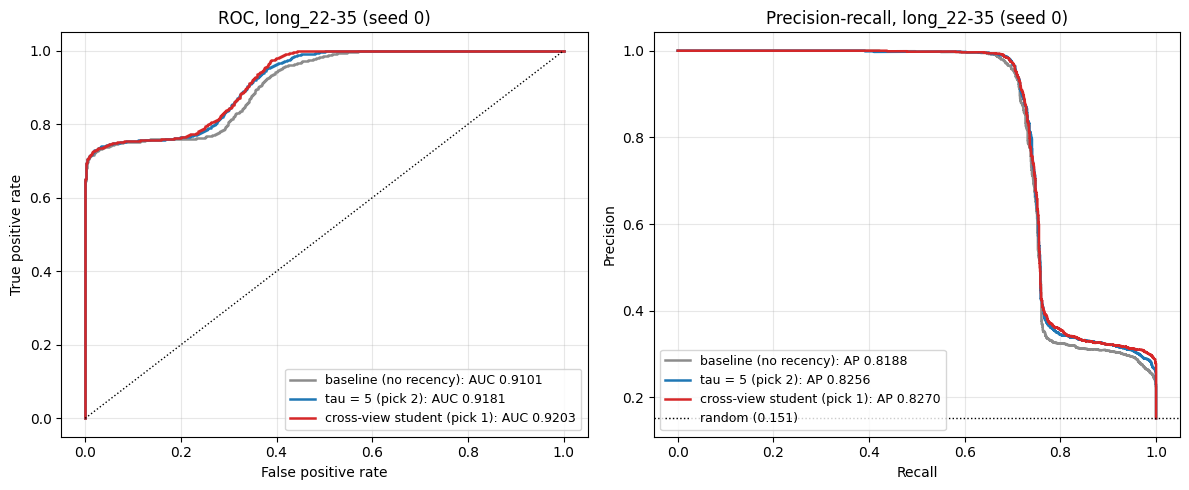

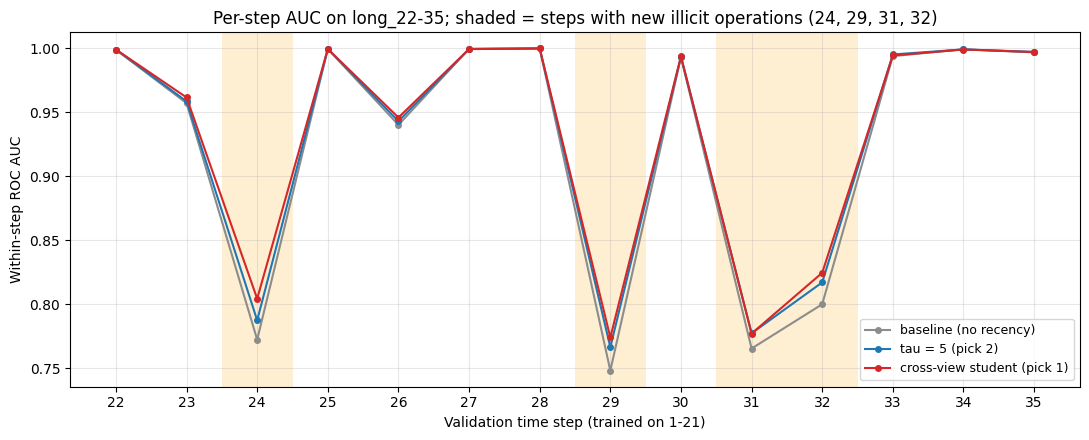

                                 22      23      24      25      26      27   28      29      30      31      32      33      34      35
baseline (no recency)        0.9989  0.9572  0.7724  0.9996  0.9403  0.9997  1.0  0.7482  0.9933  0.7655  0.8001  0.9940  0.9994  0.9969
tau = 5 (pick 2)             0.9992  0.9586  0.7875  0.9996  0.9431  0.9996  1.0  0.7666  0.9935  0.7774  0.8172  0.9953  0.9992  0.9973
cross-view student (pick 1)  0.9991  0.9617  0.8044  0.9996  0.9460  0.9995  1.0  0.7742  0.9938  0.7772  0.8247  0.9945  0.9992  0.9972


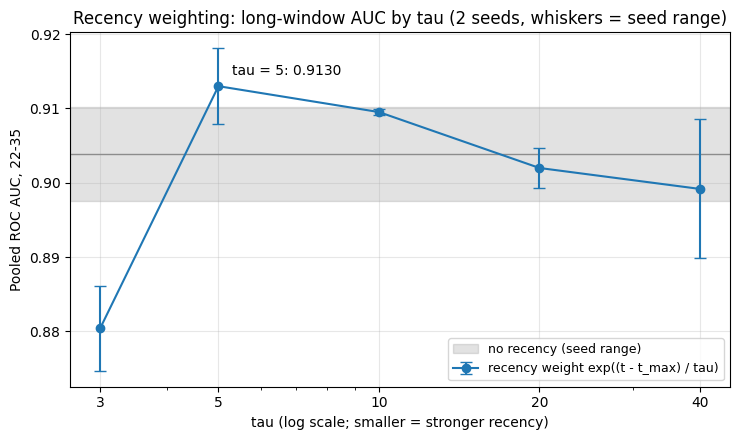

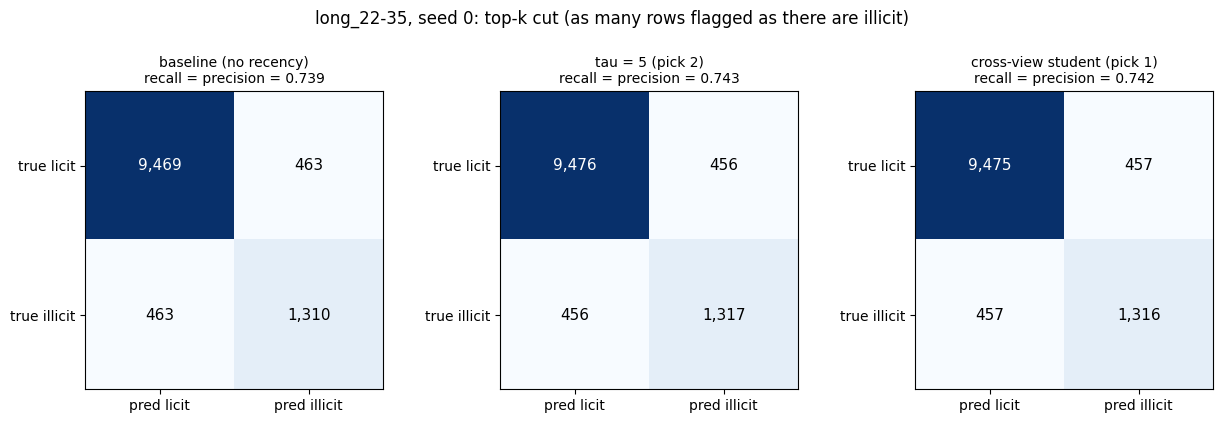

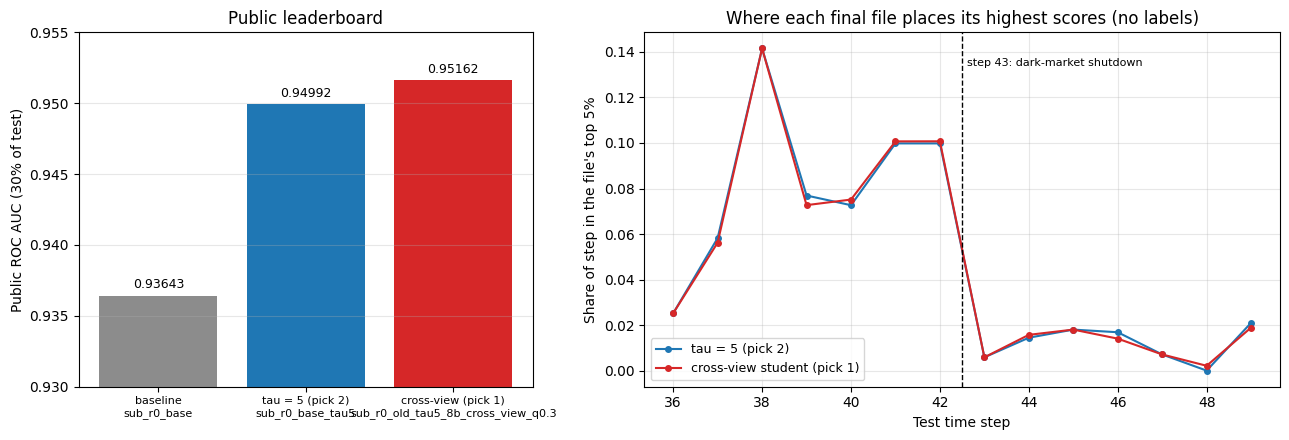

In [76]:
# ============================================================ Model performance: baseline vs the two final picks (one cell)
# needs: Part 1 Step 3f (tau_table); Part 2 Steps 6a-6b (RESULTS, CAL_RUNS, REF_NAMES, PRIMARY_WIN, REPL_WIN, NOVEL_STEPS,
#        SEEDS_V2, SPLITS_BOUNDARY); Step 8 (STUDENT_RUNS, E8_FILES, TOP_PATH, new_te, ID_COL, TARGET_COL). No retraining.

# ------------------------------------------------------------ 1. validation metrics table
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_fscore_support,
                             roc_curve, precision_recall_curve, confusion_matrix)

PERF_MODELS = {                                               # 5 paired seeds each, both boundary windows
    "baseline (no recency)":       CAL_RUNS["r0_old_unweighted"],
    "tau = 5 (pick 2)":            REF_NAMES,
    "cross-view student (pick 1)": STUDENT_RUNS["8b_cross_view"],
}
PERF_LB = {"baseline (no recency)": 0.93643, "tau = 5 (pick 2)": 0.94992, "cross-view student (pick 1)": 0.95162}
PERF_COLORS = {"baseline (no recency)": "#8c8c8c", "tau = 5 (pick 2)": "#1f77b4", "cross-view student (pick 1)": "#d62728"}
PERF_WINDOWS = [PRIMARY_WIN, REPL_WIN]


def perf_frame(name, w):
    p = RESULTS[name]["preds"]
    return p[p["window"] == w]


def point_metrics(d):
    """Ranking metrics (threshold-free) plus precision / recall / F1 at two cut-offs."""
    y, s = d["label"].to_numpy(), d["pred"].to_numpy()
    nov = d["time_step"].isin(NOVEL_STEPS).to_numpy()
    out = {"roc_auc": roc_auc_score(y, s),
           "pr_auc": average_precision_score(y, s),
           "roc_auc_familiar": roc_auc_score(y[~nov], s[~nov]),
           "roc_auc_novel": roc_auc_score(y[nov], s[nov])}
    k = int(y.sum())                                          # top-k cut: flag as many rows as there are illicit
    cuts = {"@0.5": 0.5, "@top-k": np.sort(s)[::-1][k - 1]}
    for tag, thr in cuts.items():
        pr, rc, f1, _ = precision_recall_fscore_support(y, (s >= thr).astype(int), average="binary", zero_division=0)
        out.update({f"precision{tag}": pr, f"recall{tag}": rc, f"f1{tag}": f1})
    out["accuracy@0.5"] = float(((s >= 0.5).astype(int) == y).mean())
    out["accuracy_all_licit"] = 1 - y.mean()                  # what predicting "licit" for every row would score
    return out


PERF_ROWS = []
for model, names in PERF_MODELS.items():
    for seed, n in zip(SEEDS_V2, names):
        for w in PERF_WINDOWS:
            PERF_ROWS.append({"model": model, "window": w, "seed": seed, **point_metrics(perf_frame(n, w))})
PERF = pd.DataFrame(PERF_ROWS)

cols = ["roc_auc", "pr_auc", "roc_auc_familiar", "roc_auc_novel",
        "precision@0.5", "recall@0.5", "f1@0.5", "precision@top-k", "recall@top-k", "f1@top-k",
        "accuracy@0.5", "accuracy_all_licit"]
for w in PERF_WINDOWS:
    g = PERF[PERF.window == w].groupby("model", sort=False)[cols]
    tab = g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)
    if w == PRIMARY_WIN:
        tab.insert(0, "public_lb", pd.Series(PERF_LB).astype(str))
    print(f"\n=== {w} (mean ± sd over {len(SEEDS_V2)} seeds) ===")
    print(tab.T.to_string())

print("\nReading: ROC AUC is the competition metric. PR AUC and the top-k cut show how pure the highest-ranked rows are; "
      "top-k flags exactly as many rows as there are illicit, so precision = recall = F1 there. "
      "Accuracy is shown only against the all-licit floor: with ~10% illicit it says little.")


# ------------------------------------------------------------ 2. ROC and precision-recall curves (primary window, seed 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for model, names in PERF_MODELS.items():
    d = perf_frame(names[0], PRIMARY_WIN)
    y, s = d["label"].to_numpy(), d["pred"].to_numpy()
    fpr, tpr, _ = roc_curve(y, s)
    prec, rec, _ = precision_recall_curve(y, s)
    axes[0].plot(fpr, tpr, color=PERF_COLORS[model], lw=1.8, label=f"{model}: AUC {roc_auc_score(y, s):.4f}")
    axes[1].plot(rec, prec, color=PERF_COLORS[model], lw=1.8, label=f"{model}: AP {average_precision_score(y, s):.4f}")
prev = d["label"].mean()
axes[0].plot([0, 1], [0, 1], ls=":", c="k", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC, {PRIMARY_WIN} (seed {SEEDS_V2[0]})")
axes[1].axhline(prev, ls=":", c="k", lw=1, label=f"random ({prev:.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title=f"Precision-recall, {PRIMARY_WIN} (seed {SEEDS_V2[0]})")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=9)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------ 3. AUC per validation step (primary window, mean of 5 seeds)
steps_perf = sorted(SPLITS_BOUNDARY[PRIMARY_WIN]["valid"])
per_step_perf = {}
for model, names in PERF_MODELS.items():
    vals = []
    for n in names:
        d = perf_frame(n, PRIMARY_WIN)
        vals.append({t: roc_auc_score(g["label"], g["pred"]) if g["label"].nunique() == 2 else np.nan
                     for t, g in d.groupby("time_step")})
    per_step_perf[model] = pd.DataFrame(vals).mean()
per_step_perf = pd.DataFrame(per_step_perf).reindex(steps_perf)

fig, ax = plt.subplots(figsize=(11, 4.5))
for t in NOVEL_STEPS:
    if t in steps_perf:
        ax.axvspan(t - 0.5, t + 0.5, color="#ffd27f", alpha=0.35, lw=0)
for model in PERF_MODELS:
    ax.plot(per_step_perf.index, per_step_perf[model], marker="o", ms=4, color=PERF_COLORS[model], label=model)
ax.set(xlabel="Validation time step (trained on 1-21)", ylabel="Within-step ROC AUC",
       title="Per-step AUC on long_22-35; shaded = steps with new illicit operations (24, 29, 31, 32)")
ax.set_xticks(steps_perf)
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(per_step_perf.round(4).T.to_string())


# ------------------------------------------------------------ 4. the recency curve (Part 1 Step 3f, long window 22-35)
tt = tau_table.drop(index="baseline")
taus = [int(i.replace("tau", "")) for i in tt.index]
base_row = tau_table.loc["baseline"]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axhspan(base_row["pooled_min"], base_row["pooled_max"], color="#8c8c8c", alpha=0.25, label="no recency (seed range)")
ax.axhline(base_row["pooled_mean"], color="#8c8c8c", lw=1)
ax.errorbar(taus, tt["pooled_mean"], yerr=[tt["pooled_mean"] - tt["pooled_min"], tt["pooled_max"] - tt["pooled_mean"]],
            fmt="o-", color="#1f77b4", capsize=4, label="recency weight exp((t - t_max) / tau)")
best = tt["pooled_mean"].idxmax()
ax.annotate(f"tau = {best.replace('tau', '')}: {tt.loc[best, 'pooled_mean']:.4f}", (int(best.replace('tau', '')), tt.loc[best, "pooled_mean"]),
            textcoords="offset points", xytext=(10, 8))
ax.set_xscale("log")
ax.set_xticks(taus)
ax.set_xticklabels(taus)
ax.set(xlabel="tau (log scale; smaller = stronger recency)", ylabel="Pooled ROC AUC, 22-35",
       title="Recency weighting: long-window AUC by tau (2 seeds, whiskers = seed range)")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------ 5. confusion matrices at the top-k cut (primary window, seed 0)
fig, axes = plt.subplots(1, len(PERF_MODELS), figsize=(4.2 * len(PERF_MODELS), 4))
for ax, (model, names) in zip(axes, PERF_MODELS.items()):
    d = perf_frame(names[0], PRIMARY_WIN)
    y, s = d["label"].to_numpy(), d["pred"].to_numpy()
    thr = np.sort(s)[::-1][int(y.sum()) - 1]
    cm = confusion_matrix(y, (s >= thr).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["pred licit", "pred illicit"])
    ax.set_yticks([0, 1], ["true licit", "true illicit"])
    tp, fn = cm[1, 1], cm[1, 0]
    ax.set_title(f"{model}\nrecall = precision = {tp / (tp + fn):.3f}", fontsize=10)
fig.suptitle(f"{PRIMARY_WIN}, seed {SEEDS_V2[0]}: top-k cut (as many rows flagged as there are illicit)", y=1.02)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------ 6. public leaderboard, and how each final file scores the test steps
lb = pd.Series({"baseline\nsub_r0_base": 0.93643, "tau = 5 (pick 2)\nsub_r0_base_tau5": 0.94992,
                "cross-view (pick 1)\nsub_r0_old_tau5_8b_cross_view_q0.3": 0.95162})
files_perf = {"tau = 5 (pick 2)": TOP_PATH, "cross-view student (pick 1)": E8_FILES["8b_cross_view"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
bars = axes[0].bar(range(len(lb)), lb.values, color=["#8c8c8c", "#1f77b4", "#d62728"])
for b_, v in zip(bars, lb.values):
    axes[0].text(b_.get_x() + b_.get_width() / 2, v + 0.0005, f"{v:.5f}", ha="center", fontsize=9)
axes[0].set_xticks(range(len(lb)), lb.index, fontsize=8)
axes[0].set_ylim(0.93, 0.955)
axes[0].set(ylabel="Public ROC AUC (30% of test)", title="Public leaderboard")
axes[0].grid(axis="y", alpha=0.3)

for label, path in files_perf.items():
    f = pd.read_csv(path).set_index(ID_COL)[TARGET_COL]
    step = new_te["time_step"].loc[f.index]
    share = (f.rank(pct=True) >= 0.95).groupby(step).mean()            # share of each step in the file's overall top 5%
    axes[1].plot(share.index, share.values, marker="o", ms=4, color=PERF_COLORS[label], label=label)
axes[1].axvline(42.5, ls="--", c="k", lw=1)
axes[1].text(42.6, axes[1].get_ylim()[1] * 0.9, "step 43: dark-market shutdown", fontsize=8)
axes[1].set(xlabel="Test time step", ylabel="Share of step in the file's top 5%",
            title="Where each final file places its highest scores (no labels)")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

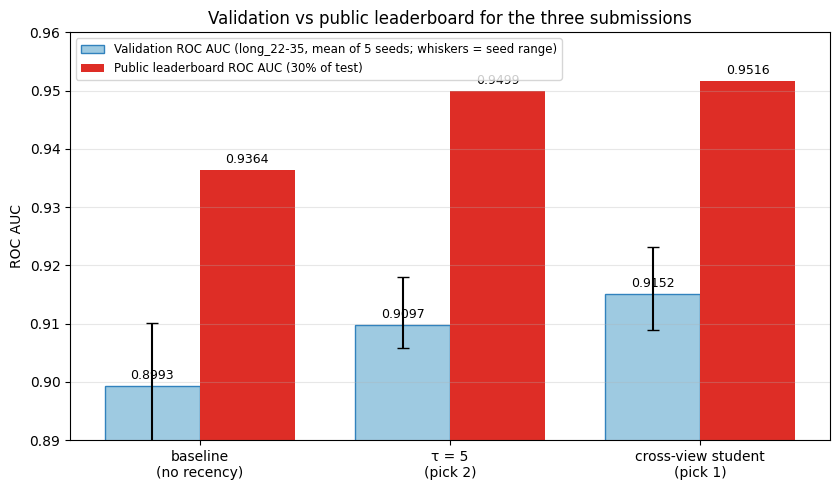

                             validation_mean  validation_gain  public_lb  lb_gain
baseline (no recency)                 0.8993           0.0000     0.9364   0.0000
tau = 5 (pick 2)                      0.9097           0.0104     0.9499   0.0135
cross-view student (pick 1)           0.9152           0.0159     0.9516   0.0152


In [77]:
# ------------------------------------------------------------ validation vs public leaderboard, three submissions
# needs: the performance cell (PERF, PERF_LB, PRIMARY_WIN)
import matplotlib.pyplot as plt

models = list(PERF_LB)                                         # baseline, tau = 5, cross-view (same order as the table)
labels = ["baseline\n(no recency)", "τ = 5\n(pick 2)", "cross-view student\n(pick 1)"]
g = PERF[PERF.window == PRIMARY_WIN].groupby("model")["roc_auc"]
val_mean = g.mean().reindex(models)
val_lo, val_hi = g.min().reindex(models), g.max().reindex(models)
lb = pd.Series(PERF_LB).reindex(models)

x, wd = np.arange(len(models)), 0.38
fig, ax = plt.subplots(figsize=(8.5, 5))
b1 = ax.bar(x - wd / 2, val_mean, wd, color="#9ecae1", edgecolor="#3182bd",
            yerr=[val_mean - val_lo, val_hi - val_mean], capsize=4,
            label=f"Validation ROC AUC ({PRIMARY_WIN}, mean of 5 seeds; whiskers = seed range)")
b2 = ax.bar(x + wd / 2, lb, wd, color="#de2d26", label="Public leaderboard ROC AUC (30% of test)")
for bars, vals in ((b1, val_mean), (b2, lb)):
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.0012, f"{v:.4f}", ha="center", fontsize=9)

ax.set_xticks(x, labels)
ax.set_ylim(0.89, 0.96)
ax.set_ylabel("ROC AUC")
ax.set_title("Validation vs public leaderboard for the three submissions")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"validation_mean": val_mean, "validation_gain": val_mean - val_mean.iloc[0],
                    "public_lb": lb, "lb_gain": lb - lb.iloc[0]}).round(4).to_string())